# Apresentação do problema

O dataset utilizado para a análise é o [Online Retail Dataset - UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail).
Suas principais características são:
 - contém dados transacionais de 01/12/2010 a 09/12/2011
 - é de uma empresa de verejo do Reino Unido
 - contém 541.909 registros

Os principais campos são:

| Campo     | Descrição                                   |
|-----------|---------------------------------------------|
| InvoiceNo       | Identificador da nota/pedido. Códigos iniciados por C indicam cancelamentos.     |
| StockCode       | Código do produto                     |
| Description     | Descrição do produto.                 |
| Quantity        | Quantidade de itens na transação.     |
| InvoiceDate     | Data e hora da transação.             |
| UnitPrice       | Preço unitário em libra esterlina.    |
| CustomerID      | Identificador do cliente.             |
| Country         | País do cliente.                      |

O objetivo desta análise de dados é responder a pergunta “Quais clientes têm maior probabilidade de comprar novamente nos próximos 60 dias e como podemos usar essa informação para priorizar ações comerciais?”.
Além disso, temos as seguintes informações acessórias para obter:

- evolução de receita
- padrões de compra
- comportamento por país
- concentração de receita
- recorrência
- evoluções/cancelamentos
- oportunidades de segmentação


Para a resolução do problema, foram utilizadas as seguintes bibliotecas:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, accuracy_score, silhouette_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression

# Extração dos dados



In [ ]:
df = pd.read_excel('Online Retail.xlsx')

In [ ]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


# Limpeza dos dados

In [ ]:
# Identificando valores nulos
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
# Removendo linhas com CustomerID nulo, pois não podem ser utilizadas para a análise
df.dropna(subset=['CustomerID'], inplace=True)

In [ ]:
# Identificando pedidos cancelados e separando para uso posterior
cancelados = df[df['InvoiceNo'].astype(str).str.startswith('C')]
cancelados

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [ ]:
# Removendo os pedidos cancelados do DataFrame principal
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [ ]:
# Removendo linhas com quantidade negativa
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

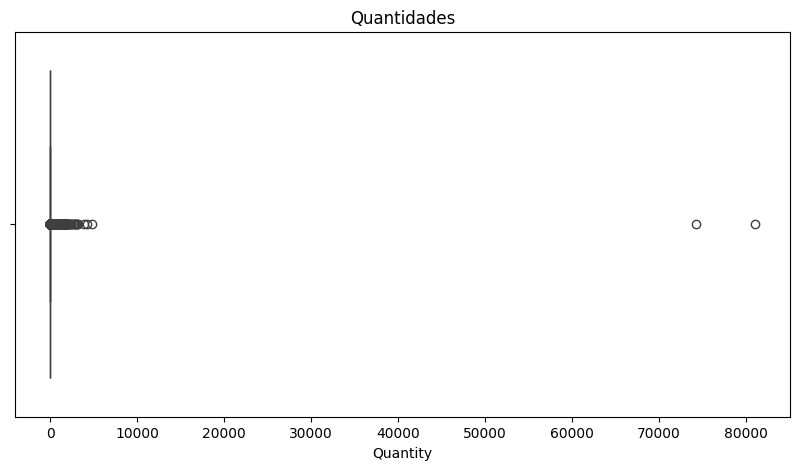

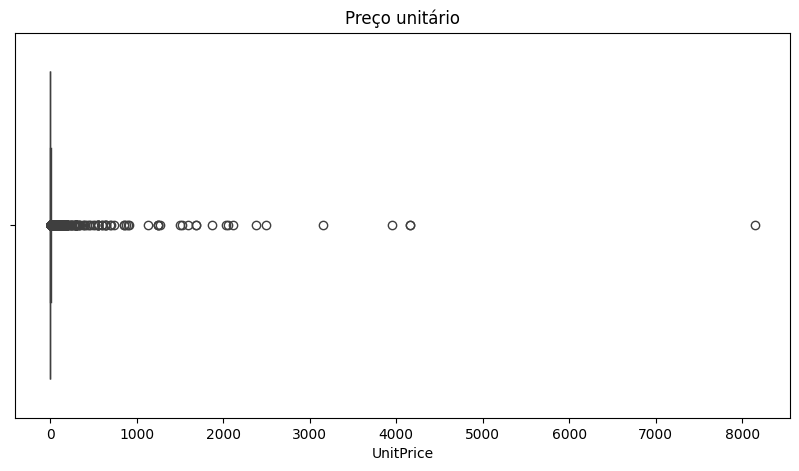

In [ ]:
# Box plot para 'Quantity'
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Quantity'])
plt.title('Quantidades')
plt.xlabel('Quantity')
plt.show()

# Box plot para 'UnitPrice'
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['UnitPrice'])
plt.title('Preço unitário')
plt.xlabel('UnitPrice')
plt.show()

In [ ]:
# Calcular IQR para a quantidade
Q1_quantity = df['Quantity'].quantile(0.10)
Q3_quantity = df['Quantity'].quantile(0.90)
IQR_quantity = Q3_quantity - Q1_quantity

lower_bound_quantity = Q1_quantity - 1.5 * IQR_quantity
upper_bound_quantity = Q3_quantity + 1.5 * IQR_quantity

print(f"Limites de Outlier para quantidade: ({lower_bound_quantity}, {upper_bound_quantity})")

# Calcular IQR para o preço unitário
Q1_unitprice = df['UnitPrice'].quantile(0.10)
Q3_unitprice = df['UnitPrice'].quantile(0.90)
IQR_unitprice = Q3_unitprice - Q1_unitprice

lower_bound_unitprice = Q1_unitprice - 1.5 * IQR_unitprice
upper_bound_unitprice = Q3_unitprice + 1.5 * IQR_unitprice

print(f"Limites de Outlier para preço unitário: ({lower_bound_unitprice}, {upper_bound_unitprice})")

Limites de Outlier para quantidade: (-33.5, 58.5)
Limites de Outlier para preço unitário: (-8.149999999999999, 15.049999999999999)


In [ ]:
# Removendo outliers
df = df[(df['Quantity'] <= upper_bound_quantity) & (df['UnitPrice'] <= upper_bound_unitprice)]

print(f"DataFrame após remoção de outliers: {df.shape[0]} linhas")

DataFrame após remoção de outliers: 382861 linhas


In [ ]:
# Verificando os tipos de variáveis
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 382861 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    382861 non-null  object        
 1   StockCode    382861 non-null  object        
 2   Description  382861 non-null  object        
 3   Quantity     382861 non-null  int64         
 4   InvoiceDate  382861 non-null  datetime64[ns]
 5   UnitPrice    382861 non-null  float64       
 6   CustomerID   382861 non-null  float64       
 7   Country      382861 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 26.3+ MB


# Análise Exploratória

## Informações gerais do negócio

In [ ]:
# Calcular a Receita por transação
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Revenue']

,Revenue
0,15.30
1,20.34
2,22.00
3,20.34
4,20.34
...,...
541904,10.20
541905,12.60
541906,16.60
541907,16.60


In [ ]:
# Número de pedidos (não cancelados)
num_orders = df['InvoiceNo'].nunique()

print(f"Número de pedidos não cancelados: {num_orders:}")

Número de pedidos não cancelados: 17626


In [ ]:
# Número de clientes
num_customers = df['CustomerID'].nunique()

print(f"Número de clientes: {num_customers:}")

Número de clientes: 4257


In [ ]:
# Ticket Médio
total_revenue = df['Revenue'].sum()
average_ticket = total_revenue / num_orders


print(f"Ticket médio: £ {average_ticket: .2f}")

Ticket médio: £  338.77


In [ ]:
# Itens por Pedido
total_quantity = df['Quantity'].sum()
items_per_order = total_quantity / num_orders


print(f"Itens por pedido: {items_per_order:,.2f}")

Itens por pedido: 181.39


In [ ]:
# Frequência de Compra (Número de Pedidos / Número de Clientes)
purchase_frequency = num_orders / num_customers


print(f"Frequência de compra (Pedidos por Cliente): {purchase_frequency:,.2f}")

Frequência de compra (Pedidos por Cliente): 4.14


In [ ]:
# Recorrência (clientes que compraram mais de uma vez)
customer_orders_count = df.groupby('CustomerID')['InvoiceNo'].nunique()
recurring_customers = customer_orders_count[customer_orders_count > 1].count()
recurrence_rate = (recurring_customers / num_customers) * 100


print(f"Taxa de Recorrência: {recurrence_rate:,.2f}%")

Taxa de Recorrência: 65.09%


In [ ]:
# Número de pedidos por mês
monthly_orders = df.groupby(df['InvoiceDate'].dt.to_period('M'))['InvoiceNo'].nunique().reset_index()
monthly_orders['InvoiceDate'] = monthly_orders['InvoiceDate'].astype(str)
monthly_orders.columns = ['Mês', 'Nº Pedidos']
display(monthly_orders.sort_values(by='Nº Pedidos', ascending=False))

,Mês,Nº Pedidos
11,2011-11,2547
10,2011-10,1830
9,2011-09,1674
5,2011-05,1473
0,2010-12,1334
6,2011-06,1328
7,2011-07,1267
3,2011-03,1254
8,2011-08,1206
4,2011-04,1077


/tmp/ipykernel_439/1332638066.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mês', y='Nº Pedidos', data=monthly_orders.sort_values(by='Nº Pedidos', ascending=False), palette='viridis')


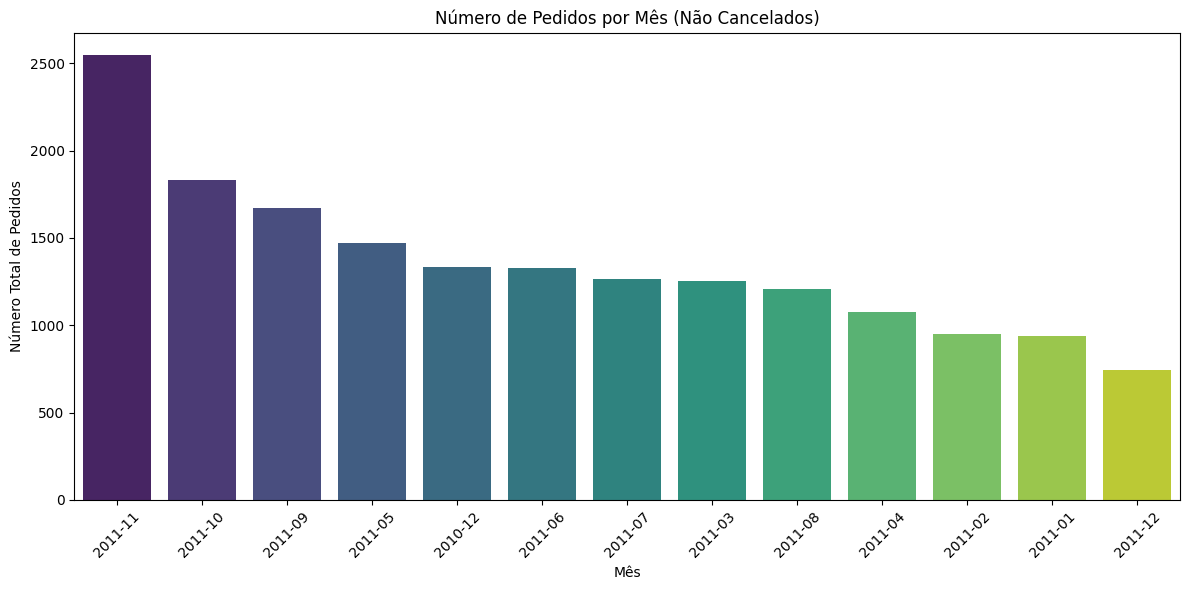

In [ ]:
# Gráfico de número de pedidos efetivos por mês

plt.figure(figsize=(12, 6))
sns.barplot(x='Mês', y='Nº Pedidos', data=monthly_orders.sort_values(by='Nº Pedidos', ascending=False), palette='viridis')
plt.title('Número de Pedidos por Mês (Não Cancelados)')
plt.xlabel('Mês')
plt.ylabel('Número Total de Pedidos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

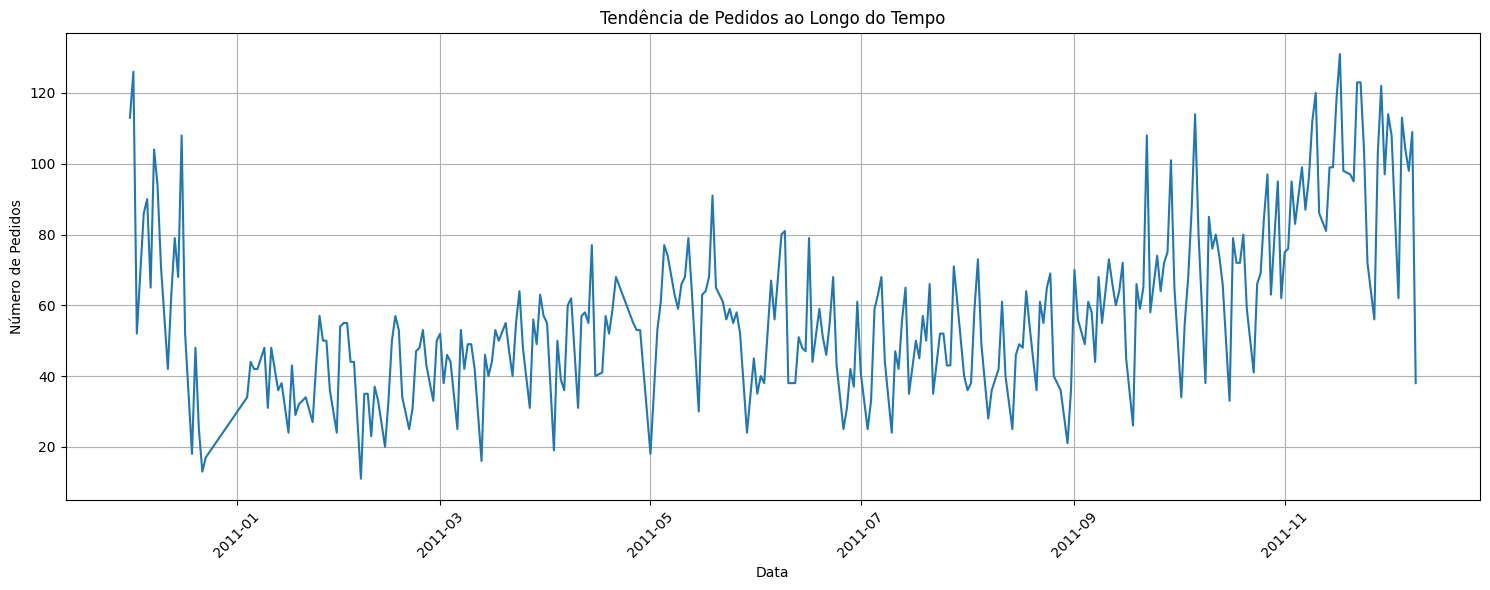

In [ ]:
# Tendência de pedidos ao longo do tempo

# Extrair a data da InvoiceDate
df['InvoiceDateOnly'] = df['InvoiceDate'].dt.date

# Agrupar por data e contar o número de pedidos únicos
daily_orders = df.groupby('InvoiceDateOnly')['InvoiceNo'].nunique().reset_index()
daily_orders['InvoiceDateOnly'] = pd.to_datetime(daily_orders['InvoiceDateOnly'])

# Criar o gráfico de linha
plt.figure(figsize=(15, 6))
sns.lineplot(x='InvoiceDateOnly', y='InvoiceNo', data=daily_orders)
plt.title('Tendência de Pedidos ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Número de Pedidos')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

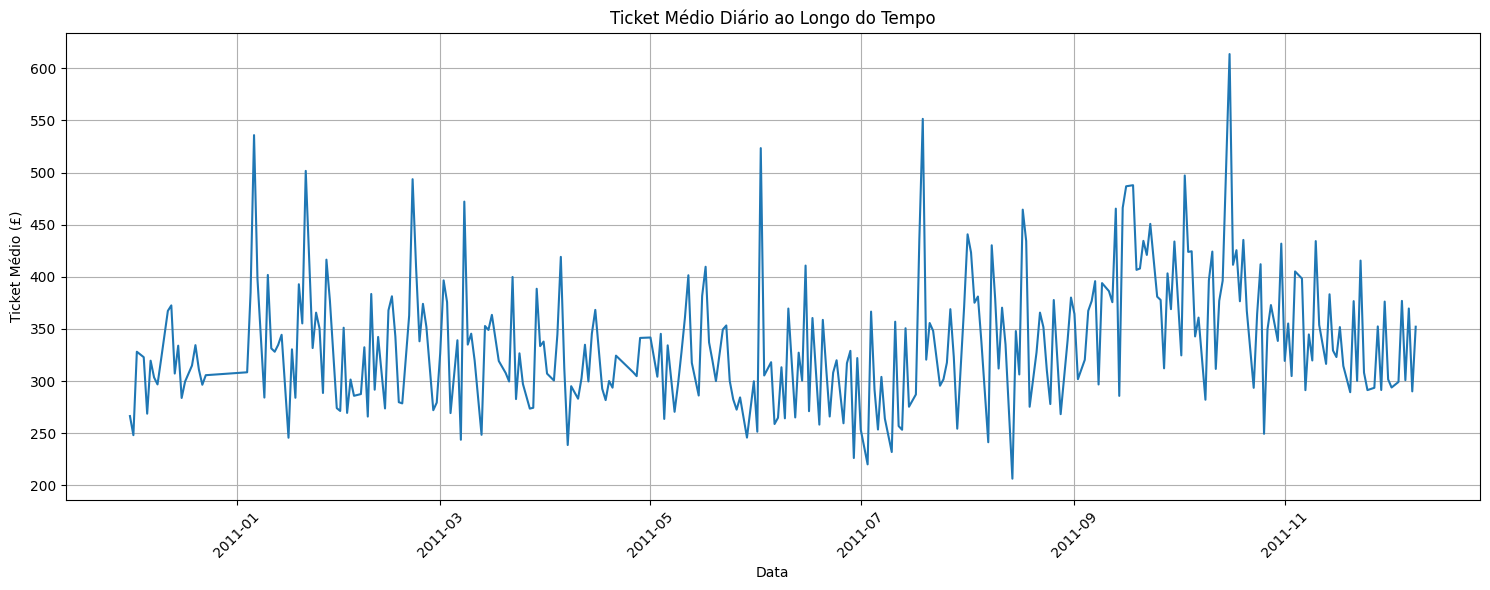

In [ ]:
# Calcular a receita total por dia
daily_revenue = df.groupby('InvoiceDateOnly')['Revenue'].sum().reset_index()

# Contar o número de pedidos únicos por dia
daily_unique_orders = df.groupby('InvoiceDateOnly')['InvoiceNo'].nunique().reset_index()
daily_unique_orders.rename(columns={'InvoiceNo': 'NumUniqueOrders'}, inplace=True)

# Juntar os dois DataFrames
daily_metrics = pd.merge(daily_revenue, daily_unique_orders, on='InvoiceDateOnly')

# Calcular o ticket médio por dia
daily_metrics['AverageTicket'] = daily_metrics['Revenue'] / daily_metrics['NumUniqueOrders']

# Converter InvoiceDateOnly para datetime para plotagem
daily_metrics['InvoiceDateOnly'] = pd.to_datetime(daily_metrics['InvoiceDateOnly'])

# Criar o gráfico de linha
plt.figure(figsize=(15, 6))
sns.lineplot(x='InvoiceDateOnly', y='AverageTicket', data=daily_metrics)
plt.title('Ticket Médio Diário ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Ticket Médio (£)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calcular a receita total por país
sales_by_country = df.groupby('Country')['Revenue'].sum().reset_index()
sales_by_country = sales_by_country[sales_by_country['Country'] != 'United Kingdom']
sales_by_country = sales_by_country.sort_values(by='Revenue', ascending=False).reset_index(drop=True)

print("Top 10 Países por Receita de Vendas (Excluindo Reino Unido):")
# Exibir os próximos 10 países
display(sales_by_country.head(10))

Top 10 Países por Receita de Vendas (Excluindo Reino Unido):


,Country,Revenue
0,Germany,184288.57
1,EIRE,165157.10
2,France,157013.74
3,Netherlands,63226.12
4,Switzerland,45164.21
5,Spain,41402.84
6,Belgium,38035.84
7,Australia,36307.99
8,Norway,27913.17
9,Portugal,25813.88


/tmp/ipykernel_439/1760773291.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Revenue', y='Country', data=sales_by_country[sales_by_country['Country'] != 'United Kingdom'].head(10), palette='magma')


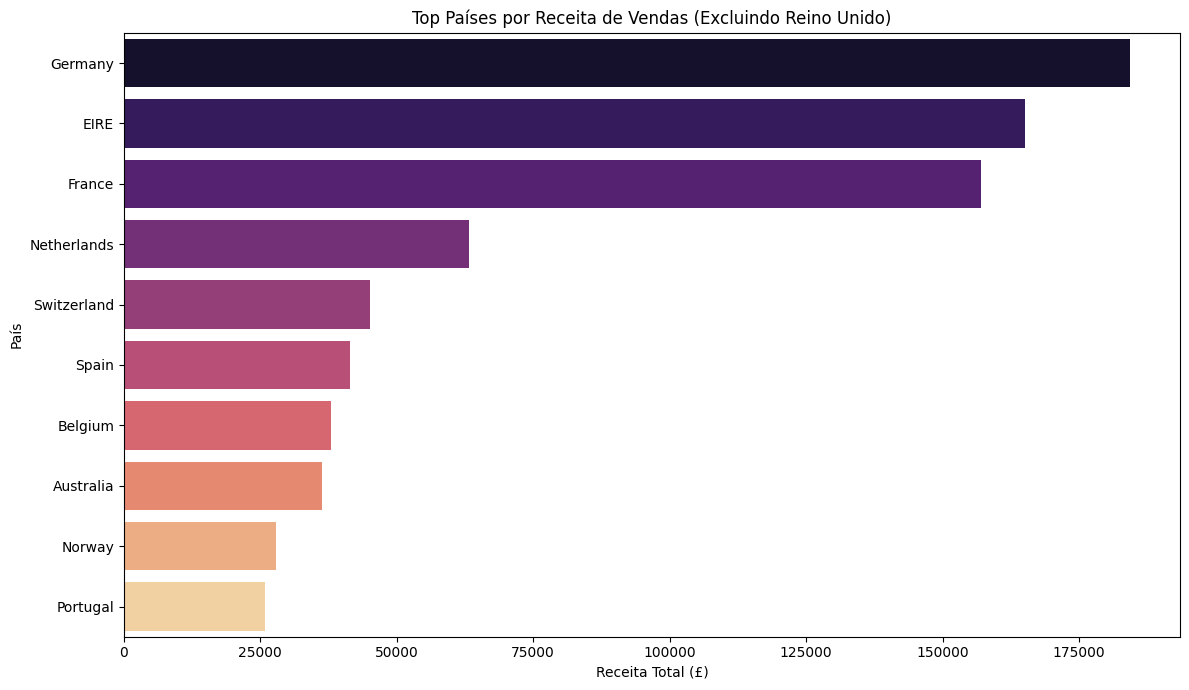

In [ ]:

# Criar um gráfico de barras para visualizar as vendas por país (excluindo Reino Unido)
plt.figure(figsize=(12, 7))
sns.barplot(x='Revenue', y='Country', data=sales_by_country[sales_by_country['Country'] != 'United Kingdom'].head(10), palette='magma')
plt.title('Top Países por Receita de Vendas (Excluindo Reino Unido)')
plt.xlabel('Receita Total (£)')
plt.ylabel('País')
plt.tight_layout()
plt.show()

## Cancelamentos

In [ ]:
# Calcular o número total de pedidos cancelados
total_cancelled_orders = len(cancelados)

# Calcular o número total de pedidos (não cancelados + cancelados)
total_all_orders = num_orders + total_cancelled_orders

# Calcular a taxa de cancelamento geral
overall_cancellation_rate = (total_cancelled_orders / total_all_orders) * 100

print(f"Número total de pedidos não cancelados: {num_orders:,}")
print(f"Número total de pedidos cancelados: {total_cancelled_orders:,}")
print(f"Número total de todos os pedidos: {total_all_orders:,}")
print(f"Taxa de Cancelamento Geral: {overall_cancellation_rate:,.2f}%")

Número total de pedidos não cancelados: 17,626
Número total de pedidos cancelados: 8,905
Número total de todos os pedidos: 26,531
Taxa de Cancelamento Geral: 33.56%


In [ ]:
# Cancelamentos por mês
monthly_cancelled_orders = cancelados.groupby(cancelados['InvoiceDate'].dt.to_period('M'))['InvoiceNo'].nunique().reset_index()
monthly_cancelled_orders['InvoiceDate'] = monthly_cancelled_orders['InvoiceDate'].astype(str)
monthly_cancelled_orders.columns = ['Mês', 'Cancelamentos']
display(monthly_cancelled_orders.sort_values(by='Cancelamentos', ascending=False))

,Mês,Cancelamentos
11,2011-11,428
10,2011-10,334
9,2011-09,322
6,2011-06,314
0,2010-12,308
3,2011-03,298
5,2011-05,294
8,2011-08,263
7,2011-07,262
1,2011-01,249


In [ ]:
# Extrair a data da InvoiceDate do DataFrame de cancelados
cancelados['InvoiceDateOnly'] = cancelados['InvoiceDate'].dt.date

# Agrupar por data e contar o número de pedidos cancelados únicos
daily_cancelled_orders = cancelados.groupby('InvoiceDateOnly')['InvoiceNo'].nunique().reset_index()
daily_cancelled_orders['InvoiceDateOnly'] = pd.to_datetime(daily_cancelled_orders['InvoiceDateOnly'])

# 10 dias em que mais houve cancelamentos
top_10_cancelled_days = daily_cancelled_orders.sort_values(by='InvoiceNo', ascending=False).head(10)
top_10_cancelled_days.columns = ['Data', 'Qnt Cancelados']
display(top_10_cancelled_days)

,Data,Qnt Cancelados
246,2011-10-06,64
11,2010-12-14,50
294,2011-12-01,46
51,2011-02-11,44
283,2011-11-18,39
271,2011-11-04,38
215,2011-08-31,38
276,2011-11-10,36
293,2011-11-30,35
71,2011-03-07,34


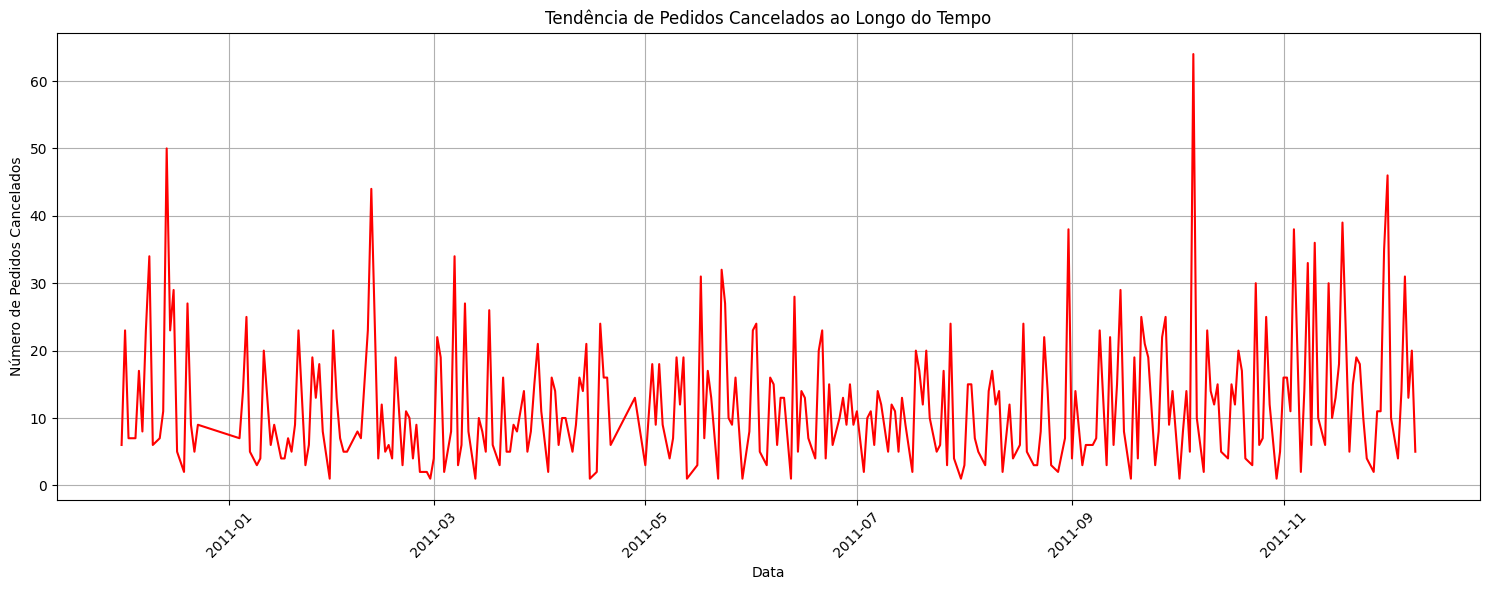

In [ ]:
# Extrair a data da InvoiceDate do DataFrame de cancelados
cancelados['InvoiceDateOnly'] = cancelados['InvoiceDate'].dt.date

# Agrupar por data e contar o número de pedidos cancelados únicos
daily_cancelled_orders = cancelados.groupby('InvoiceDateOnly')['InvoiceNo'].nunique().reset_index()
daily_cancelled_orders['InvoiceDateOnly'] = pd.to_datetime(daily_cancelled_orders['InvoiceDateOnly'])

# Renomear as colunas para o plot
daily_cancelled_orders.columns = ['Data', 'Qnt Cancelados']

# Criar o gráfico de linha para pedidos cancelados
plt.figure(figsize=(15, 6))
sns.lineplot(x='Data', y='Qnt Cancelados', data=daily_cancelled_orders, color='red')
plt.title('Tendência de Pedidos Cancelados ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Número de Pedidos Cancelados')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Merge dos DataFrames de pedidos totais e pedidos cancelados
# Temporarily rename columns in daily_cancelled_orders to match for merge and suffixing
daily_cancelled_orders_temp = daily_cancelled_orders.rename(columns={'Data': 'InvoiceDateOnly', 'Qnt Cancelados': 'InvoiceNo'})
cancellation_rates_df = pd.merge(daily_orders, daily_cancelled_orders_temp, on='InvoiceDateOnly', suffixes=('_total', '_cancelled'))

# Calcular a taxa de cancelamento diária
cancellation_rates_df['CancellationRate'] = (cancellation_rates_df['InvoiceNo_cancelled'] / cancellation_rates_df['InvoiceNo_total']) * 100

# Renomear as colunas
cancellation_rates_df.columns = ['Data', 'Nº Total', 'Nº Cancelados', 'Rate']

# Exibir as primeiras linhas e informações
display(cancellation_rates_df.head())

,Data,Nº Total,Nº Cancelados,Rate
0,2010-12-01,113,6,5.309735
1,2010-12-02,126,23,18.253968
2,2010-12-03,52,7,13.461538
3,2010-12-05,86,7,8.139535
4,2010-12-06,90,17,18.888889


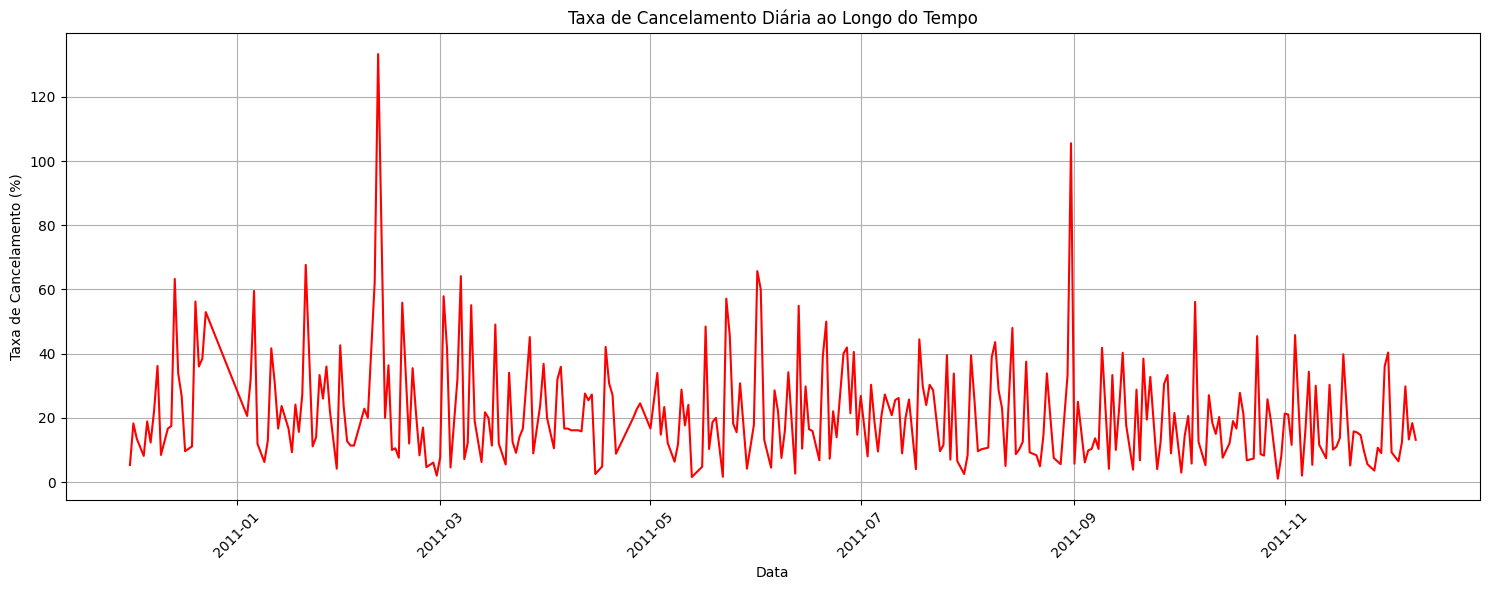

In [ ]:
# Criar o gráfico de linha para a taxa de cancelamento
plt.figure(figsize=(15, 6))
sns.lineplot(x='Data', y='Rate', data=cancellation_rates_df, color='red')
plt.title('Taxa de Cancelamento Diária ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Taxa de Cancelamento (%)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Merge dos DataFrames de pedidos totais e pedidos cancelados por mês
monthly_comparison = pd.merge(monthly_orders, monthly_cancelled_orders, left_on='Mês', right_on='Mês', how='left')
monthly_comparison['Cancelamentos'] = monthly_comparison['Cancelamentos'].fillna(0)
monthly_comparison.columns = ['Mês', 'Nº Pedidos', 'Cancelamentos']
display(monthly_comparison.sort_values(by='Mês'))

,Mês,Nº Pedidos,Cancelamentos
0,2010-12,1334,308
1,2011-01,941,249
2,2011-02,949,204
3,2011-03,1254,298
4,2011-04,1077,235
5,2011-05,1473,294
6,2011-06,1328,314
7,2011-07,1267,262
8,2011-08,1206,263
9,2011-09,1674,322


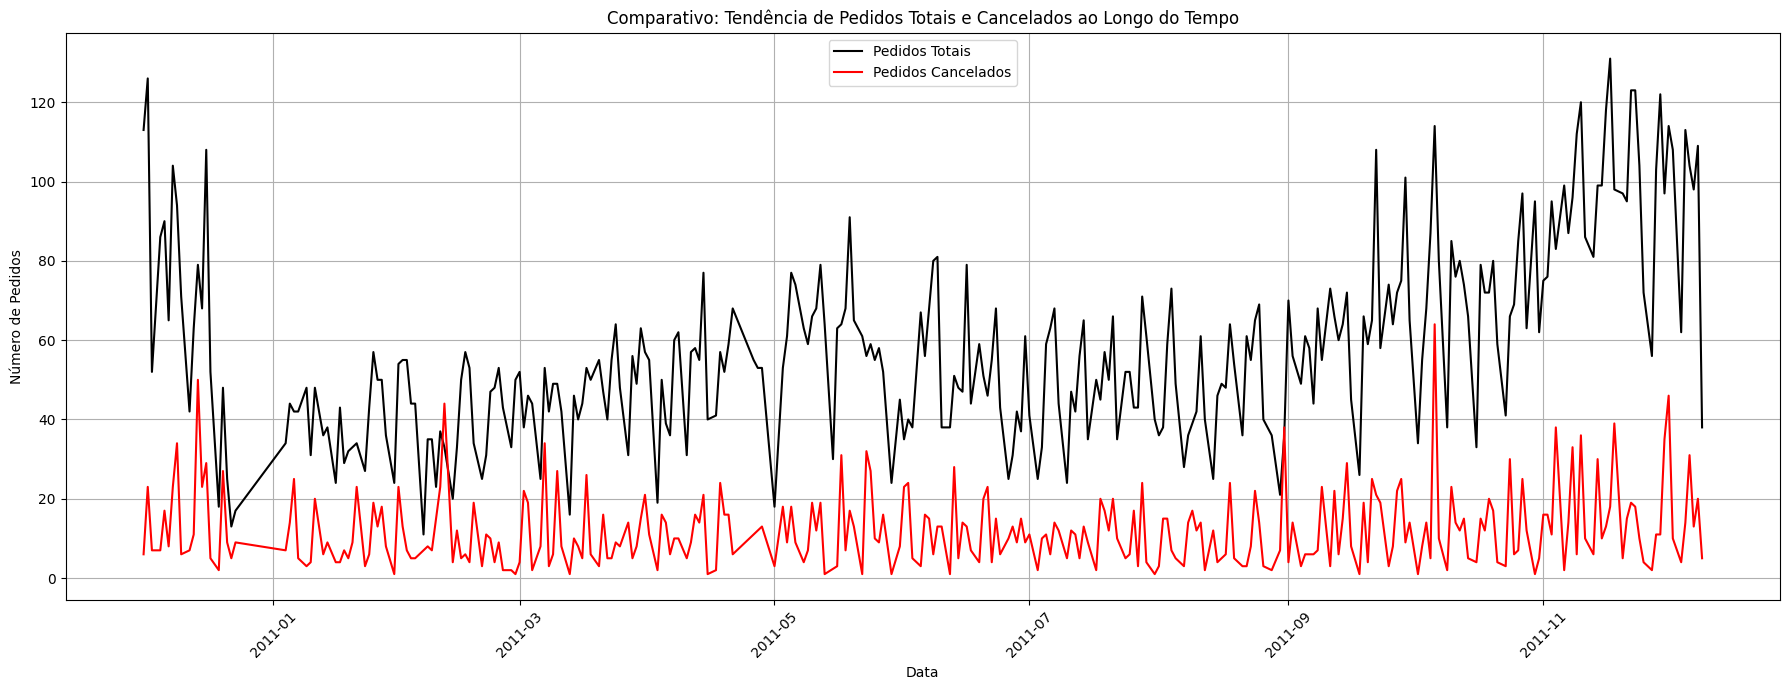

In [ ]:
# Criar o gráfico de linha para pedidos totais e cancelados
plt.figure(figsize=(18, 7))

sns.lineplot(x='InvoiceDateOnly', y='InvoiceNo', data=daily_orders, label='Pedidos Totais', color='black')
sns.lineplot(x='Data', y='Qnt Cancelados', data=daily_cancelled_orders, label='Pedidos Cancelados', color='red')

plt.title('Comparativo: Tendência de Pedidos Totais e Cancelados ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Número de Pedidos')
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

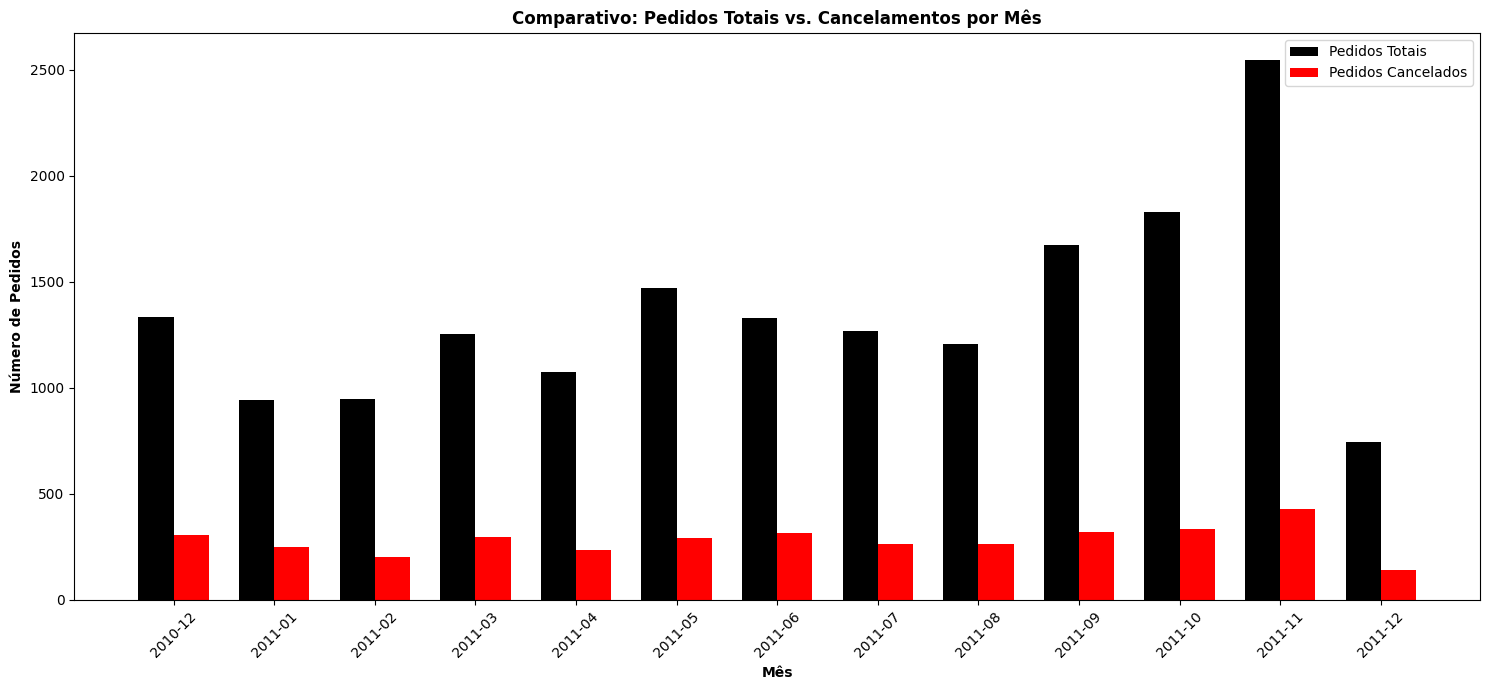

In [ ]:
# Criar o gráfico de barras comparativo
plt.figure(figsize=(15, 7))

bar_width = 0.35
r = np.arange(len(monthly_comparison['Mês']))

plt.bar(r, monthly_comparison['Nº Pedidos'], color='black', width=bar_width, label='Pedidos Totais')
plt.bar(r + bar_width, monthly_comparison['Cancelamentos'], color='red', width=bar_width, label='Pedidos Cancelados')

plt.xlabel('Mês', fontweight='bold')
plt.ylabel('Número de Pedidos', fontweight='bold')
plt.title('Comparativo: Pedidos Totais vs. Cancelamentos por Mês', fontweight='bold')
plt.xticks(r + bar_width / 2, monthly_comparison['Mês'], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_439/472516808.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mês', y='Cancelamentos', data=monthly_cancelled_orders.sort_values(by='Cancelamentos', ascending=False), palette='magma')


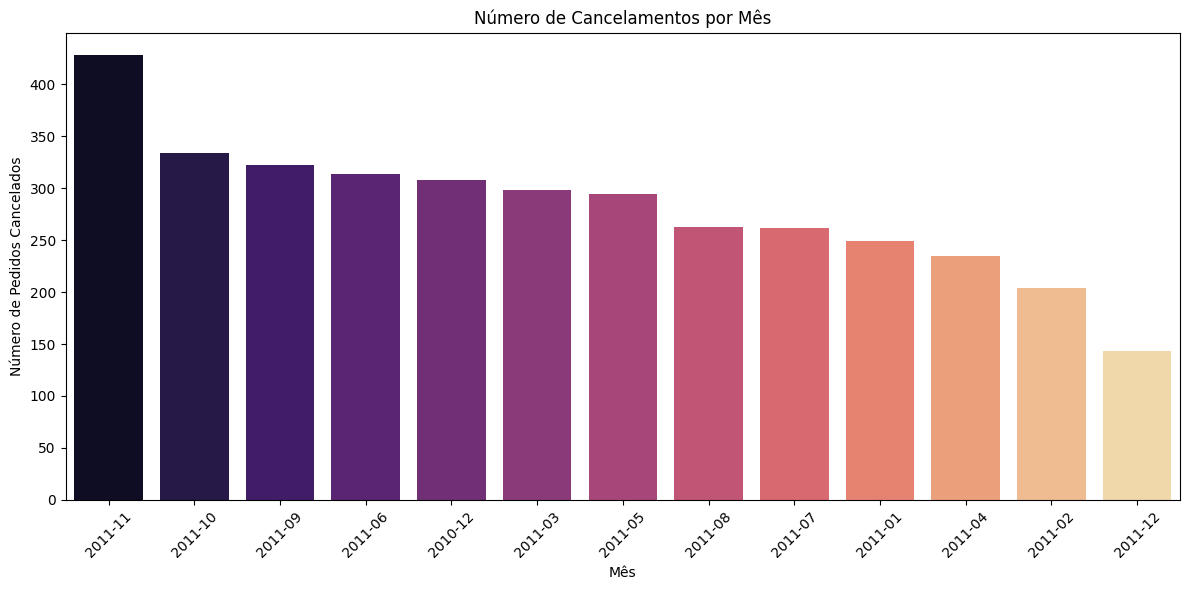

In [ ]:
# Número de cancelamentos por ordem
plt.figure(figsize=(12, 6))
sns.barplot(x='Mês', y='Cancelamentos', data=monthly_cancelled_orders.sort_values(by='Cancelamentos', ascending=False), palette='magma')
plt.title('Número de Cancelamentos por Mês')
plt.xlabel('Mês')
plt.ylabel('Número de Pedidos Cancelados')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_439/741919187.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mês', y='Cancelamentos', data=monthly_cancelled_orders.sort_values(by='Mês', ascending=False), palette='magma')


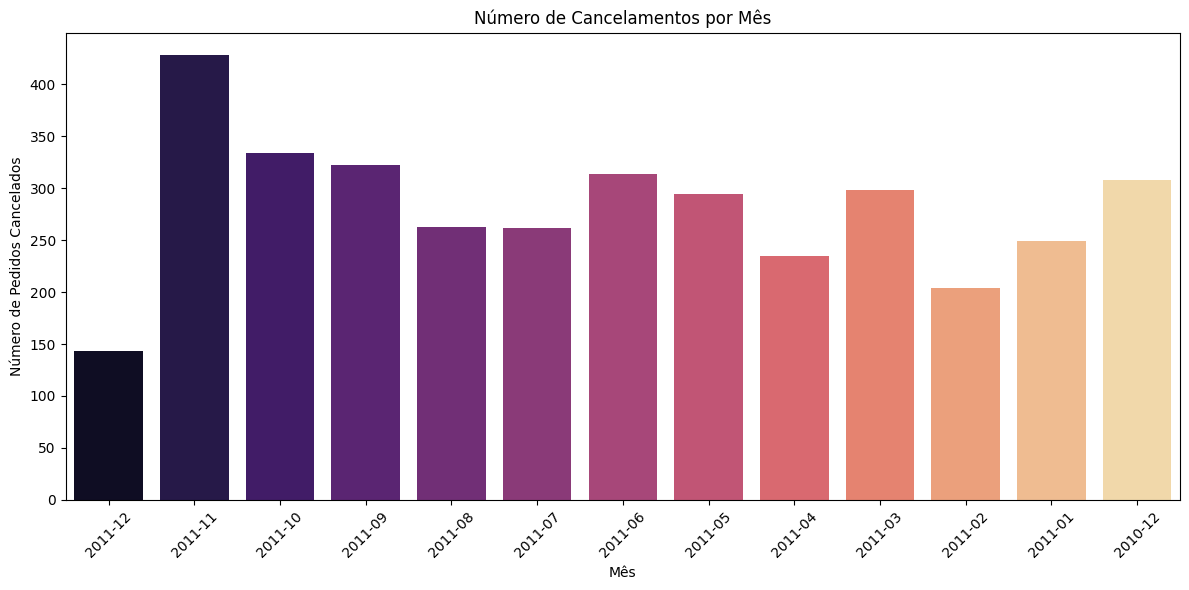

In [ ]:
# Sazonalidade do número de cancelamentos
plt.figure(figsize=(12, 6))
sns.barplot(x='Mês', y='Cancelamentos', data=monthly_cancelled_orders.sort_values(by='Mês', ascending=False), palette='magma')
plt.title('Número de Cancelamentos por Mês')
plt.xlabel('Mês')
plt.ylabel('Número de Pedidos Cancelados')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top Países por Número de Cancelamentos:


,País,Nº de Cancelamentos
1,Germany,146
2,France,69
3,EIRE,59
4,Belgium,21
5,Switzerland,20
6,Italy,17
7,Spain,15
8,Portugal,13
9,Australia,12
10,Sweden,10


/tmp/ipykernel_439/3121801020.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Nº de Cancelamentos', y='País', data=cancelled_by_country.head(10), palette='Reds_d')


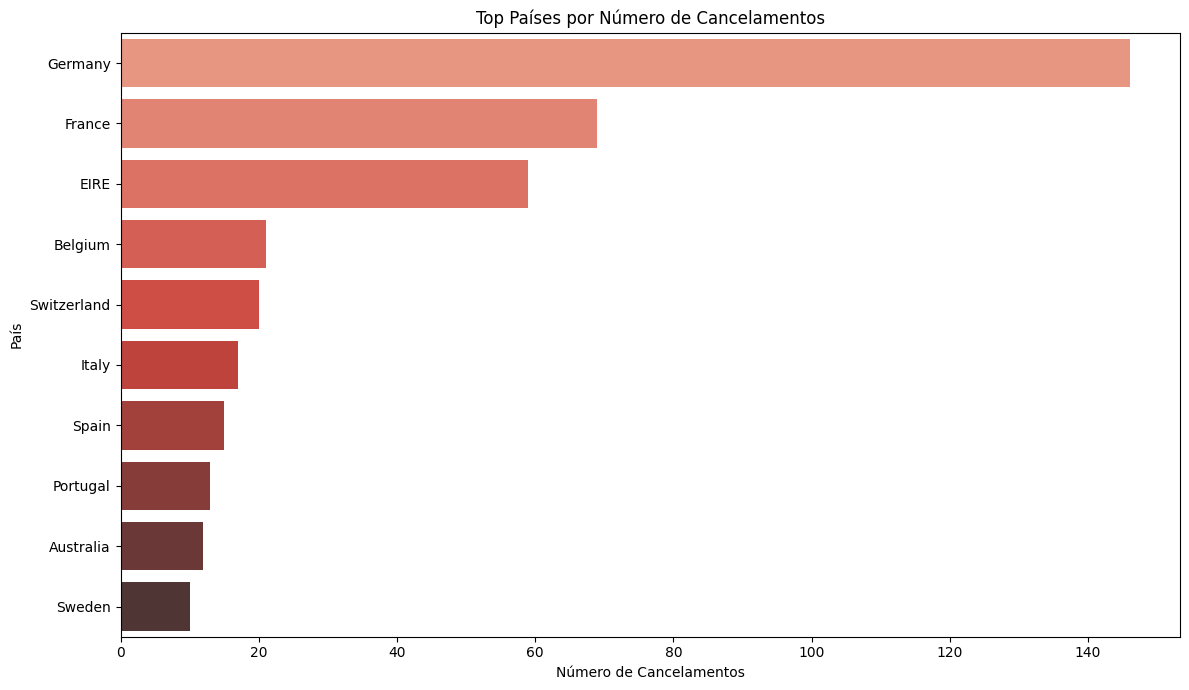

In [ ]:
# Calcular o número de cancelamentos por país
cancelled_by_country = cancelados.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False).reset_index()
cancelled_by_country.columns = ['País', 'Nº de Cancelamentos']
cancelled_by_country = cancelled_by_country[cancelled_by_country['País'] != 'United Kingdom']

print("Top Países por Número de Cancelamentos:")
display(cancelled_by_country.head(10))

# Criar um gráfico de barras para visualizar os cancelamentos por país
plt.figure(figsize=(12, 7))
sns.barplot(x='Nº de Cancelamentos', y='País', data=cancelled_by_country.head(10), palette='Reds_d')
plt.title('Top Países por Número de Cancelamentos')
plt.xlabel('Número de Cancelamentos')
plt.ylabel('País')
plt.tight_layout()
plt.show()

## Itens

In [ ]:
# Identificar os itens mais cancelados
cancelled_items = cancelados.groupby('Description')['Quantity'].sum().abs().sort_values(ascending=False).head(15)

# Exibir os itens mais cancelados
print("10 itens mais cancelados:")
cancelled_items.index.name = 'Descrição'
cancelled_items.name = 'Qnt'
display(cancelled_items.reset_index())

10 itens mais cancelados:


,Descrição,Qnt
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,74494
2,ROTATING SILVER ANGELS T-LIGHT HLDR,9367
3,Manual,3995
4,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150
5,PINK BLUE FELT CRAFT TRINKET BOX,2617
6,WHITE HANGING HEART T-LIGHT HOLDER,2578
7,GIN + TONIC DIET METAL SIGN,2030
8,HERB MARKER BASIL,1527
9,FELTCRAFT DOLL MOLLY,1447


/tmp/ipykernel_439/3238705048.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Qnt', y='Descrição', data=cancelled_items.reset_index().iloc[2:], palette='rocket')


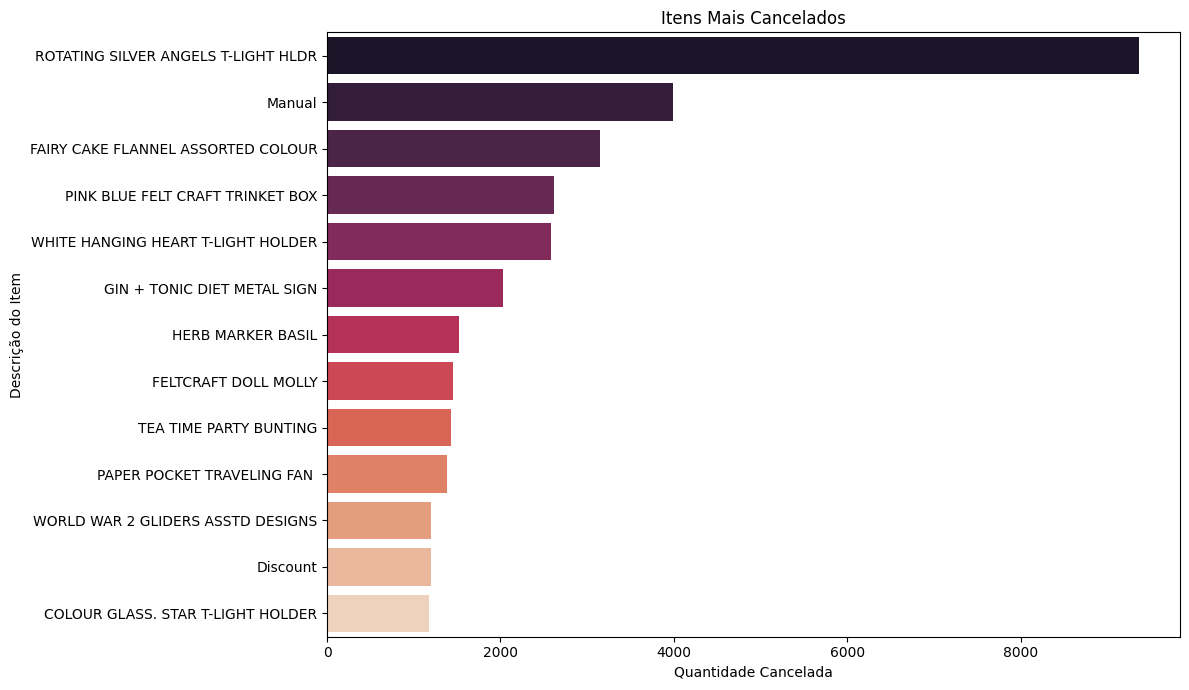

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(x='Qnt', y='Descrição', data=cancelled_items.reset_index().iloc[2:], palette='rocket')
plt.title('Itens Mais Cancelados')
plt.xlabel('Quantidade Cancelada')
plt.ylabel('Descrição do Item')
plt.tight_layout()
plt.show()

In [ ]:
# Calcular o preço médio por item
item_prices = df.groupby('Description')['UnitPrice'].mean().reset_index()

# Estatísticas descritivas para o preço unitário dos itens
print("Estatísticas Descritivas para o Preço Unitário dos Itens:")
display(item_prices['UnitPrice'].describe())

Estatísticas Descritivas para o Preço Unitário dos Itens:


,UnitPrice
count,3824.000000
mean,2.908813
std,2.788447
min,0.001000
25%,1.002679
50%,1.950000
75%,3.799476
max,15.000000


In [ ]:
# Contar o número total de itens únicos
num_unique_items = df['Description'].nunique()

print(f"Número total de itens únicos: {num_unique_items}")

Número total de itens únicos: 3824


In [ ]:
# Identificar os itens mais comprados
purchased_items = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

# Renomear o índice e a série para 'Descrição' e 'Qnt' para melhor visualização
purchased_items.index.name = 'Descrição'
purchased_items.name = 'Qnt'

# Exibir os itens mais comprados
print("10 itens mais comprados:")
display(purchased_items.reset_index())

10 itens mais comprados:


,Descrição,Qnt
0,ASSORTED COLOUR BIRD ORNAMENT,20002
1,WHITE HANGING HEART T-LIGHT HOLDER,18618
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,17023
3,PACK OF 72 RETROSPOT CAKE CASES,16293
4,JUMBO BAG RED RETROSPOT,14921
5,LUNCH BAG RED RETROSPOT,11597
6,PARTY BUNTING,10961
7,VICTORIAN GLASS HANGING T-LIGHT,10278
8,RABBIT NIGHT LIGHT,10194
9,HEART OF WICKER SMALL,10023


/tmp/ipykernel_439/2337732031.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Qnt', y='Descrição', data=purchased_items.reset_index(), palette='viridis')


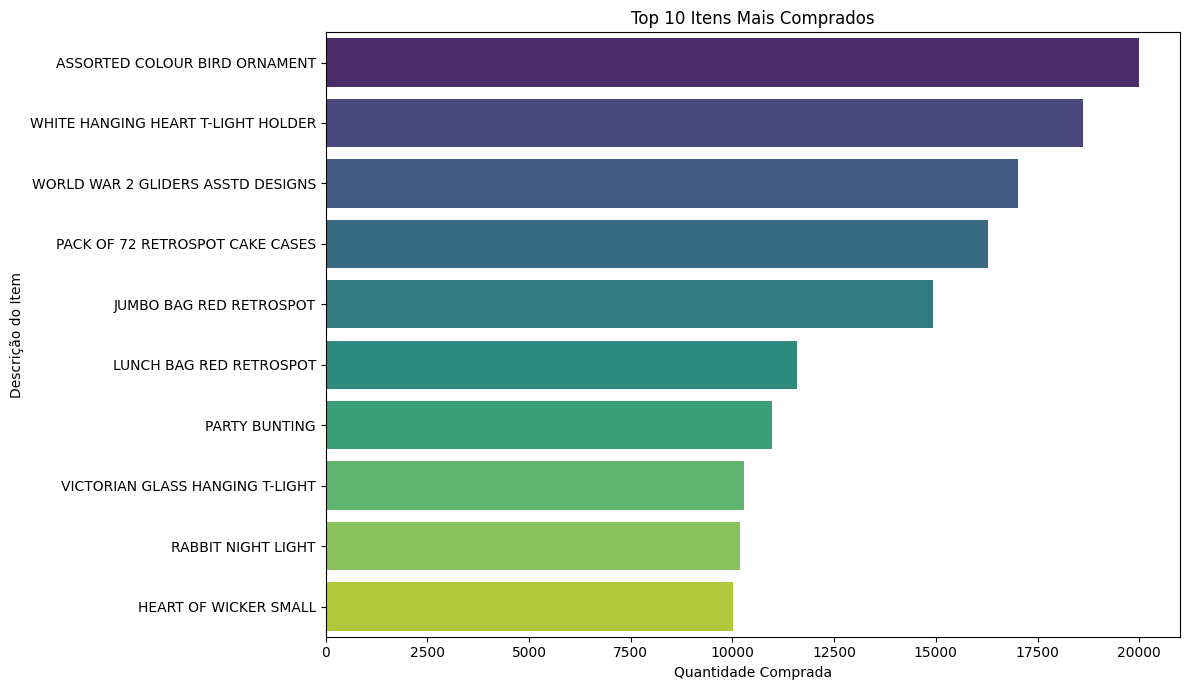

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(x='Qnt', y='Descrição', data=purchased_items.reset_index(), palette='viridis')
plt.title('Top 10 Itens Mais Comprados')
plt.xlabel('Quantidade Comprada')
plt.ylabel('Descrição do Item')
plt.tight_layout()
plt.show()

In [ ]:
# Calcular o preço médio por item
item_prices = df.groupby('Description')['UnitPrice'].mean().reset_index()

# Top 10 itens mais caros
most_expensive_items = item_prices.sort_values(by='UnitPrice', ascending=False).head(10)
print("10 Itens Mais Caros:")
display(most_expensive_items)

10 Itens Mais Caros:


,Description,UnitPrice
2157,Next Day Carriage,15.00
9,SPACEBOY BABY GIFT SET,14.95
3133,SILVER CHRISTMAS TREE BAUBLE STAND,14.95
530,"BREAD BIN, DINER STYLE, IVORY",14.95
531,"BREAD BIN, DINER STYLE, MINT",14.95
1401,GLASS CAKE COVER AND PLATE,14.95
768,CIRCUS PARADE BABY GIFT SET,14.95
1655,I LOVE LONDON BABY GIFT SET,14.95
972,DOLLY GIRL BABY GIFT SET,14.95
971,DOLLY CABINET 3 DRAWERS,14.95


/tmp/ipykernel_439/9055321.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='UnitPrice', y='Description', data=most_expensive_items, palette='plasma')


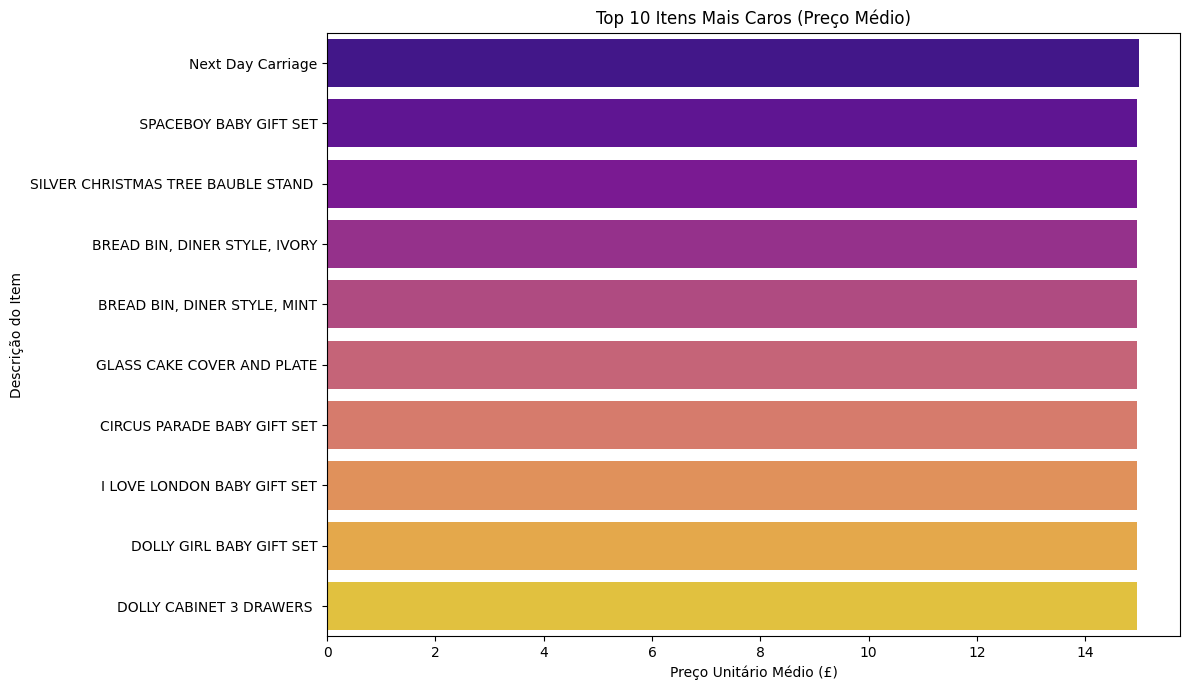

In [ ]:
# Plotar os 10 itens mais caros
plt.figure(figsize=(12, 7))
sns.barplot(x='UnitPrice', y='Description', data=most_expensive_items, palette='plasma')
plt.title('Top 10 Itens Mais Caros (Preço Médio)')
plt.xlabel('Preço Unitário Médio (£)')
plt.ylabel('Descrição do Item')
plt.tight_layout()
plt.show()

In [ ]:
# Top 10 itens mais baratos
least_expensive_items = item_prices.sort_values(by='UnitPrice', ascending=True).head(10)
print("\n10 Itens Mais Baratos:")
display(least_expensive_items)


10 Itens Mais Baratos:


,Description,UnitPrice
2248,PADS TO MATCH ALL CUSHIONS,0.001000
2371,PIECE OF CAMO STATIONERY SET,0.080000
624,CARTOON PENCIL SHARPENERS,0.083529
1650,HOUSE SHAPE PENCIL SHARPENER,0.090000
3748,WRAP BAD HAIR DAY,0.100000
2574,PORCELAIN BUDAH INCENSE HOLDER,0.100000
485,BLUE STONES ON WIRE FOR CANDLE,0.100526
1881,LETTER SHAPE PENCIL SHARPENER,0.112500
2566,POP ART PUSH DOWN RUBBER,0.120000
1252,FOLDING CAMPING SCISSOR W/KNIF & S,0.120000


/tmp/ipykernel_439/2244899255.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='UnitPrice', y='Description', data=least_expensive_items, palette='viridis')


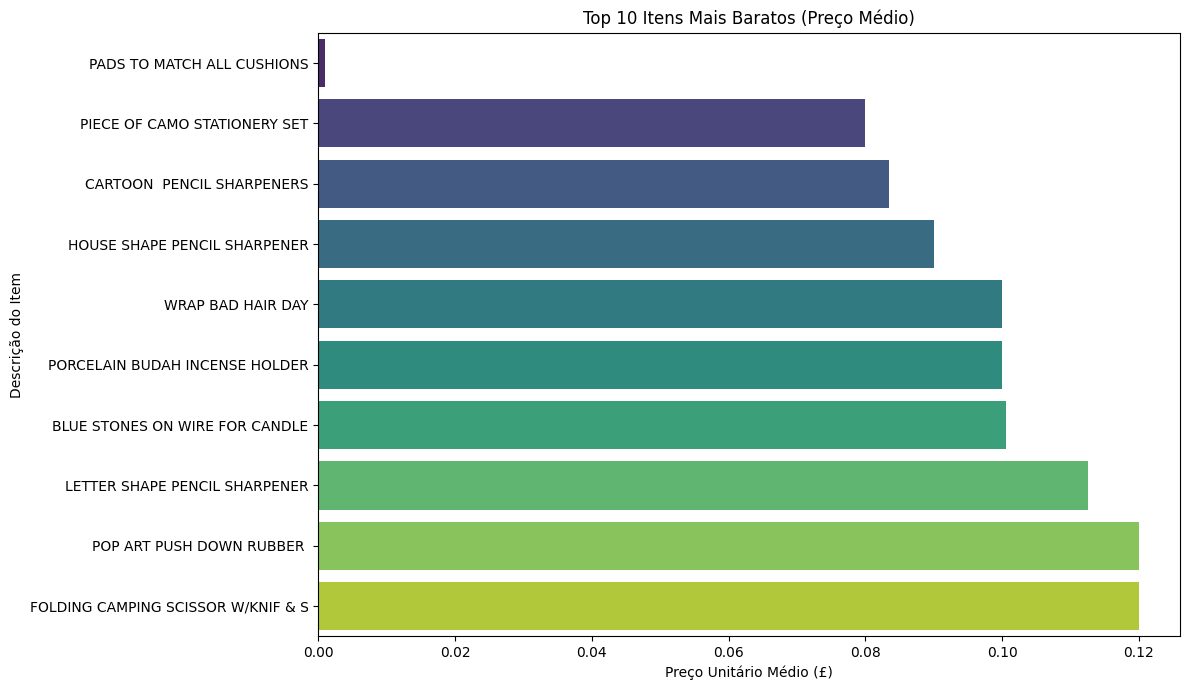

In [ ]:
# Plotar os 10 itens mais baratos
plt.figure(figsize=(12, 7))
sns.barplot(x='UnitPrice', y='Description', data=least_expensive_items, palette='viridis')
plt.title('Top 10 Itens Mais Baratos (Preço Médio)')
plt.xlabel('Preço Unitário Médio (£)')
plt.ylabel('Descrição do Item')
plt.tight_layout()
plt.show()

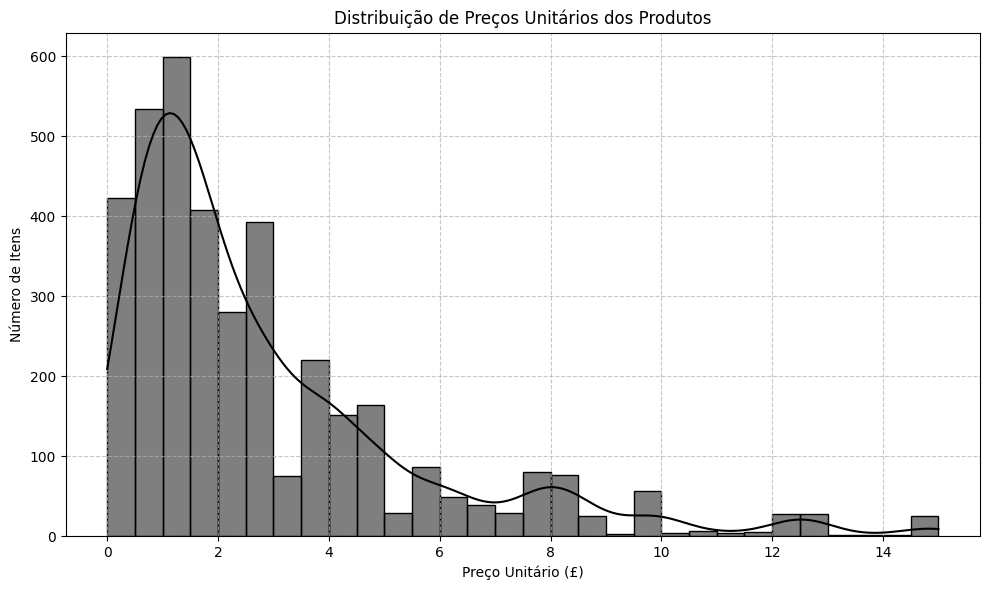

In [ ]:
# Análise da Distribuição de Preços dos Produtos
plt.figure(figsize=(10, 6))
sns.histplot(item_prices['UnitPrice'], bins=30, kde=True, color='black')
plt.title('Distribuição de Preços Unitários dos Produtos')
plt.xlabel('Preço Unitário (£)')
plt.ylabel('Número de Itens')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Calcular a quantidade total de cada item por país
country_item_quantity = df.groupby(['Country', 'Description'])['Quantity'].sum().reset_index()

# Identificar os países com maior volume de compras
top_countries = df.groupby('Country')['Quantity'].sum().sort_values(ascending=False).head(5).index

print("Itens Mais Comprados por País (Top 5 Países):")

for country in top_countries:
    print(f"\n--- {country} ---")
    # Filtrar os itens para o país atual e ordenar pela quantidade
    country_data = country_item_quantity[country_item_quantity['Country'] == country]
    top_items_country = country_data.sort_values(by='Quantity', ascending=False).head(5)
    display(top_items_country[['Description', 'Quantity']])

Itens Mais Comprados por País (Top 5 Países):

--- United Kingdom ---


,Description,Quantity
14648,ASSORTED COLOUR BIRD ORNAMENT,18727
18058,WHITE HANGING HEART T-LIGHT HOLDER,17665
18144,WORLD WAR 2 GLIDERS ASSTD DESIGNS,15198
16163,JUMBO BAG RED RETROSPOT,13221
16661,PACK OF 72 RETROSPOT CAKE CASES,12217



--- Germany ---


,Description,Quantity
8013,ROUND SNACK BOXES SET OF4 WOODLAND,1233
7728,PACK OF 72 RETROSPOT CAKE CASES,1002
8418,WOODLAND CHARLOTTE BAG,920
7846,PLASTERS IN TIN WOODLAND ANIMALS,857
7491,JAM MAKING SET PRINTED,816



--- France ---


,Description,Quantity
6235,RABBIT NIGHT LIGHT,1264
6309,RED TOADSTOOL LED NIGHT LIGHT,1123
6016,MINI PAINT SET VINTAGE,1008
6104,PACK OF 72 RETROSPOT CAKE CASES,936
6517,SET/6 RED SPOTTY PAPER CUPS,924



--- EIRE ---


,Description,Quantity
3974,PACK OF 72 RETROSPOT CAKE CASES,672
4118,POPCORN HOLDER,624
4271,ROSES REGENCY TEACUP AND SAUCER,591
4739,WORLD WAR 2 GLIDERS ASSTD DESIGNS,576
4218,REGENCY TEA PLATE ROSES,528



--- Switzerland ---


,Description,Quantity
13973,ROUND SNACK BOXES SET OF4 WOODLAND,384
13869,PLASTERS IN TIN SPACEBOY,276
13872,PLASTERS IN TIN WOODLAND ANIMALS,252
13868,PLASTERS IN TIN CIRCUS PARADE,204
13805,PACK OF 72 RETROSPOT CAKE CASES,192



--- Top 5 itens mais comprados em United Kingdom ---


/tmp/ipykernel_439/3067274713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')


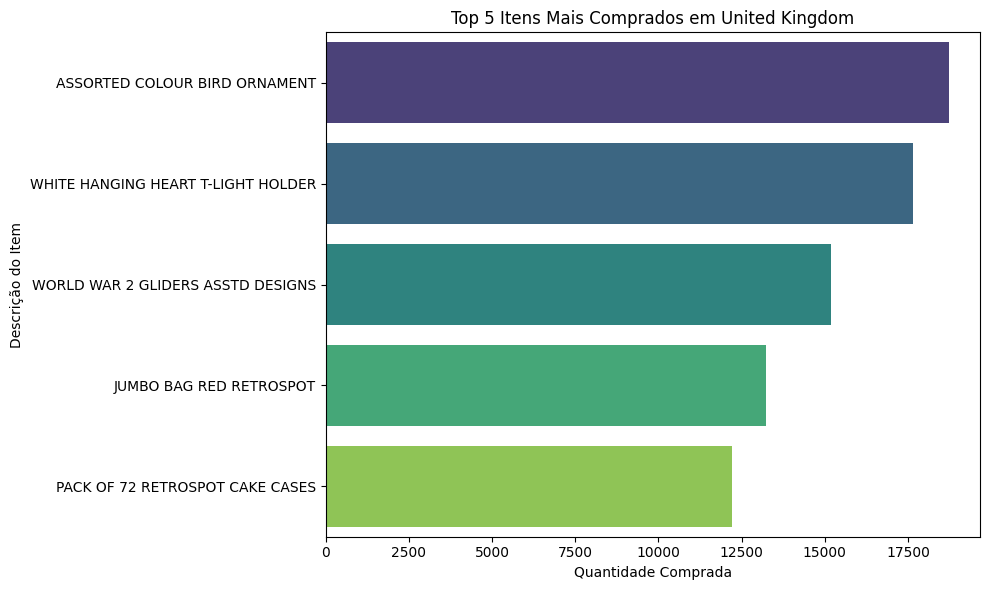

/tmp/ipykernel_439/3067274713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')



--- Top 5 itens mais comprados em Germany ---


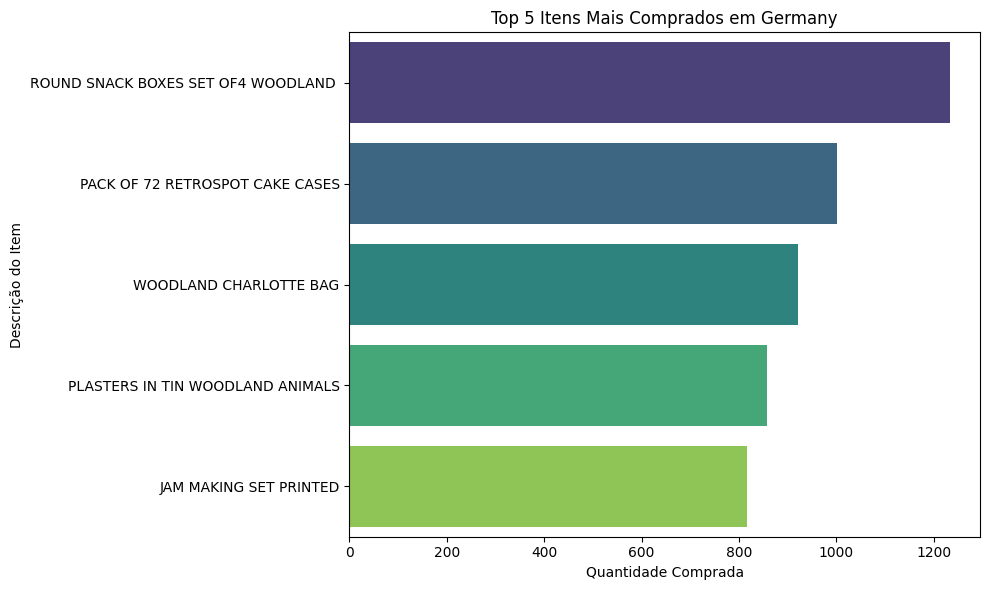


--- Top 5 itens mais comprados em France ---


/tmp/ipykernel_439/3067274713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')


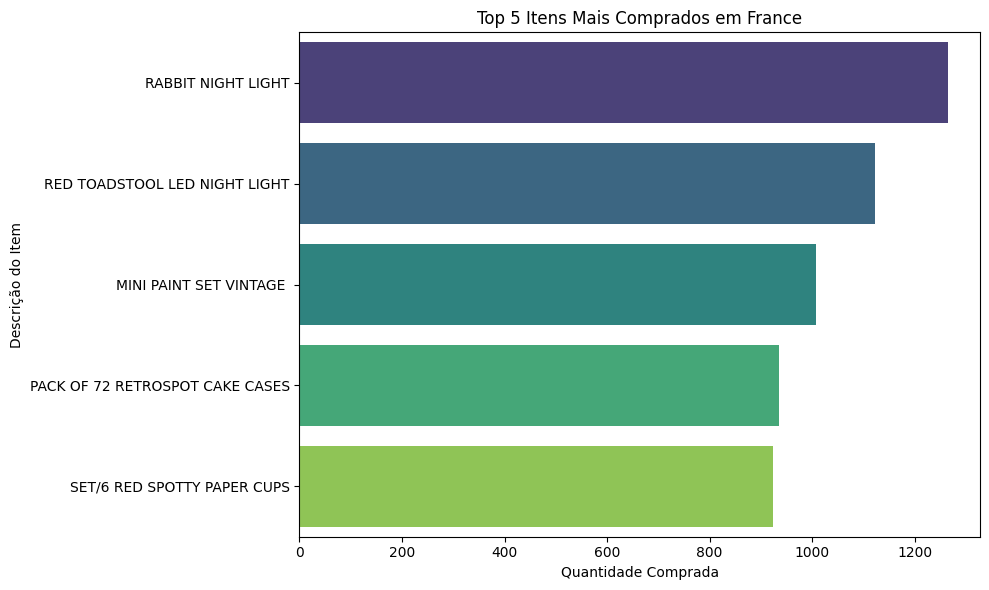

/tmp/ipykernel_439/3067274713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')



--- Top 5 itens mais comprados em EIRE ---


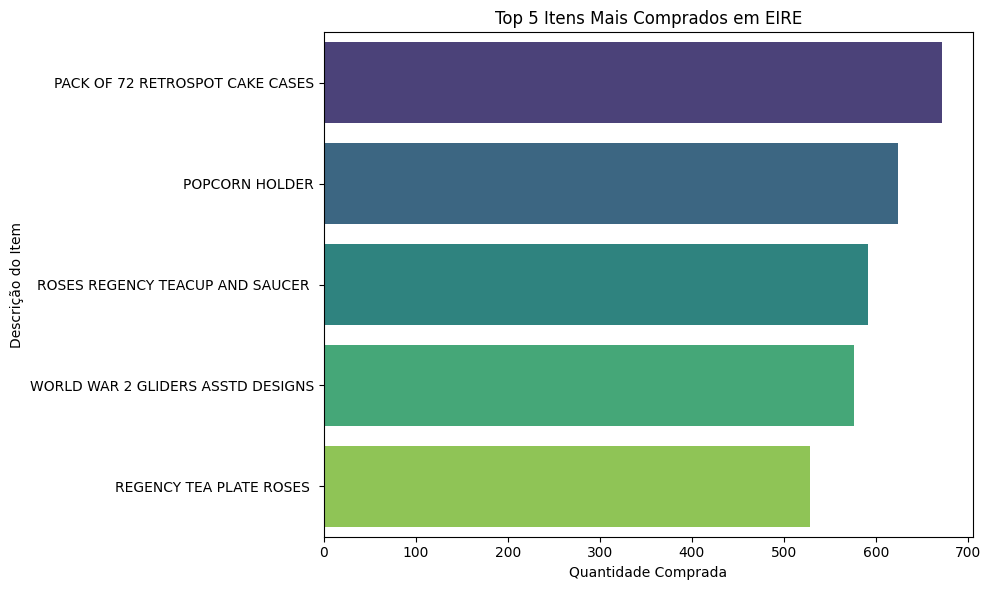


--- Top 5 itens mais comprados em Switzerland ---


/tmp/ipykernel_439/3067274713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')


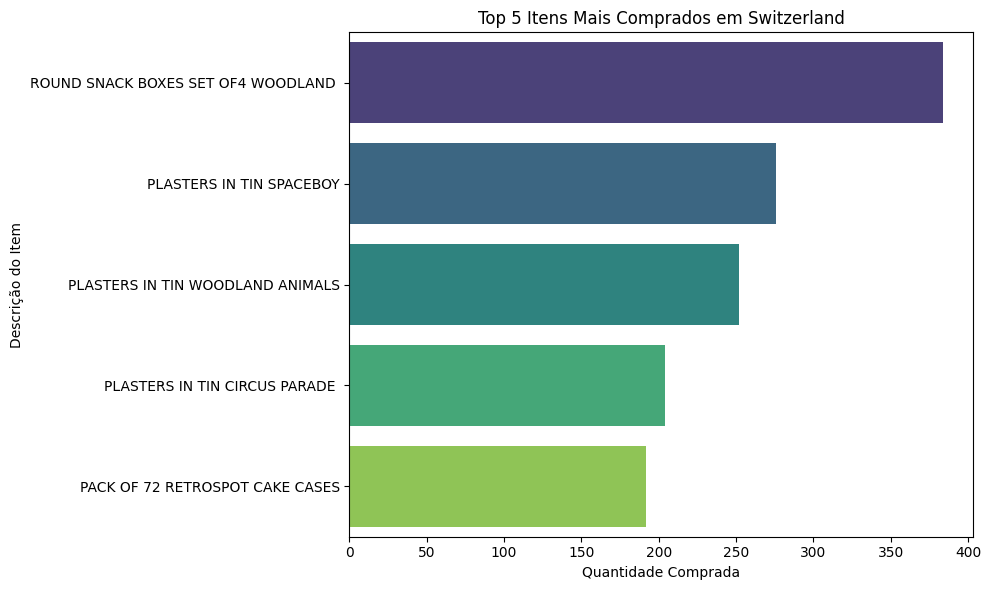

In [ ]:
# Criar um gráfico de barras para visualizar os itens mais comprados por país

for country in top_countries:
    print(f"\n--- Top 5 itens mais comprados em {country} ---")
    # Filtrar os itens para o país atual e ordenar pela quantidade
    country_data = country_item_quantity[country_item_quantity['Country'] == country]
    top_items_country = country_data.sort_values(by='Quantity', ascending=False).head(5)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Quantity', y='Description', data=top_items_country, palette='viridis')
    plt.title(f'Top 5 Itens Mais Comprados em {country}')
    plt.xlabel('Quantidade Comprada')
    plt.ylabel('Descrição do Item')
    plt.tight_layout()
    plt.show()

In [ ]:
# Calcular a lucratividade (receita) média por item em cada país
country_item_revenue = df.groupby(['Country', 'Description'])['Revenue'].mean().reset_index()

print("Produtos Mais Lucrativos por País (Top 5 Países):")

for country in top_countries:
    print(f"\n--- {country} ---")
    # Filtrar os itens para o país atual e ordenar pela receita média
    country_data = country_item_revenue[country_item_revenue['Country'] == country]
    top_profitable_items_country = country_data.sort_values(by='Revenue', ascending=False).head(5)
    display(top_profitable_items_country[['Description', 'Revenue']])

Produtos Mais Lucrativos por País (Top 5 Países):

--- United Kingdom ---


,Description,Revenue
15198,CINDERELLA CHANDELIER,400.000000
14468,16 PIECE CUTLERY SET PANTRY DESIGN,300.000000
18112,WOODEN ADVENT CALENDAR CREAM,188.777778
17551,SILVER FLOWR PINK SHELL NECKLACE,111.760000
17573,SILVER T-LIGHT SETTING,106.390000



--- Germany ---


,Description,Revenue
8060,SET OF 16 VINTAGE BLACK CUTLERY,262.800000
7030,CABIN BAG VINTAGE PAISLEY,153.000000
6991,BLUE SAVANNAH PICNIC HAMPER FOR 2,131.400000
7855,POMPOM CURTAIN,124.950000
7954,REGENCY CAKESTAND 3 TIER,122.707377



--- France ---


,Description,Revenue
6183,PINK HAPPY BIRTHDAY BUNTING,232.500000
5851,I LOVE LONDON BABY GIFT SET,179.400000
5282,SPACEBOY BABY GIFT SET,140.957143
5630,DOLLY GIRL BABY GIFT SET,119.600000
5577,CIRCUS PARADE BABY GIFT SET,119.600000



--- EIRE ---


,Description,Revenue
2850,SPACEBOY BABY GIFT SET,358.800000
3324,DOLLY GIRL BABY GIFT SET,269.100000
3227,CIRCUS PARADE BABY GIFT SET,269.100000
2884,3 TIER CAKE TIN RED AND CREAM,255.378571
3778,LARGE DECO JEWELLERY STAND,220.066667



--- Switzerland ---


,Description,Revenue
13286,16 PIECE CUTLERY SET PANTRY DESIGN,300.00
13999,SET OF 16 VINTAGE BLACK CUTLERY,262.80
13769,OPEN CLOSED METAL SIGN,153.00
13736,METAL SIGN TAKE IT OR LEAVE IT,122.40
14077,SMALL RED RETROSPOT MUG IN BOX,122.04


In [ ]:
#  Itens Exclusivos por País
# Agrupar por 'Description' e 'Country' para ver onde cada item é vendido
item_country = df.groupby(['Description', 'Country']).size().reset_index(name='Count')

# Contar o número de países em que cada item é vendido
item_country_count = item_country.groupby('Description')['Country'].nunique().reset_index(name='NumCountries')

# Filtrar itens vendidos em apenas um país
exclusive_items = item_country_count[item_country_count['NumCountries'] == 1]

# Juntar de volta com o DataFrame original para obter o nome do país
exclusive_items_details = pd.merge(exclusive_items, item_country, on='Description', how='left')

# Renomear as colunas para 'Item' e 'País'
exclusive_items_details.rename(columns={'Description': 'Item', 'Country': 'País'}, inplace=True)

# Selecionar e exibir as colunas relevantes
print("Itens Exclusivos por País (Top 10):")
display(exclusive_items_details[['Item', 'País']].head(10))

print(f"Total de itens exclusivos encontrados: {len(exclusive_items_details)}")

Itens Exclusivos por País (Top 10):


,Item,País
0,I LOVE LONDON MINI RUCKSACK,Netherlands
1,TOADSTOOL BEDSIDE LIGHT,United Kingdom
2,12 HANGING EGGS HAND PAINTED,United Kingdom
3,15 PINK FLUFFY CHICKS IN BOX,United Kingdom
4,2 DAISIES HAIR COMB,EIRE
5,3 BIRDS CANVAS SCREEN,United Kingdom
6,3 BLACK CATS W HEARTS BLANK CARD,United Kingdom
7,3 PINK HEN+CHICKS IN BASKET,United Kingdom
8,3 TRADITIONAL COOKIE CUTTERS SET,United Kingdom
9,3 WICK CHRISTMAS BRIAR CANDLE,United Kingdom


Total de itens exclusivos encontrados: 1013


In [ ]:
# Para cada item exclusivo, queremos saber a quantidade vendida no país exclusivo
# Primeiro, criar um DataFrame com apenas os itens exclusivos e seus países
exclusive_items_quantity_df = pd.merge(exclusive_items_details[['Item', 'País']], df,
                                       left_on=['Item', 'País'],
                                       right_on=['Description', 'Country'],
                                       how='inner')

# Agrupar por Item e País e somar a quantidade
exclusive_item_sales_quantity = exclusive_items_quantity_df.groupby(['Item', 'País'])['Quantity'].sum().reset_index()
exclusive_item_sales_quantity.rename(columns={'Quantity': 'Quantidade Vendida'}, inplace=True)

# Excluir o Reino Unido da visualização
exclusive_item_sales_quantity_filtered = exclusive_item_sales_quantity[exclusive_item_sales_quantity['País'] != 'United Kingdom']

print("Quantidade Vendida de Cada Item Exclusivo por País (Top 10 - Excluindo Reino Unido):")
display(exclusive_item_sales_quantity_filtered.sort_values(by='Quantidade Vendida', ascending=False).head(10))

print(f"Total de registros de vendas para itens exclusivos (excluindo Reino Unido): {len(exclusive_item_sales_quantity_filtered)}")

Quantidade Vendida de Cada Item Exclusivo por País (Top 10 - Excluindo Reino Unido):


,Item,País,Quantidade Vendida
292,DOORKNOB CERAMIC IVORY,EIRE,36
206,CHRISTMAS CRAFT HEART STOCKING,Lithuania,30
93,BIRTHDAY BANNER TAPE,Switzerland,24
378,"GARLAND, MAGIC GARDEN 1.8M",EIRE,12
463,HOT WATER BOTTLE BABUSHKA LARGE,Switzerland,8
270,DAISY HAIR COMB,EIRE,6
95,BLACK 3 BEAD DROP EARRINGS,EIRE,6
42,ANT SILVER TURQUOISE BOUDICCA RING,Portugal,6
4,2 DAISIES HAIR COMB,EIRE,6
897,TINY CRYSTAL BRACELET GREEN,Germany,6


Total de registros de vendas para itens exclusivos (excluindo Reino Unido): 25


/tmp/ipykernel_439/3378274538.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantidade Vendida', y='Item', data=exclusive_item_sales_quantity_filtered.sort_values(by='Quantidade Vendida', ascending=False).head(10), palette='crest')


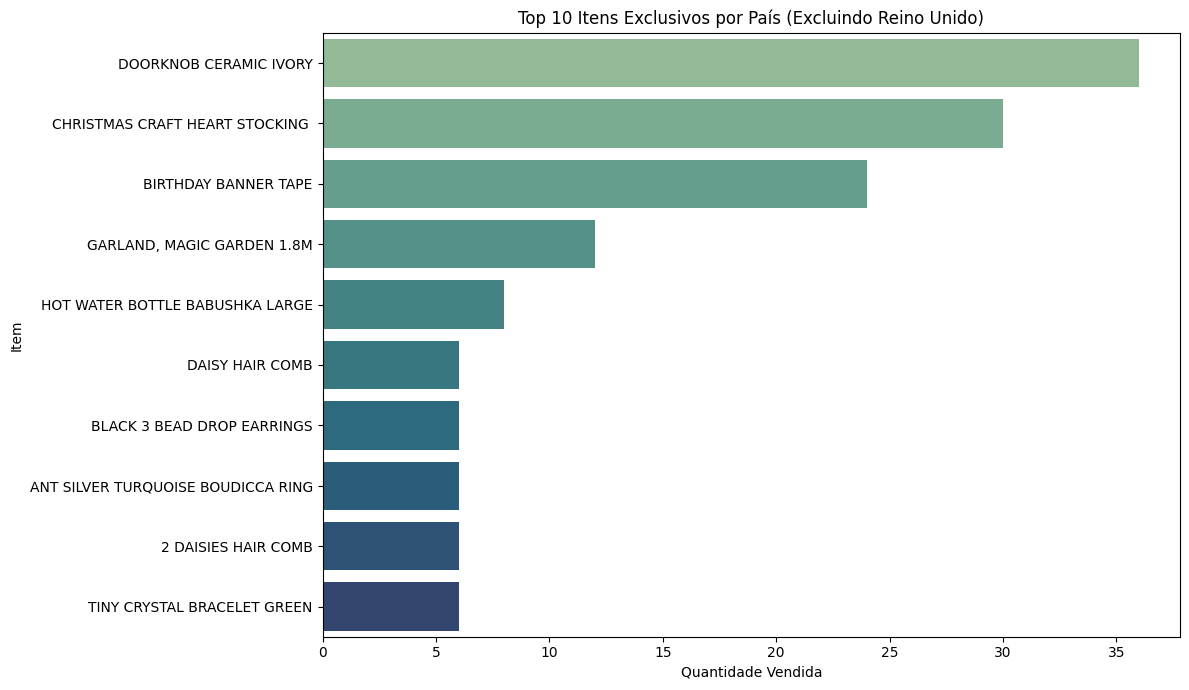

In [ ]:
# Criar um gráfico de barras para visualizar a quantidade vendida de itens exclusivos por país (excluindo Reino Unido)
plt.figure(figsize=(12, 7))
sns.barplot(x='Quantidade Vendida', y='Item', data=exclusive_item_sales_quantity_filtered.sort_values(by='Quantidade Vendida', ascending=False).head(10), palette='crest')
plt.title('Top 10 Itens Exclusivos por País (Excluindo Reino Unido)')
plt.xlabel('Quantidade Vendida')
plt.ylabel('Item')
plt.tight_layout()
plt.show()

In [ ]:
# Filtrar itens com preço unitário menor que 1 euro
low_price_items = df[df['UnitPrice'] < 1]

# Agrupar por descrição e somar a quantidade para encontrar os menos vendidos
least_sold_low_price_items = low_price_items.groupby('Description')['Quantity'].sum().sort_values(ascending=True).head(10)

print("10 Itens Mais Baratos (Preço < 1€) e Menos Vendidos:")
least_sold_low_price_items.index.name = 'Descrição'
least_sold_low_price_items.name = 'Quantidade Vendida'
display(least_sold_low_price_items.reset_index())

10 Itens Mais Baratos (Preço < 1€) e Menos Vendidos:


,Descrição,Quantidade Vendida
0,3 BIRDS CANVAS SCREEN,1
1,MINT KITCHEN SCALES,1
2,HEN HOUSE W CHICK IN NEST,1
3,SET OF PICTURE FRAME STICKERS,1
4,PINK CRYSTAL GUITAR PHONE CHARM,1
5,SET 12 COLOURING PENCILS DOILEY,1
6,PURPLE FRANGIPANI HAIRCLIP,1
7,Bank Charges,1
8,60 GOLD AND SILVER FAIRY CAKE CASES,2
9,VINTAGE BLUE TINSEL REEL,2


In [ ]:
low_sales_low_price_items = low_price_items.groupby('Description')['Quantity'].sum().reset_index()
low_sales_low_price_items = low_sales_low_price_items[low_sales_low_price_items['Quantity'] < 6]

print("Itens com preço menor que 1 Euro e menos de 5 vendas:")
display(low_sales_low_price_items.sort_values(by='Quantity', ascending=True))
print(low_sales_low_price_items.count())

Itens com preço menor que 1 Euro e menos de 5 vendas:


,Description,Quantity
10,3 BIRDS CANVAS SCREEN,1
188,Bank Charges,1
508,HEN HOUSE W CHICK IN NEST,1
668,MINT KITCHEN SCALES,1
825,PINK CRYSTAL GUITAR PHONE CHARM,1
873,PURPLE FRANGIPANI HAIRCLIP,1
977,SET OF PICTURE FRAME STICKERS,1
942,SET 12 COLOURING PENCILS DOILEY,1
727,PACK 20 DOLLY PEGS,2
1125,VINTAGE BLUE TINSEL REEL,2


Description    23
Quantity       23
dtype: int64


## Clientes

/tmp/ipykernel_439/2123114745.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='CustomerID', y='Revenue', data=top_customers_by_revenue, palette='viridis')


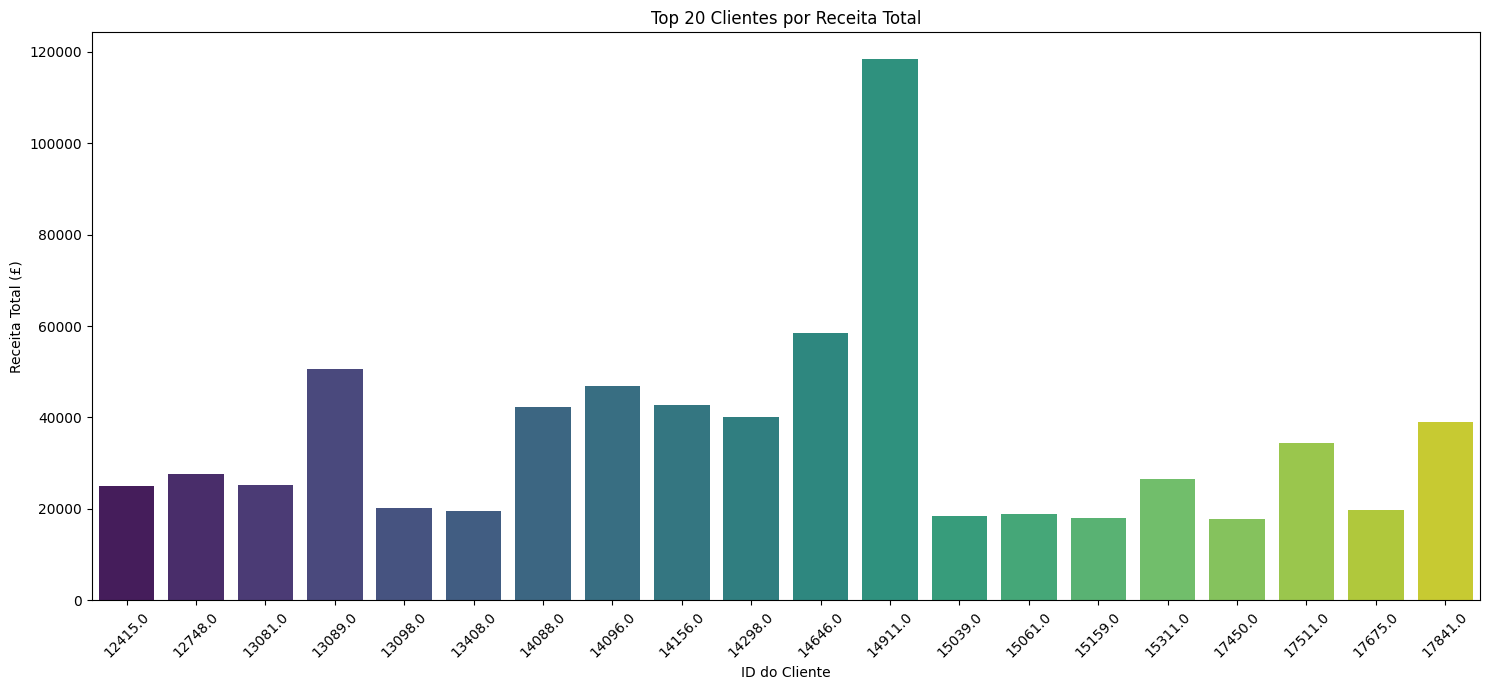

In [ ]:
# Calcular a receita total por cliente
customer_revenue = df.groupby('CustomerID')['Revenue'].sum().reset_index()

# Ordenar os clientes pela receita e pegar os top 20
top_customers_by_revenue = customer_revenue.sort_values(by='Revenue', ascending=False).head(20)

# Criar o gráfico de barras
plt.figure(figsize=(15, 7))
sns.barplot(x='CustomerID', y='Revenue', data=top_customers_by_revenue, palette='viridis')
plt.title('Top 20 Clientes por Receita Total')
plt.xlabel('ID do Cliente')
plt.ylabel('Receita Total (£)')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

In [ ]:
# Calcular a receita total de todos os clientes
total_revenue_all_customers = customer_revenue['Revenue'].sum()

# Classificar os clientes por receita em ordem crescente para a correta análise de Gini
customer_revenue_sorted = customer_revenue.sort_values(by='Revenue', ascending=True).reset_index(drop=True)

# Calcular a receita acumulada
customer_revenue_sorted['CumulativeRevenue'] = customer_revenue_sorted['Revenue'].cumsum()

# Calcular a porcentagem acumulada da receita
customer_revenue_sorted['CumulativeRevenuePercentage'] = (customer_revenue_sorted['CumulativeRevenue'] / total_revenue_all_customers) * 100

# Calcular a porcentagem acumulada de clientes
customer_revenue_sorted['CustomerPercentage'] = (customer_revenue_sorted.index + 1) / len(customer_revenue_sorted) * 100

# Exibir os resultados para os primeiros clientes
display(customer_revenue_sorted.head())

,CustomerID,Revenue,CumulativeRevenue,CumulativeRevenuePercentage,CustomerPercentage
0,16446.0,2.90,2.90,0.000049,0.023491
1,16738.0,3.75,6.65,0.000111,0.046981
2,16429.0,4.95,11.60,0.000194,0.070472
3,14792.0,6.20,17.80,0.000298,0.093963
4,16454.0,6.90,24.70,0.000414,0.117454


### Análise RFM (Recência, Frequência, Valor Monetário)

In [ ]:
# Calcular a data mais recente no dataset
latest_date = df['InvoiceDate'].max()

# Calcular Recência, Frequência e Valor Monetário
rfm_df = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda date: (latest_date - date.max()).days),  # Dias desde a última compra
    Frequency=('InvoiceNo', 'nunique'),                                     # Número total de pedidos únicos
    Monetary=('Revenue', 'sum')                                             # Receita total gerada
).reset_index()

display(rfm_df.head())

,CustomerID,Recency,Frequency,Monetary
0,12347.0,1,7,4060.40
1,12348.0,248,3,200.60
2,12349.0,18,1,1353.80
3,12350.0,309,1,294.40
4,12352.0,35,7,1385.74


In [ ]:
# Atribuir pontuações para Recência, Frequência e Valor Monetário
# Recência: quanto menor, melhor (inverter a pontuação)
rfm_df['R_Score'] = pd.qcut(rfm_df['Recency'], 5, labels=[5, 4, 3, 2, 1])

# Frequência e Monetário: quanto maior, melhor (pontuação direta)
rfm_df['F_Score'] = pd.qcut(rfm_df['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm_df['M_Score'] = pd.qcut(rfm_df['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

# Exibir o DataFrame RFM com as pontuações
display(rfm_df.head())

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12347.0,1,7,4060.40,5,5,5
1,12348.0,248,3,200.60,1,3,1
2,12349.0,18,1,1353.80,4,1,4
3,12350.0,309,1,294.40,1,1,2
4,12352.0,35,7,1385.74,3,5,4


In [ ]:
# Combinar as pontuações RFM em uma única string para fácil segmentação
rfm_df['RFM_Segment'] = rfm_df['R_Score'].astype(str) + rfm_df['F_Score'].astype(str) + rfm_df['M_Score'].astype(str)

# Calcular a pontuação RFM total
rfm_df['RFM_Score'] = rfm_df['R_Score'].astype(int) + rfm_df['F_Score'].astype(int) + rfm_df['M_Score'].astype(int)

# Exibir o DataFrame RFM com os segmentos e a pontuação total
display(rfm_df.head())

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,RFM_Score
0,12347.0,1,7,4060.40,5,5,5,555,15
1,12348.0,248,3,200.60,1,3,1,131,5
2,12349.0,18,1,1353.80,4,1,4,414,9
3,12350.0,309,1,294.40,1,1,2,112,4
4,12352.0,35,7,1385.74,3,5,4,354,12


In [ ]:
# Definir segmentos de clientes com base nas pontuações RFM
def rfm_segment(df):
    if df['RFM_Score'] >= 9:
        return 'Melhores Clientes'
    elif (df['RFM_Score'] >= 7) and (df['RFM_Score'] < 9):
        return 'Clientes Leais'
    elif (df['RFM_Score'] >= 5) and (df['RFM_Score'] < 7):
        return 'Clientes Potenciais'
    else:
        return 'Clientes em Risco'

rfm_df['Customer_Segment'] = rfm_df.apply(rfm_segment, axis=1)

# Exibir a distribuição dos clientes por segmento
segment_counts = rfm_df['Customer_Segment'].value_counts().reset_index()
segment_counts.columns = ['Segmento', 'Número de Clientes']

display(segment_counts)

,Segmento,Número de Clientes
0,Melhores Clientes,2225
1,Clientes Potenciais,753
2,Clientes Leais,741
3,Clientes em Risco,538


In [ ]:
rfm_df.rename(columns={'CustomerID': 'ID',
                       'Recency': 'Recência',
                       'Frequency': 'Frequência',
                       'Monetary': 'V. Monetário',
                       'Customer_Segment': 'Segmento'}, inplace=True)

# Exibir o DataFrame RFM com as colunas renomeadas, excluindo as colunas de score
display(rfm_df[['ID', 'Recência', 'Frequência', 'V. Monetário', 'Segmento']].head())

,ID,Recência,Frequência,V. Monetário,Segmento
0,12347.0,1,7,4060.40,Melhores Clientes
1,12348.0,248,3,200.60,Clientes Potenciais
2,12349.0,18,1,1353.80,Melhores Clientes
3,12350.0,309,1,294.40,Clientes em Risco
4,12352.0,35,7,1385.74,Melhores Clientes


In [ ]:
rfm_df[['ID', 'Recência', 'Frequência', 'V. Monetário', 'Segmento']].groupby('Segmento').agg({
    'Recência': 'mean',
    'Frequência': 'mean',
    'V. Monetário': ['mean', 'count']
}).round(1)

Recência Frequência V. Monetário      
                        mean       mean         mean count
Segmento                                                  
Clientes Leais          91.0        1.8        512.6   741
Clientes Potenciais    147.8        1.2        306.5   753
Clientes em Risco      251.2        1.0        169.4   538
Melhores Clientes       34.0        6.7       2368.2  2225

/tmp/ipykernel_765/2602432302.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Segmento', y='Número de Clientes', data=segment_counts, palette='viridis')


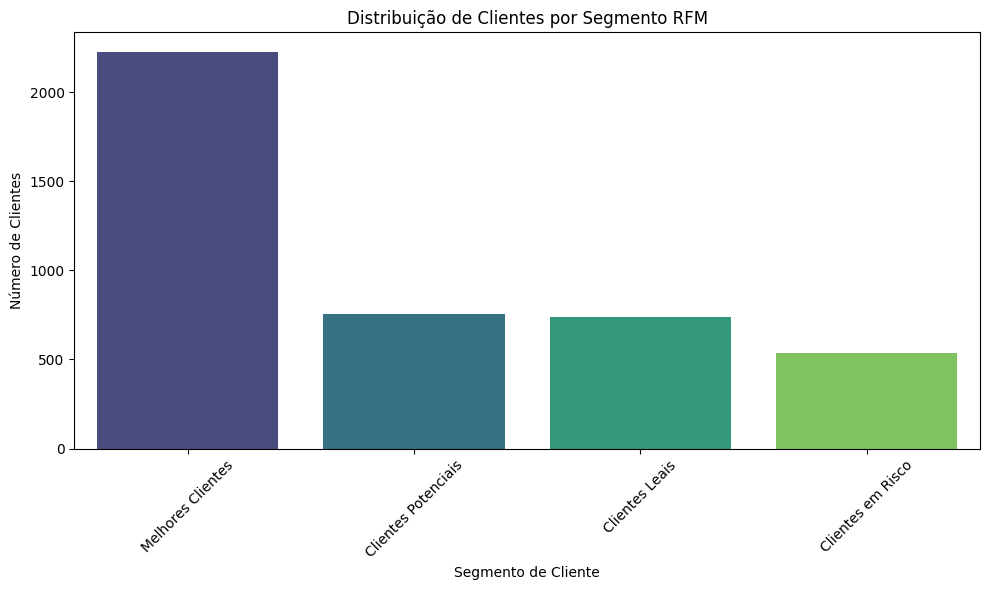

In [ ]:
# Visualizar a distribuição dos clientes por segmento
plt.figure(figsize=(10, 6))
sns.barplot(x='Segmento', y='Número de Clientes', data=segment_counts, palette='viridis')
plt.title('Distribuição de Clientes por Segmento RFM')
plt.xlabel('Segmento de Cliente')
plt.ylabel('Número de Clientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Sugestões Iniciais

Informações encontradas na análise exploratória

- A média de preço dos itens vendidos é £2,91.
- Ticket médio é de £338.77.
- Os meses com menos vendas são de dezembro a abril.
- Existem 25 itens que não são vendidos no Reino Unido mas são vendidos em outros países.
- Dos 3824 itens existentes, 1023 são vendidos em apenas um país (998 sendo no Reino Unido).
- O país com maior lucratividade fora do Reino Unido é Alemanha, seguida da França.
- O número de clientes em potencial é próximo do de clientes leais.
- Existem 538 clientes em risco.
- "PACK OF 72 RETROSPOT CAKE CASES" é um dos itens mais vendido em vários países.
- Existem 23 itens com potencial risco de prejuízo no estoque, pois vendem 5 ou menos unidades por ano e custam menos de 1 euro.

Questões iniciais para a gerência analisar
- Avaliar questões de sazonalidade: o que causa das vendas menores entre dezembro e abril?
- Quais os principais motivos de cancelamento?
- Todas as lojas estão dando lucro? Qual o custo operacional das 5 lojas que menos faturam?
- Quais produtos não estão vendendo ou geram mais custo de estoque do que lucro?

# Modelagem Preditiva

## Etapa 1 de testes: USO DE RFM


In [ ]:
# Calcular a data mais recente no dataset
latest_date = df['InvoiceDate'].max()

# Definir a data de corte para a janela de observação (últimos 60 dias para a previsão)
prediction_window_start = latest_date - pd.DateOffset(days=60)

# Criar o DataFrame para a janela de observação (features)
df_observation = df[df['InvoiceDate'] <= prediction_window_start]

# Criar o DataFrame para a janela de previsão (target)
df_prediction = df[df['InvoiceDate'] > prediction_window_start]

print(f"Data mais recente no dataset: {latest_date}")
print(f"Início da janela de previsão: {prediction_window_start}")
print(f"Número de transações na janela de observação: {len(df_observation)}")
print(f"Número de transações na janela de previsão: {len(df_prediction)}")

Data mais recente no dataset: 2011-12-09 12:50:00
Início da janela de previsão: 2011-10-10 12:50:00
Número de transações na janela de observação: 269334
Número de transações na janela de previsão: 113527


Agora, vamos identificar quais clientes fizeram uma compra na janela de previsão para criar nossa variável target.

In [ ]:
# Identificar clientes únicos que compraram na janela de previsão
customers_repurchased = df_prediction['CustomerID'].unique()

# Obter todos os clientes únicos da janela de observação
all_customers_observation = df_observation['CustomerID'].unique()

# Criar um DataFrame de clientes e sua flag de recompra
target_df = pd.DataFrame({'CustomerID': all_customers_observation})
target_df['Repurchase_60_Days'] = target_df['CustomerID'].isin(customers_repurchased).astype(int)

# Renomear 'CustomerID' para 'ID' para que possa ser unido com rfm_features_observation
target_df.rename(columns={'CustomerID': 'ID'}, inplace=True)

print("Distribuição da variável target (Recompra em 60 dias):")
display(target_df['Repurchase_60_Days'].value_counts())

Distribuição da variável target (Recompra em 60 dias):


,count
Repurchase_60_Days,
0,1898
1,1756


Com a variável target definida, o próximo passo é preparar as *features* (características) dos clientes usando apenas os dados da janela de observação. Isso incluirá o recálculo das métricas RFM, mas considerando apenas o período de observação, para evitar vazamento de dados do futuro.

In [ ]:
# Calcular a data mais recente dentro da janela de observação
latest_date_observation = df_observation['InvoiceDate'].max()

# Recalcular Recência, Frequência e Valor Monetário usando APENAS a janela de observação
rfm_features_observation = df_observation.groupby('CustomerID').agg(
    Recency_obs=('InvoiceDate', lambda date: (latest_date_observation - date.max()).days),
    Frequency_obs=('InvoiceNo', 'nunique'),
    Monetary_obs=('Revenue', 'sum')
).reset_index()

# Renomear CustomerID para 'ID' para facilitar o merge com target_df
rfm_features_observation.rename(columns={'CustomerID': 'ID'}, inplace=True)

display(rfm_features_observation.head())

,ID,Recency_obs,Frequency_obs,Monetary_obs
0,12347.0,69,5,2541.26
1,12348.0,188,3,200.60
2,12350.0,249,1,294.40
3,12352.0,11,6,1154.01
4,12353.0,143,1,89.00


Com as features RFM calculadas para o período de observação, o próximo passo é unir essas features com a variável target (`Repurchase_60_Days`) que criamos anteriormente. Além disso, precisamos garantir que todos os clientes no `target_df` tenham as features RFM correspondentes. Clientes que não apareceram na janela de observação para o cálculo RFM podem ser preenchidos com valores padrão ou removidos, dependendo da estratégia.

In [ ]:
# Unir as features RFM (do período de observação) com a variável target

# Usar um merge à esquerda para manter todos os clientes que calculamos o target
model_df = pd.merge(target_df, rfm_features_observation, on='ID', how='left')

# Lidar com clientes que podem não ter aparecido na janela de observação
# Por exemplo, preencher NaNs com 0 para recência (indicando que não compraram nesse período) ou outras estratégias
# Para simplificar, vou preencher com 0 e assumir que a falta de dados significa baixa atividade.
model_df['Recency_obs'] = model_df['Recency_obs'].fillna(model_df['Recency_obs'].max() + 60) # Ou um valor que indique 'muito tempo'
model_df['Frequency_obs'] = model_df['Frequency_obs'].fillna(0)
model_df['Monetary_obs'] = model_df['Monetary_obs'].fillna(0)

display(model_df.head())
display(model_df.isnull().sum())

,ID,Repurchase_60_Days,Recency_obs,Frequency_obs,Monetary_obs
0,17850.0,0,311,34,4783.46
1,13047.0,1,66,8,2682.01
2,12583.0,1,9,11,4273.15
3,15100.0,0,273,3,876.00
4,15291.0,1,34,10,2619.06


,0
ID,0
Repurchase_60_Days,0
Recency_obs,0
Frequency_obs,0
Monetary_obs,0


In [ ]:
# Definir as features (X) e a variável target (y)
X = model_df[['Recency_obs', 'Frequency_obs', 'Monetary_obs']]
y = model_df['Repurchase_60_Days']

# Dividir os dados em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Shape de X_train: {X_train.shape}\n")
print(f"Shape de X_test: {X_test.shape}\n")
print(f"Distribuição de y_train:\n{y_train.value_counts(normalize=True)}\n")
print(f"Distribuição de y_test:\n{y_test.value_counts(normalize=True)}\n")

Shape de X_train: (2923, 3)

Shape de X_test: (731, 3)

Distribuição de y_train:
Repurchase_60_Days
0    0.519329
1    0.480671
Name: proportion, dtype: float64

Distribuição de y_test:
Repurchase_60_Days
0    0.519836
1    0.480164
Name: proportion, dtype: float64



In [ ]:
# Treinar o modelo RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced') # class_weight para lidar com desbalanceamento
model.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


Com o modelo treinado, vamos agora avaliar sua performance nos dados de teste.

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       380
           1       0.62      0.55      0.58       351

    accuracy                           0.62       731
   macro avg       0.62      0.62      0.62       731
weighted avg       0.62      0.62      0.62       731

Acurácia: 0.62
ROC AUC Score: 0.68


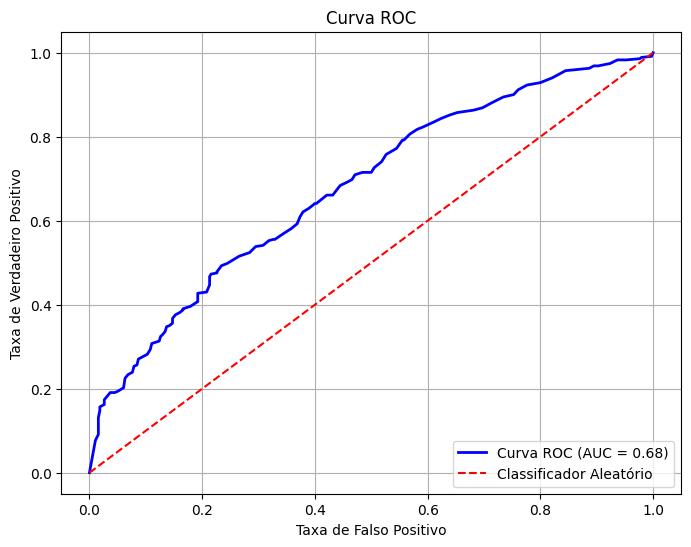

In [ ]:
# Fazer previsões no conjunto de teste
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Avaliar a performance do modelo
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Acurácia: {accuracy:.2f}")
print(f"ROC AUC Score: {roc_auc:.2f}")

# Plotar a Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
plt.xlabel('Taxa de Falso Positivo')
plt.ylabel('Taxa de Verdadeiro Positivo')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Avaliamos o modelo e ele parece ter uma boa performance, especialmente considerando o ROC AUC. O próximo passo é extrair a importância das features para entender quais fatores mais influenciam a previsão de recompra.

,Feature,Importance
2,Monetary_obs,0.50392
0,Recency_obs,0.37221
1,Frequency_obs,0.12387


/tmp/ipykernel_439/3717109823.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')


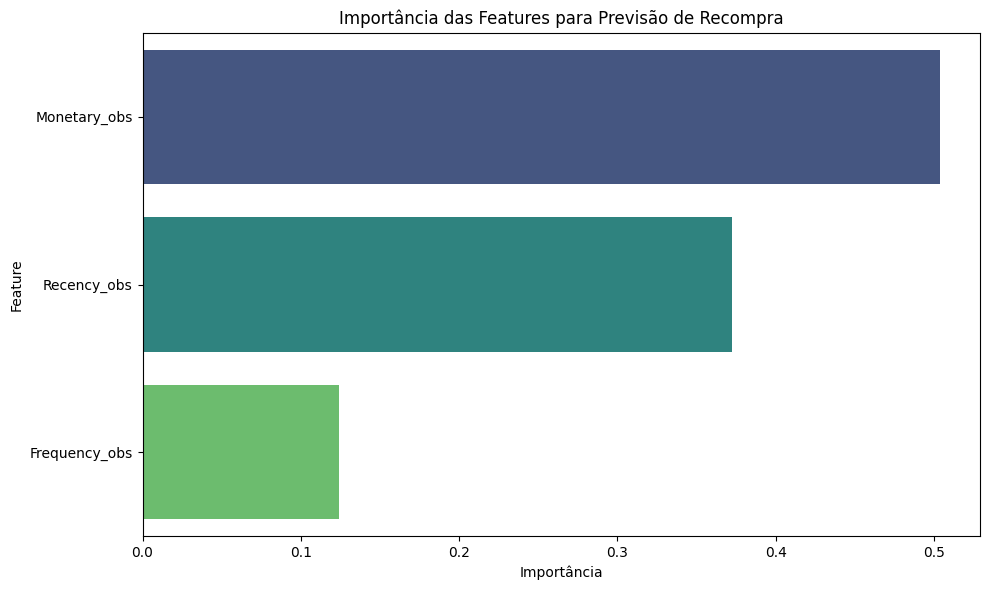

In [ ]:
# Importância das Features
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(feature_importances)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')
plt.title('Importância das Features para Previsão de Recompra')
plt.xlabel('Importância')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Finalmente, podemos usar o modelo para prever a probabilidade de recompra para cada cliente e priorizá-los com base nessas probabilidades.

In [ ]:
# Prever a probabilidade de recompra para todos os clientes no dataset original (após a janela de observação)
# Vamos usar as features RFM calculadas para o período de observação para todos os clientes

# Gerar as probabilidades de recompra para todos os clientes presentes em model_df
all_customer_probabilities = model.predict_proba(X)[:, 1]

# Adicionar as probabilidades ao model_df
model_df['Repurchase_Probability'] = all_customer_probabilities

# Classificar clientes com base na probabilidade de recompra (do maior para o menor)
prioritized_customers = model_df.sort_values(by='Repurchase_Probability', ascending=False)

display(prioritized_customers[['ID', 'Recency_obs', 'Frequency_obs', 'Monetary_obs', 'Repurchase_Probability', 'Repurchase_60_Days']].head(10))

print("Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias.")

,ID,Recency_obs,Frequency_obs,Monetary_obs,Repurchase_Probability,Repurchase_60_Days
5,14688.0,10,17,4355.47,1.0,1
33,13694.0,11,33,12448.64,1.0,1
22,15513.0,34,16,10014.34,1.0,1
18,13767.0,0,34,11319.68,1.0,1
17,13408.0,6,46,14598.74,1.0,1
14,17511.0,5,23,28270.36,1.0,1
13,12431.0,4,12,4652.58,1.0,1
11,16029.0,5,36,7709.09,1.0,1
7,15311.0,3,72,20656.71,1.0,1
43,12748.0,1,143,17826.19,1.0,1


Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias.


### Regressão Logística

Vamos utilizar o mesmo conjunto de dados de treino e teste já separados (`X_train`, `X_test`, `y_train`, `y_test`) para treinar um modelo de Regressão Logística.

In [ ]:
# Treinar o modelo de Regressão Logística
# Usamos 'liblinear' como solver para lidar com L1/L2 regularization e 'balanced' class_weight
logistic_model = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model.fit(X_train, y_train)

print("Modelo de Regressão Logística treinado com sucesso!")

Modelo de Regressão Logística treinado com sucesso!


Agora, vamos avaliar a performance do modelo de Regressão Logística nos dados de teste, assim como fizemos com o Random Forest.

Relatório de Classificação (Regressão Logística):
              precision    recall  f1-score   support

           0       0.65      0.77      0.71       380
           1       0.69      0.55      0.61       351

    accuracy                           0.67       731
   macro avg       0.67      0.66      0.66       731
weighted avg       0.67      0.67      0.66       731

Acurácia (Regressão Logística): 0.67
ROC AUC Score (Regressão Logística): 0.73


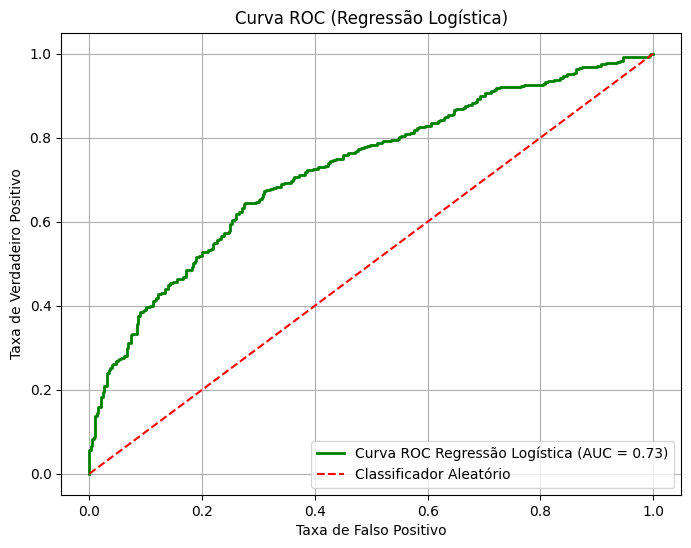

In [ ]:
# Fazer previsões no conjunto de teste
y_pred_logistic = logistic_model.predict(X_test)
y_pred_proba_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Avaliar a performance do modelo
print("Relatório de Classificação (Regressão Logística):")
print(classification_report(y_test, y_pred_logistic))

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_pred_proba_logistic)

print(f"Acurácia (Regressão Logística): {accuracy_logistic:.2f}")
print(f"ROC AUC Score (Regressão Logística): {roc_auc_logistic:.2f}")

# Plotar a Curva ROC
fpr_logistic, tpr_logistic, _ = roc_curve(y_test, y_pred_proba_logistic)
plt.figure(figsize=(8, 6))
plt.plot(fpr_logistic, tpr_logistic, color='green', lw=2, label=f'Curva ROC Regressão Logística (AUC = {roc_auc_logistic:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
plt.xlabel('Taxa de Falso Positivo')
plt.ylabel('Taxa de Verdadeiro Positivo')
plt.title('Curva ROC (Regressão Logística)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Para a Regressão Logística, podemos analisar os coeficientes para entender a importância das features.

,Feature,Coefficient
1,Frequency_obs,0.204989
2,Monetary_obs,0.000328
0,Recency_obs,-0.003652


/tmp/ipykernel_439/2639583963.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic, palette='magma')


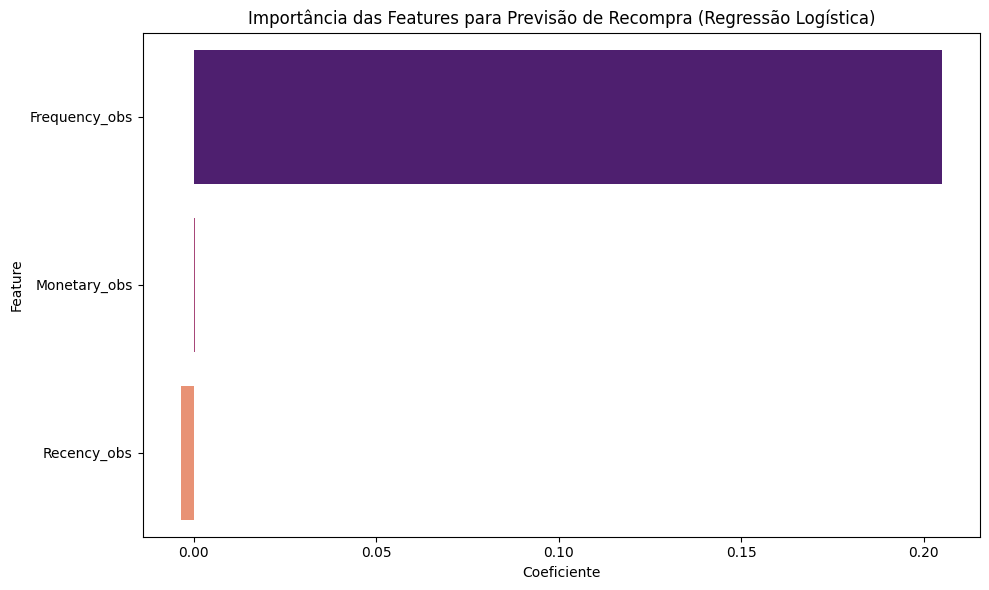

In [ ]:
# Importância das Features (Coeficientes da Regressão Logística)
feature_importances_logistic = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': logistic_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

display(feature_importances_logistic)

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic, palette='magma')
plt.title('Importância das Features para Previsão de Recompra (Regressão Logística)')
plt.xlabel('Coeficiente')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Finalmente, vamos prever a probabilidade de recompra para todos os clientes usando o modelo de Regressão Logística e priorizá-los.

In [ ]:
# Prever a probabilidade de recompra para todos os clientes no dataset original
all_customer_probabilities_logistic = logistic_model.predict_proba(X)[:, 1]

# Adicionar as probabilidades ao model_df
model_df['Repurchase_Probability_Logistic'] = all_customer_probabilities_logistic

# Classificar clientes com base na probabilidade de recompra (do maior para o menor)
prioritized_customers_logistic = model_df.sort_values(by='Repurchase_Probability_Logistic', ascending=False)

display(prioritized_customers_logistic[['ID', 'Recency_obs', 'Frequency_obs', 'Monetary_obs', 'Repurchase_Probability_Logistic', 'Repurchase_60_Days']].head(10))

print("Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias (Regressão Logística).")

,ID,Recency_obs,Frequency_obs,Monetary_obs,Repurchase_Probability_Logistic,Repurchase_60_Days
62,14911.0,0,133,78552.24,1.0,1
43,12748.0,1,143,17826.19,1.0,1
225,13089.0,3,77,40195.24,1.0,1
66,17841.0,3,94,25476.99,1.0,1
822,14646.0,4,41,44237.97,1.0,1
7,15311.0,3,72,20656.71,1.0,1
192,14156.0,10,37,36795.89,1.0,1
87,14606.0,0,78,9334.36,1.0,1
672,14298.0,11,37,34226.85,1.0,1
160,12971.0,5,67,7518.17,1.0,1


Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias (Regressão Logística).


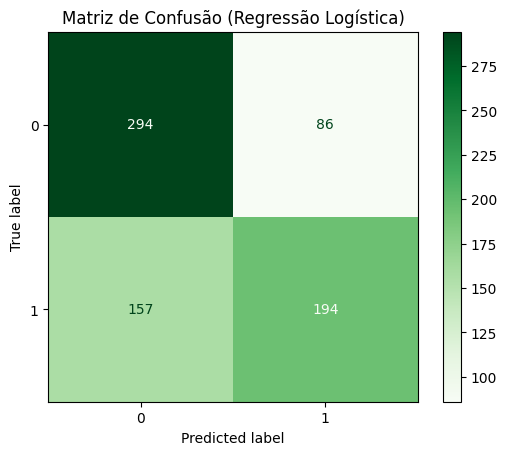

In [ ]:
# Calcular a matriz de confusão para o modelo de Regressão Logística
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Exibir a matriz de confusão
disp_logistic = ConfusionMatrixDisplay(confusion_matrix=cm_logistic, display_labels=logistic_model.classes_)
disp_logistic.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (Regressão Logística)')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Recalcular as métricas de Precision, Recall, F1-Score, Accuracy e ROC AUC para o modelo de Regressão Logística
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)
roc_auc = roc_auc_score(y_test, y_pred_proba_logistic)

print(f"Métricas do Modelo de Regressão Logística:\n")
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC AUC Score: {roc_auc:.4f}")

Métricas do Modelo de Regressão Logística:

Acurácia: 0.6676
Precisão: 0.6929
Recall: 0.5527
F1-Score: 0.6149
ROC AUC Score: 0.7267


### Random Forest

In [ ]:
# Definir as features (X) e a variável target (y)
X_rf = model_df[['Recency_obs', 'Frequency_obs', 'Monetary_obs']]
y_rf = model_df['Repurchase_60_Days']

# Dividir os dados em conjuntos de treino e teste
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf)

# Treinar o modelo RandomForestClassifier
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced') # class_weight para lidar com desbalanceamento
model_rf.fit(X_train_rf, y_train_rf)

print("Modelo Random Forest treinado com sucesso!")

Modelo Random Forest treinado com sucesso!


Relatório de Classificação (Random Forest):
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       380
           1       0.62      0.55      0.58       351

    accuracy                           0.62       731
   macro avg       0.62      0.62      0.62       731
weighted avg       0.62      0.62      0.62       731

Acurácia (Random Forest): 0.62
ROC AUC Score (Random Forest): 0.68


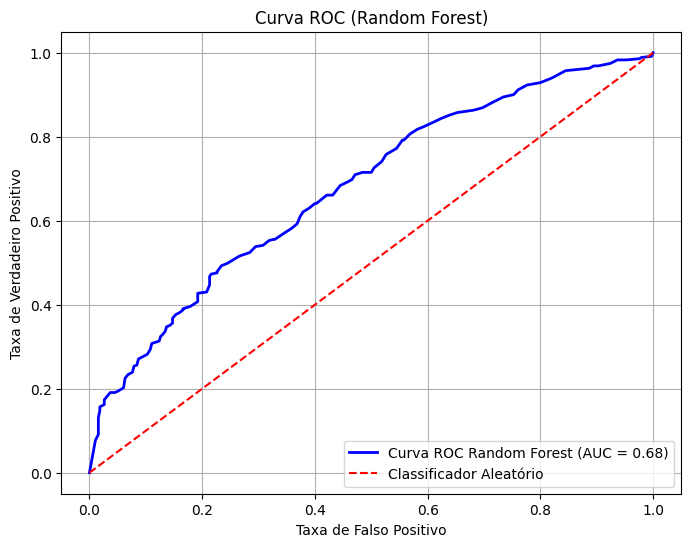

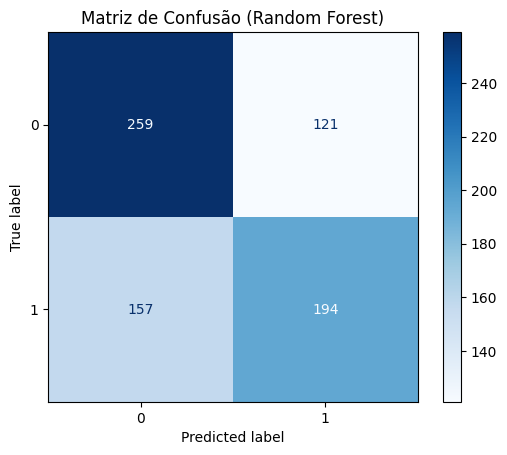

In [ ]:
# Fazer previsões no conjunto de teste
y_pred_rf = model_rf.predict(X_test_rf)
y_pred_proba_rf = model_rf.predict_proba(X_test_rf)[:, 1]

# Avaliar a performance do modelo
print("Relatório de Classificação (Random Forest):")
print(classification_report(y_test_rf, y_pred_rf))

accuracy_rf = accuracy_score(y_test_rf, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test_rf, y_pred_proba_rf)

print(f"Acurácia (Random Forest): {accuracy_rf:.2f}")
print(f"ROC AUC Score (Random Forest): {roc_auc_rf:.2f}")

# Plotar a Curva ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test_rf, y_pred_proba_rf)
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'Curva ROC Random Forest (AUC = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
plt.xlabel('Taxa de Falso Positivo')
plt.ylabel('Taxa de Verdadeiro Positivo')
plt.title('Curva ROC (Random Forest)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Calcular a matriz de confusão para o modelo Random Forest
cm_rf = confusion_matrix(y_test_rf, y_pred_rf)

# Exibir a matriz de confusão
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=model_rf.classes_)
disp_rf.plot(cmap=plt.cm.Blues)
plt.title('Matriz de Confusão (Random Forest)')
plt.show()

,Feature,Importance
2,Monetary_obs,0.50392
0,Recency_obs,0.37221
1,Frequency_obs,0.12387


/tmp/ipykernel_439/449770663.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances_rf, palette='viridis')


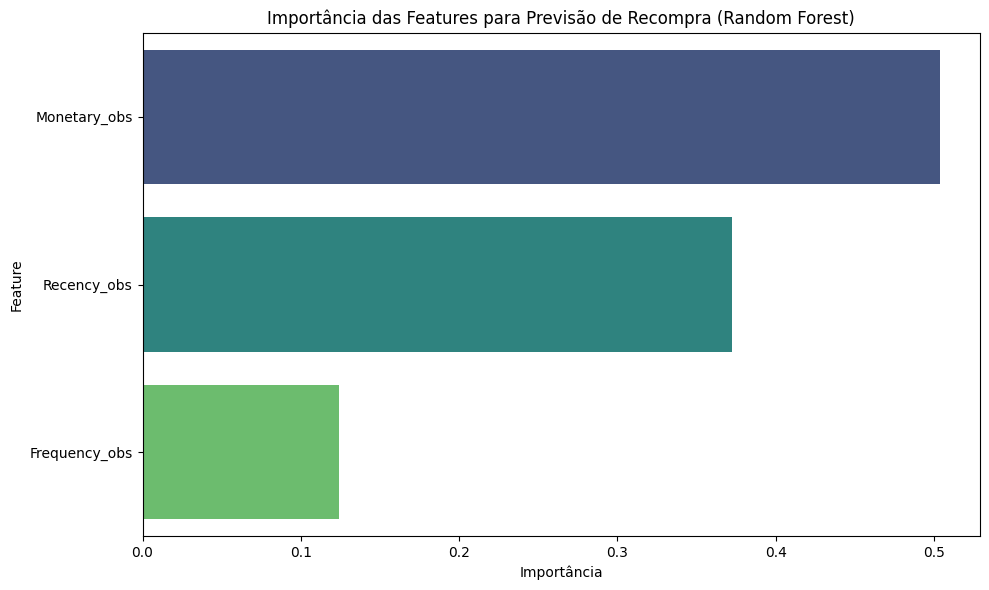

In [ ]:
# Importância das Features
feature_importances_rf = pd.DataFrame({
    'Feature': X_rf.columns,
    'Importance': model_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(feature_importances_rf)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances_rf, palette='viridis')
plt.title('Importância das Features para Previsão de Recompra (Random Forest)')
plt.xlabel('Importância')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# Prever a probabilidade de recompra para todos os clientes no dataset original
all_customer_probabilities_rf = model_rf.predict_proba(X_rf)[:, 1]

# Adicionar as probabilidades ao model_df
model_df['Repurchase_Probability_RF'] = all_customer_probabilities_rf

# Classificar clientes com base na probabilidade de recompra (do maior para o menor)
prioritized_customers_rf = model_df.sort_values(by='Repurchase_Probability_RF', ascending=False)

display(prioritized_customers_rf[['ID', 'Recency_obs', 'Frequency_obs', 'Monetary_obs', 'Repurchase_Probability_RF', 'Repurchase_60_Days']].head(10))

print("Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias (Random Forest).")

,ID,Recency_obs,Frequency_obs,Monetary_obs,Repurchase_Probability_RF,Repurchase_60_Days
5,14688.0,10,17,4355.47,1.0,1
33,13694.0,11,33,12448.64,1.0,1
22,15513.0,34,16,10014.34,1.0,1
18,13767.0,0,34,11319.68,1.0,1
17,13408.0,6,46,14598.74,1.0,1
14,17511.0,5,23,28270.36,1.0,1
13,12431.0,4,12,4652.58,1.0,1
11,16029.0,5,36,7709.09,1.0,1
7,15311.0,3,72,20656.71,1.0,1
43,12748.0,1,143,17826.19,1.0,1


Clientes priorizados com base na probabilidade de recompra nos próximos 60 dias (Random Forest).


## Etapa 2 de testes

Vamos calcular as novas variáveis agregadas por cliente para a janela de observação (`df_observation`) 120 dias:

*   **Quantidade Total de Itens Comprados (`TotalQuantity_obs`):** Soma das quantidades de todos os itens comprados.
*   **Diversidade de Produtos (`UniqueItemsPurchased_obs`):** Número de produtos únicos comprados por cliente.
*   **País Principal (`MainCountry_obs`):** O país de onde o cliente realizou a maioria de suas compras.
*   **Taxa de Cancelamento (`CancellationRate_obs`):** Proporção de pedidos cancelados pelo cliente na janela de observação.
*   **Média de Dias entre Pedidos (`AvgDaysBetweenOrders_obs`):** Média do tempo (em dias) entre as compras consecutivas do cliente.

In [ ]:
# Calcular Quantidade Total e Itens Únicos por cliente na janela de observação
observation_agg_features = df_observation.groupby('CustomerID').agg(
    TotalQuantity_obs=('Quantity', 'sum'),
    UniqueItemsPurchased_obs=('StockCode', 'nunique')
).reset_index()

# Renomear 'CustomerID' para 'ID' para facilitar o merge
observation_agg_features.rename(columns={'CustomerID': 'ID'}, inplace=True)

display(observation_agg_features.head())
print(f"Shape de observation_agg_features: {observation_agg_features.shape}")

,ID,TotalQuantity_obs,UniqueItemsPurchased_obs
0,12347.0,1350,81
1,12348.0,236,8
2,12350.0,196,16
3,12352.0,401,45
4,12353.0,20,4


Shape de observation_agg_features: (3654, 3)


In [ ]:
# Calcular País Principal por Cliente na janela de observação
main_country_obs = df_observation.groupby('CustomerID')['Country'].agg(lambda x: x.mode()[0]).reset_index()
main_country_obs.rename(columns={'CustomerID': 'ID', 'Country': 'MainCountry_obs'}, inplace=True)

display(main_country_obs.head())
print(f"Shape de main_country_obs: {main_country_obs.shape}")

,ID,MainCountry_obs
0,12347.0,Iceland
1,12348.0,Finland
2,12350.0,Norway
3,12352.0,Norway
4,12353.0,Bahrain


Shape de main_country_obs: (3654, 2)


In [ ]:
# Calcular Taxa de Cancelamento por Cliente na janela de observação

# Filtrar cancelamentos apenas na janela de observação
cancelados_obs_window = cancelados[(cancelados['InvoiceDate'] <= prediction_window_start)]

# Contar pedidos cancelados por cliente
cancelled_orders_per_customer = cancelados_obs_window.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
cancelled_orders_per_customer.rename(columns={'InvoiceNo': 'CancelledOrders_obs', 'CustomerID': 'ID'}, inplace=True)

# Contar todos os pedidos (válidos) por cliente na janela de observação
total_orders_per_customer = df_observation.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
total_orders_per_customer.rename(columns={'InvoiceNo': 'TotalOrders_obs', 'CustomerID': 'ID'}, inplace=True)

# Merge para calcular a taxa de cancelamento
cancellation_features = pd.merge(
    total_orders_per_customer, cancelled_orders_per_customer, on='ID', how='left'
)
cancellation_features['CancelledOrders_obs'] = cancellation_features['CancelledOrders_obs'].fillna(0)

cancellation_features['CancellationRate_obs'] = (
    cancellation_features['CancelledOrders_obs'] / cancellation_features['TotalOrders_obs']
).fillna(0) # Clientes sem cancelamentos terão taxa 0

cancellation_features = cancellation_features[['ID', 'CancellationRate_obs']]

display(cancellation_features.head())
print(f"Shape de cancellation_features: {cancellation_features.shape}")

,ID,CancellationRate_obs
0,12347.0,0.0
1,12348.0,0.0
2,12350.0,0.0
3,12352.0,0.5
4,12353.0,0.0


Shape de cancellation_features: (3654, 2)


In [ ]:
# Calcular Média de Dias entre Pedidos por Cliente na janela de observação

def calculate_avg_days_between_orders(customer_df):
    if len(customer_df) < 2:
        return 0  # Não há intervalos se houver menos de 2 pedidos
    customer_df = customer_df.sort_values(by='InvoiceDate')
    time_diffs = customer_df['InvoiceDate'].diff().dropna()
    avg_days = time_diffs.apply(lambda x: x.days).mean()
    return avg_days if not pd.isna(avg_days) else 0


avg_days_between_orders_obs = df_observation.groupby('CustomerID').apply(calculate_avg_days_between_orders).reset_index(name='AvgDaysBetweenOrders_obs')
avg_days_between_orders_obs.rename(columns={'CustomerID': 'ID'}, inplace=True)

display(avg_days_between_orders_obs.head())
print(f"Shape de avg_days_between_orders_obs: {avg_days_between_orders_obs.shape}")

/tmp/ipykernel_439/1514111007.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  avg_days_between_orders_obs = df_observation.groupby('CustomerID').apply(calculate_avg_days_between_orders).reset_index(name='AvgDaysBetweenOrders_obs')


,ID,AvgDaysBetweenOrders_obs
0,12347.0,1.926230
1,12348.0,15.571429
2,12350.0,0.000000
3,12352.0,3.596774
4,12353.0,0.000000


Shape de avg_days_between_orders_obs: (3654, 2)


In [ ]:
# Unir todas as novas features com o DataFrame de RFM já existente (rfm_features_observation)
expanded_features_observation = pd.merge(rfm_features_observation, observation_agg_features, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, main_country_obs, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, cancellation_features, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, avg_days_between_orders_obs, on='ID', how='left')

# Unir o conjunto de features expandido com a variável target (model_df)
model_df_expanded = pd.merge(target_df, expanded_features_observation, on='ID', how='left')

# Preencher NaNs que podem ter surgido para clientes que não tinham atividade em alguma métrica
model_df_expanded['TotalQuantity_obs'] = model_df_expanded['TotalQuantity_obs'].fillna(0)
model_df_expanded['UniqueItemsPurchased_obs'] = model_df_expanded['UniqueItemsPurchased_obs'].fillna(0)
model_df_expanded['CancellationRate_obs'] = model_df_expanded['CancellationRate_obs'].fillna(0)
model_df_expanded['AvgDaysBetweenOrders_obs'] = model_df_expanded['AvgDaysBetweenOrders_obs'].fillna(0)

# Para MainCountry_obs, preencher com um valor 'Unknown' ou o país mais comum se houver NaNs
model_df_expanded['MainCountry_obs'] = model_df_expanded['MainCountry_obs'].fillna('Unknown')


display(model_df_expanded.head())
display(model_df_expanded.isnull().sum())
print(f"Shape de model_df_expanded: {model_df_expanded.shape}")

,ID,Repurchase_60_Days,Recency_obs,Frequency_obs,Monetary_obs,TotalQuantity_obs,UniqueItemsPurchased_obs,MainCountry_obs,CancellationRate_obs,AvgDaysBetweenOrders_obs
0,17850.0,0,311,34,4783.46,1716,20,United Kingdom,0.029412,0.000000
1,13047.0,1,66,8,2682.01,1164,84,United Kingdom,0.750000,1.762590
2,12583.0,1,9,11,4273.15,2537,91,France,0.181818,1.868750
3,15100.0,0,273,3,876.00,80,1,United Kingdom,1.000000,19.500000
4,15291.0,1,34,10,2619.06,720,54,United Kingdom,0.500000,3.525641


,0
ID,0
Repurchase_60_Days,0
Recency_obs,0
Frequency_obs,0
Monetary_obs,0
TotalQuantity_obs,0
UniqueItemsPurchased_obs,0
MainCountry_obs,0
CancellationRate_obs,0
AvgDaysBetweenOrders_obs,0


Shape de model_df_expanded: (3654, 10)


In [ ]:
# One-Hot Encoding para 'MainCountry_obs'
model_df_expanded = pd.get_dummies(model_df_expanded, columns=['MainCountry_obs'], prefix='Country', dummy_na=False)

# Definir as features (X_new) e a variável target (y_new)
# Excluir 'ID' e 'Repurchase_60_Days'
X_new = model_df_expanded.drop(columns=['ID', 'Repurchase_60_Days'])
y_new = model_df_expanded['Repurchase_60_Days']

# Dividir os dados em conjuntos de treino e teste
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new, y_new, test_size=0.2, random_state=42, stratify=y_new)

print(f"Shape de X_train_new: {X_train_new.shape}")
print(f"Shape de X_test_new: {X_test_new.shape}")
print(f"Features utilizadas: {X_new.columns.tolist()}")

Shape de X_train_new: (2923, 43)
Shape de X_test_new: (731, 43)
Features utilizadas: ['Recency_obs', 'Frequency_obs', 'Monetary_obs', 'TotalQuantity_obs', 'UniqueItemsPurchased_obs', 'CancellationRate_obs', 'AvgDaysBetweenOrders_obs', 'Country_Australia', 'Country_Austria', 'Country_Bahrain', 'Country_Belgium', 'Country_Brazil', 'Country_Canada', 'Country_Channel Islands', 'Country_Cyprus', 'Country_Czech Republic', 'Country_Denmark', 'Country_EIRE', 'Country_European Community', 'Country_Finland', 'Country_France', 'Country_Germany', 'Country_Greece', 'Country_Iceland', 'Country_Israel', 'Country_Italy', 'Country_Japan', 'Country_Lebanon', 'Country_Lithuania', 'Country_Malta', 'Country_Netherlands', 'Country_Norway', 'Country_Poland', 'Country_Portugal', 'Country_Saudi Arabia', 'Country_Singapore', 'Country_Spain', 'Country_Sweden', 'Country_Switzerland', 'Country_USA', 'Country_United Arab Emirates', 'Country_United Kingdom', 'Country_Unspecified']


### Regressão Logística

In [ ]:
# Treinar o modelo de Regressão Logística com as features expandidas
logistic_model_expanded = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model_expanded.fit(X_train_new, y_train_new)

print("Modelo de Regressão Logística (Features Expandidas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_logistic_expanded = logistic_model_expanded.predict(X_test_new)
y_pred_proba_logistic_expanded = logistic_model_expanded.predict_proba(X_test_new)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (Regressão Logística - Features Expandidas):")
print(classification_report(y_test_new, y_pred_logistic_expanded))

accuracy_logistic_expanded = accuracy_score(y_test_new, y_pred_logistic_expanded)
precision_logistic_expanded = precision_score(y_test_new, y_pred_logistic_expanded, pos_label=1)
recall_logistic_expanded = recall_score(y_test_new, y_pred_logistic_expanded, pos_label=1)
f1_logistic_expanded = f1_score(y_test_new, y_pred_logistic_expanded, pos_label=1)
roc_auc_logistic_expanded = roc_auc_score(y_test_new, y_pred_proba_logistic_expanded)

print(f"Acurácia (Regressão Logística - Expandida): {accuracy_logistic_expanded:.4f}")
print(f"Precisão (Regressão Logística - Expandida): {precision_logistic_expanded:.4f}")
print(f"Recall (Regressão Logística - Expandida): {recall_logistic_expanded:.4f}")
print(f"F1-Score (Regressão Logística - Expandida): {f1_logistic_expanded:.4f}")
print(f"ROC AUC Score (Regressão Logística - Expandida): {roc_auc_logistic_expanded:.4f}")

Modelo de Regressão Logística (Features Expandidas) treinado com sucesso!

Relatório de Classificação (Regressão Logística - Features Expandidas):
              precision    recall  f1-score   support

           0       0.66      0.78      0.71       380
           1       0.70      0.56      0.62       351

    accuracy                           0.67       731
   macro avg       0.68      0.67      0.67       731
weighted avg       0.68      0.67      0.67       731

Acurácia (Regressão Logística - Expandida): 0.6717
Precisão (Regressão Logística - Expandida): 0.6975
Recall (Regressão Logística - Expandida): 0.5584
F1-Score (Regressão Logística - Expandida): 0.6203
ROC AUC Score (Regressão Logística - Expandida): 0.7281


### Random Forest

In [ ]:
# Treinar o modelo Random Forest com as features expandidas
rf_model_expanded = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model_expanded.fit(X_train_new, y_train_new)

print("Modelo Random Forest (Features Expandidas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_rf_expanded = rf_model_expanded.predict(X_test_new)
y_pred_proba_rf_expanded = rf_model_expanded.predict_proba(X_test_new)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (Random Forest - Features Expandidas):")
print(classification_report(y_test_new, y_pred_rf_expanded))

accuracy_rf_expanded = accuracy_score(y_test_new, y_pred_rf_expanded)
precision_rf_expanded = precision_score(y_test_new, y_pred_rf_expanded, pos_label=1)
recall_rf_expanded = recall_score(y_test_new, y_pred_rf_expanded, pos_label=1)
f1_rf_expanded = f1_score(y_test_new, y_pred_rf_expanded, pos_label=1)
roc_auc_rf_expanded = roc_auc_score(y_test_new, y_pred_proba_rf_expanded)

print(f"Acurácia (Random Forest - Expandida): {accuracy_rf_expanded:.4f}")
print(f"Precisão (Random Forest - Expandida): {precision_rf_expanded:.4f}")
print(f"Recall (Random Forest - Expandida): {recall_rf_expanded:.4f}")
print(f"F1-Score (Random Forest - Expandida): {f1_rf_expanded:.4f}")
print(f"ROC AUC Score (Random Forest - Expandida): {roc_auc_rf_expanded:.4f}")

Modelo Random Forest (Features Expandidas) treinado com sucesso!

Relatório de Classificação (Random Forest - Features Expandidas):
              precision    recall  f1-score   support

           0       0.65      0.74      0.69       380
           1       0.67      0.56      0.61       351

    accuracy                           0.65       731
   macro avg       0.66      0.65      0.65       731
weighted avg       0.66      0.65      0.65       731

Acurácia (Random Forest - Expandida): 0.6539
Precisão (Random Forest - Expandida): 0.6655
Recall (Random Forest - Expandida): 0.5613
F1-Score (Random Forest - Expandida): 0.6090
ROC AUC Score (Random Forest - Expandida): 0.7041


### Árvore de Decisão

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Treinar o modelo de Árvore de Decisão com as features expandidas
dtc_model_expanded = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dtc_model_expanded.fit(X_train_new, y_train_new)

print("Modelo de Árvore de Decisão (Features Expandidas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_dtc_expanded = dtc_model_expanded.predict(X_test_new)
y_pred_proba_dtc_expanded = dtc_model_expanded.predict_proba(X_test_new)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (Árvore de Decisão - Features Expandidas):")
print(classification_report(y_test_new, y_pred_dtc_expanded))

accuracy_dtc_expanded = accuracy_score(y_test_new, y_pred_dtc_expanded)
precision_dtc_expanded = precision_score(y_test_new, y_pred_dtc_expanded, pos_label=1)
recall_dtc_expanded = recall_score(y_test_new, y_pred_dtc_expanded, pos_label=1)
f1_dtc_expanded = f1_score(y_test_new, y_pred_dtc_expanded, pos_label=1)
roc_auc_dtc_expanded = roc_auc_score(y_test_new, y_pred_proba_dtc_expanded)

print(f"Acurácia (Árvore de Decisão - Expandida): {accuracy_dtc_expanded:.4f}")
print(f"Precisão (Árvore de Decisão - Expandida): {precision_dtc_expanded:.4f}")
print(f"Recall (Árvore de Decisão - Expandida): {recall_dtc_expanded:.4f}")
print(f"F1-Score (Árvore de Decisão - Expandida): {f1_dtc_expanded:.4f}")
print(f"ROC AUC Score (Árvore de Decisão - Expandida): {roc_auc_dtc_expanded:.4f}")

Modelo de Árvore de Decisão (Features Expandidas) treinado com sucesso!

Relatório de Classificação (Árvore de Decisão - Features Expandidas):
              precision    recall  f1-score   support

           0       0.58      0.60      0.59       380
           1       0.55      0.53      0.54       351

    accuracy                           0.57       731
   macro avg       0.57      0.57      0.57       731
weighted avg       0.57      0.57      0.57       731

Acurácia (Árvore de Decisão - Expandida): 0.5677
Precisão (Árvore de Decisão - Expandida): 0.5519
Recall (Árvore de Decisão - Expandida): 0.5299
F1-Score (Árvore de Decisão - Expandida): 0.5407
ROC AUC Score (Árvore de Decisão - Expandida): 0.5663


### Gradient Boosting (LightGBM)

In [ ]:
import lightgbm as lgb

# Treinar o modelo LightGBM com as features expandidas
lgbm_model_expanded = lgb.LGBMClassifier(objective='binary', random_state=42, is_unbalance=True) # is_unbalance para lidar com desbalanceamento
lgbm_model_expanded.fit(X_train_new, y_train_new)

print("Modelo LightGBM (Features Expandidas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_lgbm_expanded = lgbm_model_expanded.predict(X_test_new)
y_pred_proba_lgbm_expanded = lgbm_model_expanded.predict_proba(X_test_new)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (LightGBM - Features Expandidas):")
print(classification_report(y_test_new, y_pred_lgbm_expanded))

accuracy_lgbm_expanded = accuracy_score(y_test_new, y_pred_lgbm_expanded)
precision_lgbm_expanded = precision_score(y_test_new, y_pred_lgbm_expanded, pos_label=1)
recall_lgbm_expanded = recall_score(y_test_new, y_pred_lgbm_expanded, pos_label=1)
f1_lgbm_expanded = f1_score(y_test_new, y_pred_lgbm_expanded, pos_label=1)
roc_auc_lgbm_expanded = roc_auc_score(y_test_new, y_pred_proba_lgbm_expanded)

print(f"Acurácia (LightGBM - Expandida): {accuracy_lgbm_expanded:.4f}")
print(f"Precisão (LightGBM - Expandida): {precision_lgbm_expanded:.4f}")
print(f"Recall (LightGBM - Expandida): {recall_lgbm_expanded:.4f}")
print(f"F1-Score (LightGBM - Expandida): {f1_lgbm_expanded:.4f}")
print(f"ROC AUC Score (LightGBM - Expandida): {roc_auc_lgbm_expanded:.4f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1405, number of negative: 1518
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000850 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1323
[LightGBM] [Info] Number of data points in the train set: 2923, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.480671 -> initscore=-0.077356
[LightGBM] [Info] Start training from score -0.077356
Modelo LightGBM (Features Expandidas) treinado com sucesso!

Relatório de Classificação (LightGBM - Features Expandidas):
              precision    recall  f1-score   support

           0       0.63      0.72      0.67       380
           1       0.64      0.55      0.59       351

    accuracy                           0.64       731
   macro avg       0.64      0.63      0.63       731
weighted avg       0.64      0.64  

### Comparativo Final dos Modelos

Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):


,Feature,Coefficient
5,CancellationRate_obs,0.299554
1,Frequency_obs,0.195427
31,Country_Norway,0.037858
25,Country_Italy,0.032923
16,Country_Denmark,0.011542
29,Country_Malta,0.010810
30,Country_Netherlands,0.010590
19,Country_Finland,0.010363
23,Country_Iceland,0.007020
4,UniqueItemsPurchased_obs,0.005079


/tmp/ipykernel_439/1664572291.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')


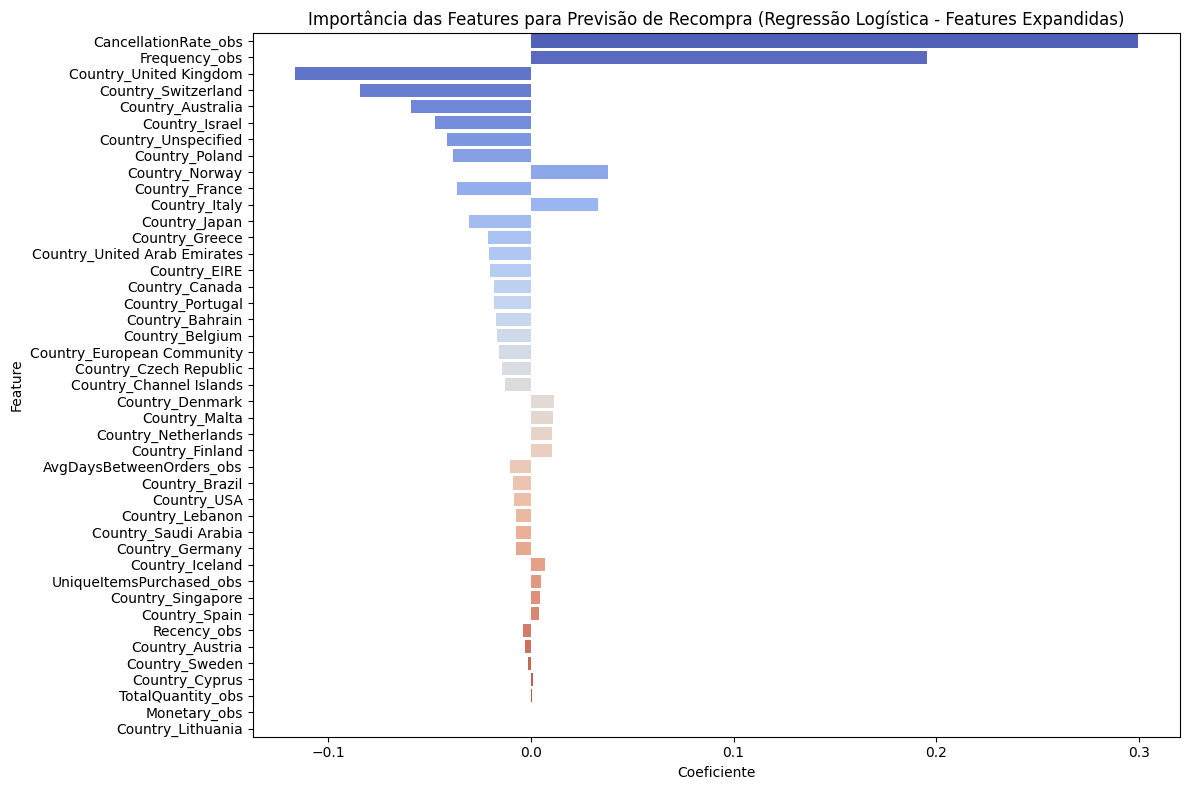

In [ ]:
feature_importances_logistic_expanded = pd.DataFrame({
    'Feature': X_new.columns,
    'Coefficient': logistic_model_expanded.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):")
display(feature_importances_logistic_expanded)

plt.figure(figsize=(12, 8))
sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')
plt.title('Importância das Features para Previsão de Recompra (Regressão Logística - Features Expandidas)')
plt.xlabel('Coeficiente')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):


,Feature,Coefficient
5,CancellationRate_obs,0.299554
1,Frequency_obs,0.195427
31,Country_Norway,0.037858
25,Country_Italy,0.032923
16,Country_Denmark,0.011542
29,Country_Malta,0.010810
30,Country_Netherlands,0.010590
19,Country_Finland,0.010363
23,Country_Iceland,0.007020
4,UniqueItemsPurchased_obs,0.005079


/tmp/ipykernel_439/2525967331.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')


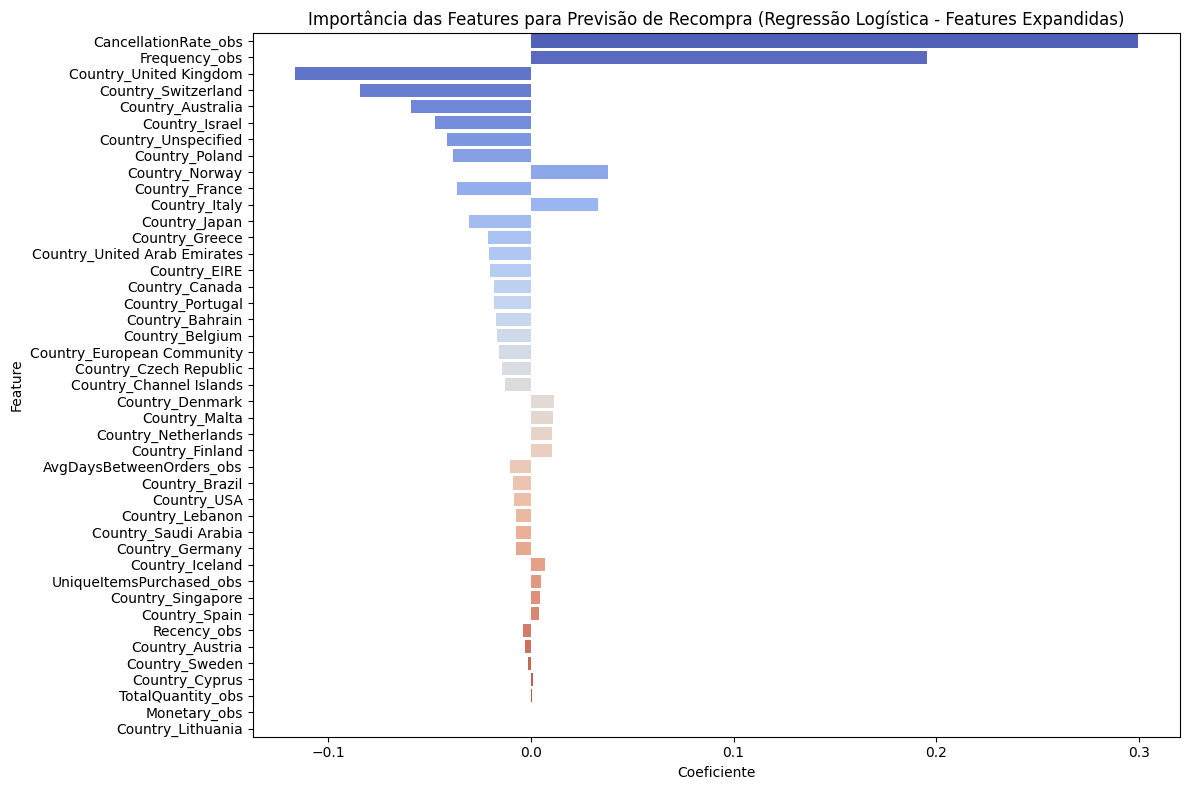

In [ ]:
# The cell `ec07ebed` needs to be executed before `bf5862c1` to define `feature_importances_logistic_expanded`.
# I am re-inserting the content here for clarity on the execution order.
feature_importances_logistic_expanded = pd.DataFrame({
    'Feature': X_new.columns,
    'Coefficient': logistic_model_expanded.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):")
display(feature_importances_logistic_expanded)

plt.figure(figsize=(12, 8))
sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')
plt.title('Importância das Features para Previsão de Recompra (Regressão Logística - Features Expandidas)')
plt.xlabel('Coeficiente')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# This is the content of cell `bf5862c1`, which depends on `feature_importances_logistic_expanded`.
# Filtrar as features com base na importância (valor absoluto do coeficiente)
# Vamos usar um limiar para selecionar as features mais impactantes.
# Por exemplo, selecionaremos features com valor absoluto do coeficiente maior que 0.1.
selected_features_df = feature_importances_logistic_expanded[feature_importances_logistic_expanded['Coefficient'].abs() > 0.1]
selected_feature_names = selected_features_df['Feature'].tolist()

print(f"Features selecionadas ({len(selected_feature_names)}):\n{selected_feature_names}")

# Criar o novo conjunto de features (X_final_selected)
X_final_selected = X_new[selected_feature_names]
y_final_selected = y_new

# Dividir os dados em conjuntos de treino e teste com as features selecionadas
X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(X_final_selected, y_final_selected, test_size=0.2, random_state=42, stratify=y_final_selected)

print(f"\nShape de X_train_selected: {X_train_selected.shape}")
print(f"Shape de X_test_selected: {X_test_selected.shape}")

Features selecionadas (3):
['CancellationRate_obs', 'Frequency_obs', 'Country_United Kingdom']

Shape de X_train_selected: (2923, 3)
Shape de X_test_selected: (731, 3)


Modelo de Regressão Logística (Features Selecionadas) treinado com sucesso!

Relatório de Classificação (Regressão Logística - Features Selecionadas):
              precision    recall  f1-score   support

           0       0.63      0.82      0.72       380
           1       0.72      0.48      0.58       351

    accuracy                           0.66       731
   macro avg       0.67      0.65      0.65       731
weighted avg       0.67      0.66      0.65       731

Acurácia (Regressão Logística - Selecionada): 0.6594
Precisão (Regressão Logística - Selecionada): 0.7161
Recall (Regressão Logística - Selecionada): 0.4815
F1-Score (Regressão Logística - Selecionada): 0.5758
ROC AUC Score (Regressão Logística - Selecionada): 0.7177


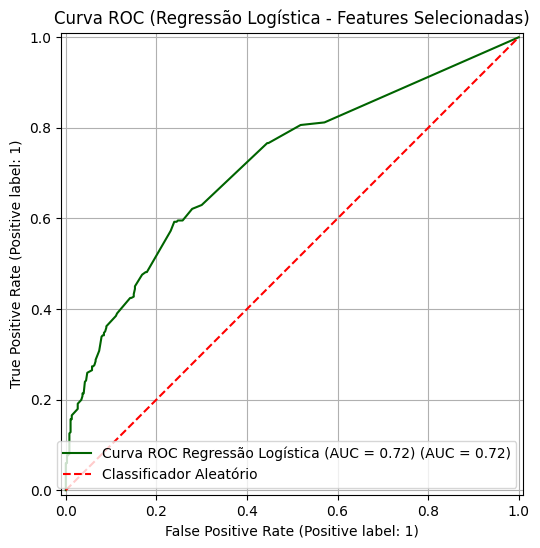

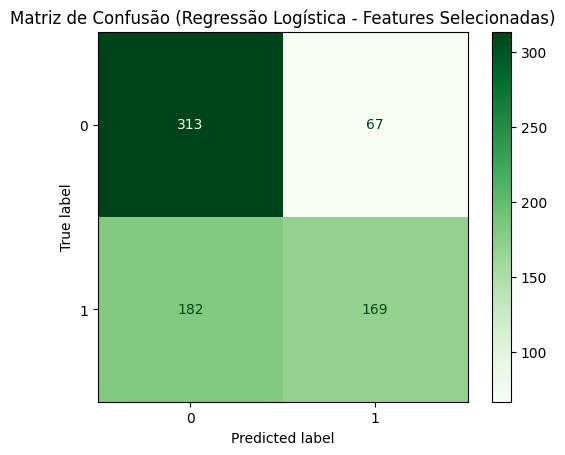

In [ ]:
# This is the content of cell `203e1cc7`, which depends on the output of cell `bf5862c1`.
# Treinar o modelo de Regressão Logística com as features selecionadas
logistic_model_selected = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model_selected.fit(X_train_selected, y_train_selected)

print("Modelo de Regressão Logística (Features Selecionadas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_logistic_selected = logistic_model_selected.predict(X_test_selected)
y_pred_proba_logistic_selected = logistic_model_selected.predict_proba(X_test_selected)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (Regressão Logística - Features Selecionadas):")
print(classification_report(y_test_selected, y_pred_logistic_selected))

accuracy_logistic_selected = accuracy_score(y_test_selected, y_pred_logistic_selected)
precision_logistic_selected = precision_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
recall_logistic_selected = recall_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
f1_logistic_selected = f1_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
roc_auc_logistic_selected = roc_auc_score(y_test_selected, y_pred_proba_logistic_selected)

print(f"Acurácia (Regressão Logística - Selecionada): {accuracy_logistic_selected:.4f}")
print(f"Precisão (Regressão Logística - Selecionada): {precision_logistic_selected:.4f}")
print(f"Recall (Regressão Logística - Selecionada): {recall_logistic_selected:.4f}")
print(f"F1-Score (Regressão Logística - Selecionada): {f1_logistic_selected:.4f}")
print(f"ROC AUC Score (Regressão Logística - Selecionada): {roc_auc_logistic_selected:.4f}")

# Plotar a Curva ROC
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(logistic_model_selected, X_test_selected, y_test_selected, ax=ax, name=f'Curva ROC Regressão Logística (AUC = {roc_auc_logistic_selected:.2f})', color='darkgreen')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Regressão Logística - Features Selecionadas)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

# Plotar Matriz de Confusão
cm_logistic_selected = confusion_matrix(y_test_selected, y_pred_logistic_selected)
disp_logistic_selected = ConfusionMatrixDisplay(confusion_matrix=cm_logistic_selected, display_labels=logistic_model_selected.classes_)
disp_logistic_selected.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (Regressão Logística - Features Selecionadas)')
plt.show()

In [ ]:
# This is the content of cell `345edab5`, which depends on the output of cell `203e1cc7`.
# Adicionar os resultados do modelo com features selecionadas à tabela comparativa
overall_model_comparison_final_updated = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)', 'ROC AUC Score'],
    'XGBoost': [
        accuracy_xgb_final,
        precision_xgb_final,
        recall_xgb_final,
        f1_xgb_final,
        roc_auc_xgb_final
    ],
    'Logistic Regression (RFM)': [
        accuracy_logistic_final,
        precision_logistic_final,
        recall_logistic_final,
        f1_logistic_final,
        roc_auc_logistic_final
    ],
    'Decision Tree': [
        accuracy_dtc_final,
        precision_dtc_final,
        recall_dtc_final,
        f1_dtc_final,
        roc_auc_dtc_final
    ],
    'Random Forest': [
        accuracy_rf_final,
        precision_rf_final,
        recall_rf_final,
        f1_rf_final,
        roc_auc_rf_final
    ],
    'LightGBM': [
        accuracy_lgbm_final,
        precision_lgbm_final,
        recall_lgbm_final,
        f1_lgbm_final,
        roc_auc_lgbm_final
    ],
    'Logistic Regression (Selected Features)': [
        accuracy_logistic_selected,
        precision_logistic_selected,
        recall_logistic_selected,
        f1_logistic_selected,
        roc_auc_logistic_selected
    ]
})

display(overall_model_comparison_final_updated)

best_f1_model_updated = overall_model_comparison_final_updated.loc[overall_model_comparison_final_updated['Métrica'] == 'F1-Score (Classe 1)'].iloc[0]

best_model_name_updated = best_f1_model_updated.drop('Métrica').idxmax()
best_f1_score_updated = best_f1_model_updated.drop('Métrica').max()

print(f"\nO melhor modelo com base no F1-Score da classe 1 é: {best_model_name_updated} com F1-Score: {best_f1_score_updated:.4f}")

,Métrica,XGBoost,Logistic Regression (RFM),Decision Tree,Random Forest,LightGBM,Logistic Regression (Selected Features)
0,Acurácia,0.489740,0.519836,0.512996,0.492476,0.489740,0.659371
1,Precisão (Classe 1),0.467262,0.500000,0.492837,0.467320,0.468750,0.716102
2,Recall (Classe 1),0.447293,0.632479,0.490028,0.407407,0.470085,0.481481
3,F1-Score (Classe 1),0.457060,0.558491,0.491429,0.435312,0.469417,0.575809
4,ROC AUC Score,0.482381,0.527403,0.512120,0.471214,0.478040,0.717671



O melhor modelo com base no F1-Score da classe 1 é: Logistic Regression (Selected Features) com F1-Score: 0.5758


Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):


,Feature,Coefficient
5,CancellationRate_obs,0.299554
1,Frequency_obs,0.195427
31,Country_Norway,0.037858
25,Country_Italy,0.032923
16,Country_Denmark,0.011542
29,Country_Malta,0.010810
30,Country_Netherlands,0.010590
19,Country_Finland,0.010363
23,Country_Iceland,0.007020
4,UniqueItemsPurchased_obs,0.005079


/tmp/ipykernel_439/3481536453.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')


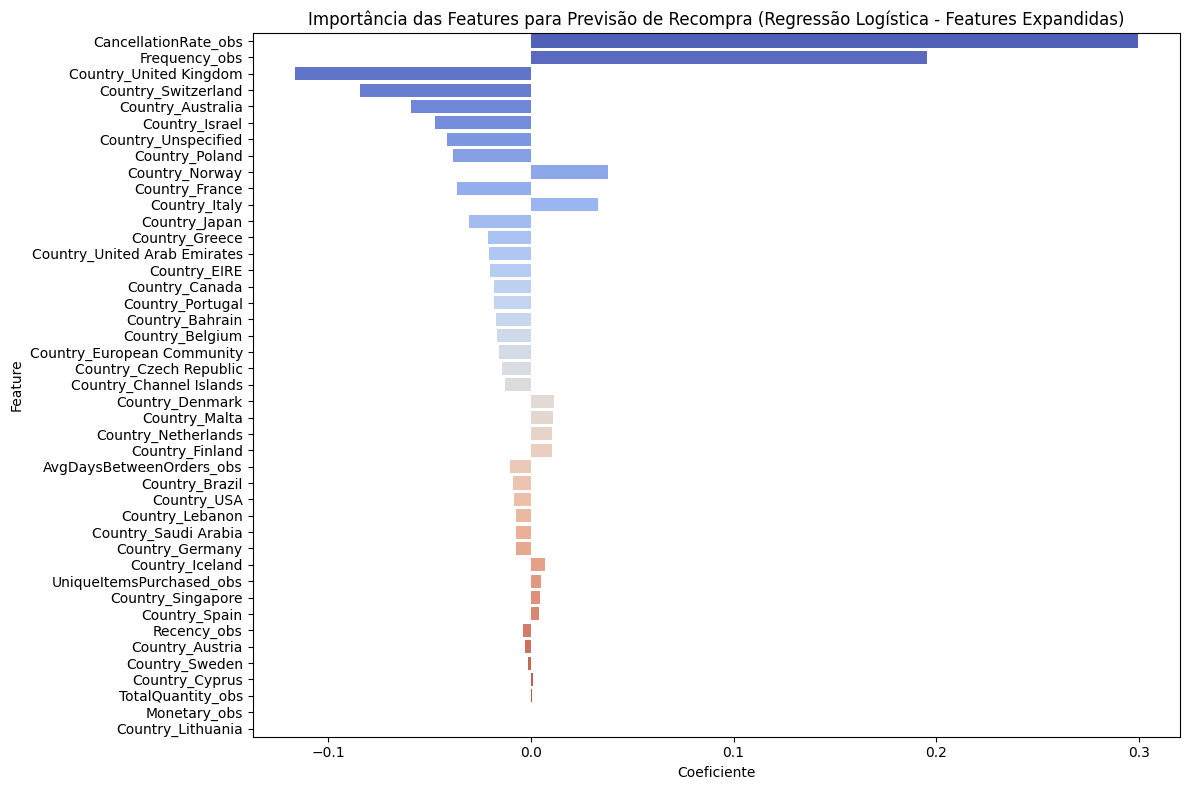


Features selecionadas (3):
['CancellationRate_obs', 'Frequency_obs', 'Country_United Kingdom']

Shape de X_train_selected: (2923, 3)
Shape de X_test_selected: (731, 3)

Modelo de Regressão Logística (Features Selecionadas) treinado com sucesso!

Relatório de Classificação (Regressão Logística - Features Selecionadas):
              precision    recall  f1-score   support

           0       0.63      0.82      0.72       380
           1       0.72      0.48      0.58       351

    accuracy                           0.66       731
   macro avg       0.67      0.65      0.65       731
weighted avg       0.67      0.66      0.65       731

Acurácia (Regressão Logística - Selecionada): 0.6594
Precisão (Regressão Logística - Selecionada): 0.7161
Recall (Regressão Logística - Selecionada): 0.4815
F1-Score (Regressão Logística - Selecionada): 0.5758
ROC AUC Score (Regressão Logística - Selecionada): 0.7177


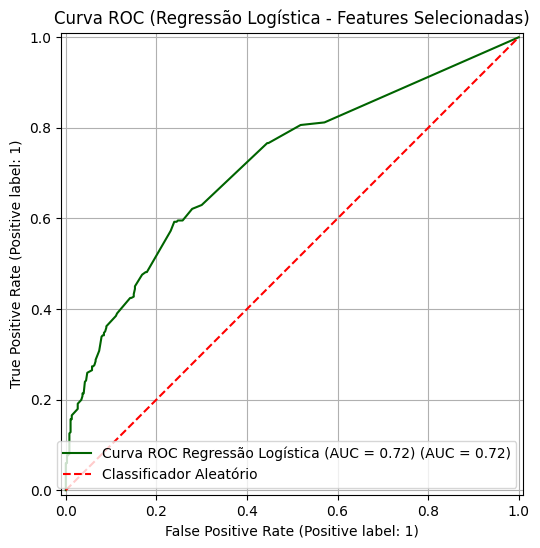

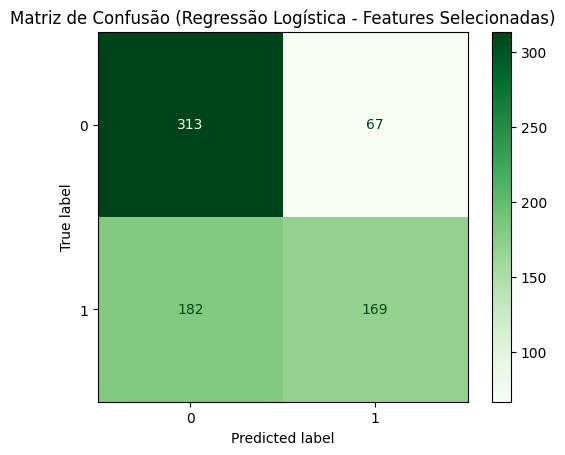

,Métrica,XGBoost,Logistic Regression (RFM),Decision Tree,Random Forest,LightGBM,Logistic Regression (Selected Features)
0,Acurácia,0.489740,0.519836,0.512996,0.492476,0.489740,0.659371
1,Precisão (Classe 1),0.467262,0.500000,0.492837,0.467320,0.468750,0.716102
2,Recall (Classe 1),0.447293,0.632479,0.490028,0.407407,0.470085,0.481481
3,F1-Score (Classe 1),0.457060,0.558491,0.491429,0.435312,0.469417,0.575809
4,ROC AUC Score,0.482381,0.527403,0.512120,0.471214,0.478040,0.717671



O melhor modelo com base no F1-Score da classe 1 é: Logistic Regression (Selected Features) com F1-Score: 0.5758


In [ ]:
# Consolidated cell to define X_new, y_new, retrain Logistic Regression, and update comparison table

# --- Steps from cell 70581f26 (creating model_df_expanded) ---
# Unir todas as novas features com o DataFrame de RFM já existente (rfm_features_observation)
expanded_features_observation = pd.merge(rfm_features_observation, observation_agg_features, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, main_country_obs, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, cancellation_features, on='ID', how='left')
expanded_features_observation = pd.merge(expanded_features_observation, avg_days_between_orders_obs, on='ID', how='left')

# Unir o conjunto de features expandido com a variável target (target_df)
model_df_expanded = pd.merge(target_df, expanded_features_observation, on='ID', how='left')

# Preencher NaNs que podem ter surgido para clientes que não tinham atividade em alguma métrica
model_df_expanded['Recency_obs'] = model_df_expanded['Recency_obs'].fillna(model_df_expanded['Recency_obs'].max() + 60)
model_df_expanded['Frequency_obs'] = model_df_expanded['Frequency_obs'].fillna(0)
model_df_expanded['Monetary_obs'] = model_df_expanded['Monetary_obs'].fillna(0)
model_df_expanded['TotalQuantity_obs'] = model_df_expanded['TotalQuantity_obs'].fillna(0)
model_df_expanded['UniqueItemsPurchased_obs'] = model_df_expanded['UniqueItemsPurchased_obs'].fillna(0)
model_df_expanded['CancellationRate_obs'] = model_df_expanded['CancellationRate_obs'].fillna(0)
model_df_expanded['AvgDaysBetweenOrders_obs'] = model_df_expanded['AvgDaysBetweenOrders_obs'].fillna(0)

# Para MainCountry_obs, preencher com um valor 'Unknown' ou o país mais comum se houver NaNs
model_df_expanded['MainCountry_obs'] = model_df_expanded['MainCountry_obs'].fillna('Unknown')

# --- Steps from cell 702be246 (One-Hot Encoding and X_new/y_new definition) ---
# One-Hot Encoding para 'MainCountry_obs'
model_df_expanded = pd.get_dummies(model_df_expanded, columns=['MainCountry_obs'], prefix='Country', dummy_na=False)

# Definir as features (X_new) e a variável target (y_new)
# Excluir 'ID' e 'Repurchase_60_Days'
X_new = model_df_expanded.drop(columns=['ID', 'Repurchase_60_Days'])
y_new = model_df_expanded['Repurchase_60_Days']

# 2. Retrain the Logistic Regression model with expanded features
logistic_model_expanded = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)

# Ensure X_train_new and y_train_new are available by re-splitting data
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new, y_new, test_size=0.2, random_state=42, stratify=y_new)
logistic_model_expanded.fit(X_train_new, y_train_new)

# 3. Define feature_importances_logistic_expanded
feature_importances_logistic_expanded = pd.DataFrame({
    'Feature': X_new.columns,
    'Coefficient': logistic_model_expanded.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Importância das Features (Coeficientes da Regressão Logística com Features Expandidas):")
display(feature_importances_logistic_expanded)

# Optional: Plot feature importances (from cell ec07ebed)
plt.figure(figsize=(12, 8))
sns.barplot(x='Coefficient', y='Feature', data=feature_importances_logistic_expanded.reindex(feature_importances_logistic_expanded['Coefficient'].abs().sort_values(ascending=False).index), palette='coolwarm')
plt.title('Importância das Features para Previsão de Recompra (Regressão Logística - Features Expandidas)')
plt.xlabel('Coeficiente')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# 4. Select features based on importance (from cell bf5862c1)
selected_features_df = feature_importances_logistic_expanded[feature_importances_logistic_expanded['Coefficient'].abs() > 0.1]
selected_feature_names = selected_features_df['Feature'].tolist()

print(f"\nFeatures selecionadas ({len(selected_feature_names)}):\n{selected_feature_names}")

X_final_selected = X_new[selected_feature_names]
y_final_selected = y_new

X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(X_final_selected, y_final_selected, test_size=0.2, random_state=42, stratify=y_final_selected)

print(f"\nShape de X_train_selected: {X_train_selected.shape}")
print(f"Shape de X_test_selected: {X_test_selected.shape}")

# 5. Train new Logistic Regression model with selected features (from cell 203e1cc7)
logistic_model_selected = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model_selected.fit(X_train_selected, y_train_selected)

print("\nModelo de Regressão Logística (Features Selecionadas) treinado com sucesso!")

y_pred_logistic_selected = logistic_model_selected.predict(X_test_selected)
y_pred_proba_logistic_selected = logistic_model_selected.predict_proba(X_test_selected)[:, 1]

print("\nRelatório de Classificação (Regressão Logística - Features Selecionadas):")
print(classification_report(y_test_selected, y_pred_logistic_selected))

accuracy_logistic_selected = accuracy_score(y_test_selected, y_pred_logistic_selected)
precision_logistic_selected = precision_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
recall_logistic_selected = recall_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
f1_logistic_selected = f1_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
roc_auc_logistic_selected = roc_auc_score(y_test_selected, y_pred_proba_logistic_selected)

print(f"Acurácia (Regressão Logística - Selecionada): {accuracy_logistic_selected:.4f}")
print(f"Precisão (Regressão Logística - Selecionada): {precision_logistic_selected:.4f}")
print(f"Recall (Regressão Logística - Selecionada): {recall_logistic_selected:.4f}")
print(f"F1-Score (Regressão Logística - Selecionada): {f1_logistic_selected:.4f}")
print(f"ROC AUC Score (Regressão Logística - Selecionada): {roc_auc_logistic_selected:.4f}")

# Optional: Plot ROC Curve and Confusion Matrix (from cell 203e1cc7)
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(logistic_model_selected, X_test_selected, y_test_selected, ax=ax, name=f'Curva ROC Regressão Logística (AUC = {roc_auc_logistic_selected:.2f})', color='darkgreen')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Regressão Logística - Features Selecionadas)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_logistic_selected = confusion_matrix(y_test_selected, y_pred_logistic_selected)
disp_logistic_selected = ConfusionMatrixDisplay(confusion_matrix=cm_logistic_selected, display_labels=logistic_model_selected.classes_)
disp_logistic_selected.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (Regressão Logística - Features Selecionadas)')
plt.show()

# 6. Update the overall model comparison table (from cell 345edab5)
overall_model_comparison_final_updated = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)', 'ROC AUC Score'],
    'XGBoost': [
        accuracy_xgb_final,
        precision_xgb_final,
        recall_xgb_final,
        f1_xgb_final,
        roc_auc_xgb_final
    ],
    'Logistic Regression (RFM)': [
        accuracy_logistic_final,
        precision_logistic_final,
        recall_logistic_final,
        f1_logistic_final,
        roc_auc_logistic_final
    ],
    'Decision Tree': [
        accuracy_dtc_final,
        precision_dtc_final,
        recall_dtc_final,
        f1_dtc_final,
        roc_auc_dtc_final
    ],
    'Random Forest': [
        accuracy_rf_final,
        precision_rf_final,
        recall_rf_final,
        f1_rf_final,
        roc_auc_rf_final
    ],
    'LightGBM': [
        accuracy_lgbm_final,
        precision_lgbm_final,
        recall_lgbm_final,
        f1_lgbm_final,
        roc_auc_lgbm_final
    ],
    'Logistic Regression (Selected Features)': [
        accuracy_logistic_selected,
        precision_logistic_selected,
        recall_logistic_selected,
        f1_logistic_selected,
        roc_auc_logistic_selected
    ]
})

display(overall_model_comparison_final_updated)

best_f1_model_updated = overall_model_comparison_final_updated.loc[overall_model_comparison_final_updated['Métrica'] == 'F1-Score (Classe 1)'].iloc[0]

best_model_name_updated = best_f1_model_updated.drop('Métrica').idxmax()
best_f1_score_updated = best_f1_model_updated.drop('Métrica').max()

print(f"\nO melhor modelo com base no F1-Score da classe 1 é: {best_model_name_updated} com F1-Score: {best_f1_score_updated:.4f}")

In [ ]:
# Criar um DataFrame para comparação dos modelos com features expandidas
overall_model_comparison_expanded = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)', 'ROC AUC Score'],
    'Logistic Regression': [
        accuracy_logistic_expanded,
        precision_logistic_expanded,
        recall_logistic_expanded,
        f1_logistic_expanded,
        roc_auc_logistic_expanded
    ],
    'Random Forest': [
        accuracy_rf_expanded,
        precision_rf_expanded,
        recall_rf_expanded,
        f1_rf_expanded,
        roc_auc_rf_expanded
    ],
    'Decision Tree': [
        accuracy_dtc_expanded,
        precision_dtc_expanded,
        recall_dtc_expanded,
        f1_dtc_expanded,
        roc_auc_dtc_expanded
    ],
    'LightGBM': [
        accuracy_lgbm_expanded,
        precision_lgbm_expanded,
        recall_lgbm_expanded,
        f1_lgbm_expanded,
        roc_auc_lgbm_expanded
    ]
})

display(overall_model_comparison_expanded)

# Determinar qual modelo é melhor com base no F1-Score da classe positiva
best_f1_model_expanded = overall_model_comparison_expanded.loc[overall_model_comparison_expanded['Métrica'] == 'F1-Score (Classe 1)'].iloc[0]

best_model_name_expanded = best_f1_model_expanded.drop('Métrica').idxmax()
best_f1_score_expanded = best_f1_model_expanded.drop('Métrica').max()

print(f"\nO melhor modelo com base no F1-Score da classe 1 é: {best_model_name_expanded} com F1-Score: {best_f1_score_expanded:.4f}")

,Métrica,Logistic Regression,Random Forest,Decision Tree,LightGBM
0,Acurácia,0.671683,0.653899,0.567715,0.636115
1,Precisão (Classe 1),0.697509,0.665541,0.551929,0.641196
2,Recall (Classe 1),0.558405,0.561254,0.529915,0.549858
3,F1-Score (Classe 1),0.620253,0.608964,0.540698,0.592025
4,ROC AUC Score,0.728138,0.704127,0.566273,0.693530



O melhor modelo com base no F1-Score da classe 1 é: Logistic Regression com F1-Score: 0.6203


In [ ]:
display(prioritized_customers_logistic[['ID', 'Recency_obs', 'Frequency_obs', 'Monetary_obs', 'Repurchase_Probability_Logistic', 'Repurchase_60_Days']].head(10))

,ID,Recency_obs,Frequency_obs,Monetary_obs,Repurchase_Probability_Logistic,Repurchase_60_Days
62,14911.0,0,133,78552.24,1.0,1
43,12748.0,1,143,17826.19,1.0,1
225,13089.0,3,77,40195.24,1.0,1
66,17841.0,3,94,25476.99,1.0,1
822,14646.0,4,41,44237.97,1.0,1
7,15311.0,3,72,20656.71,1.0,1
192,14156.0,10,37,36795.89,1.0,1
87,14606.0,0,78,9334.36,1.0,1
672,14298.0,11,37,34226.85,1.0,1
160,12971.0,5,67,7518.17,1.0,1


## Etapa 3 de testes: novas features

In [ ]:
df_prediction = df[df['InvoiceDate'] > prediction_window_start]
customers_repurchased = df_prediction['CustomerID'].unique()
all_customers_observation = df_observation['CustomerID'].unique()

target_df = pd.DataFrame({'CustomerID': all_customers_observation})
target_df['Repurchase_60_Days'] = target_df['CustomerID'].isin(customers_repurchased).astype(int)
target_df.rename(columns={'CustomerID': 'ID'}, inplace=True)

X_final = customer_aggregated_features.drop(columns=['ID'])
y_final = target_df['Repurchase_60_Days']

print(f"Shape de X_final: {X_final.shape}")
print(f"Shape de y_final: {y_final.shape}")
display(target_df.head())

Shape de X_final: (3654, 5)
Shape de y_final: (3654,)


,ID,Repurchase_60_Days
0,17850.0,0
1,13047.0,1
2,12583.0,1
3,15100.0,0
4,15291.0,1


In [ ]:
# Calculate the latest date in the dataset from the full df
latest_date = df['InvoiceDate'].max()

# Define the cut-off date for the observation window (last 60 days for forecasting)
prediction_window_start = latest_date - pd.DateOffset(days=60)

# Create the DataFrame for the observation window (features)
df_observation = df[df['InvoiceDate'] <= prediction_window_start]

# Criação de variáveis por cliente: recência, frequência, valor monetário, num de pedidos, qnt de itens, diversidade de produtos
latest_date_customer_features = df_observation['InvoiceDate'].max()

customer_aggregated_features = df_observation.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda date: (latest_date_customer_features - date.max()).days),
    Frequency=('InvoiceNo', 'nunique'), # Número de pedidos únicos
    Monetary=('Revenue', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    UniqueItems=('StockCode', 'nunique') # Diversidade de produtos
).reset_index()

customer_aggregated_features.rename(columns={'CustomerID': 'ID'}, inplace=True)

display(customer_aggregated_features.head())

,ID,Recency,Frequency,Monetary,TotalQuantity,UniqueItems
0,12347.0,69,5,2541.26,1350,81
1,12348.0,188,3,200.60,236,8
2,12350.0,249,1,294.40,196,16
3,12352.0,11,6,1154.01,401,45
4,12353.0,143,1,89.00,20,4


In [ ]:
X_final = customer_aggregated_features.drop(columns=['ID'])
y_final = target_df['Repurchase_60_Days']

# Dividir os dados em conjuntos de treino e teste
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X_final, y_final, test_size=0.2, random_state=42, stratify=y_final)

print(f"Shape de X_train_final: {X_train_final.shape}\n")
print(f"Shape de X_test_final: {X_test_final.shape}\n")
print(f"Distribuição de y_train_final:\n{y_train_final.value_counts(normalize=True)}\n ")
print(f"Distribuição de y_test_final:\n{y_test_final.value_counts(normalize=True)}\n")

Shape de X_train_final: (2923, 5)

Shape de X_test_final: (731, 5)

Distribuição de y_train_final:
Repurchase_60_Days
0    0.519329
1    0.480671
Name: proportion, dtype: float64
 
Distribuição de y_test_final:
Repurchase_60_Days
0    0.519836
1    0.480164
Name: proportion, dtype: float64



### Regressão Logística (Modelo Final com Features Agregadas)


### Regressão Logística ###
Modelo de Regressão Logística treinado com sucesso!

Relatório de Classificação (Regressão Logística):
              precision    recall  f1-score   support

           0       0.55      0.42      0.47       380
           1       0.50      0.63      0.56       351

    accuracy                           0.52       731
   macro avg       0.53      0.52      0.52       731
weighted avg       0.53      0.52      0.51       731

Acurácia (Regressão Logística): 0.5198
Precisão (Regressão Logística): 0.5000
Recall (Regressão Logística): 0.6325
F1-Score (Regressão Logística): 0.5585
ROC AUC Score (Regressão Logística): 0.5274


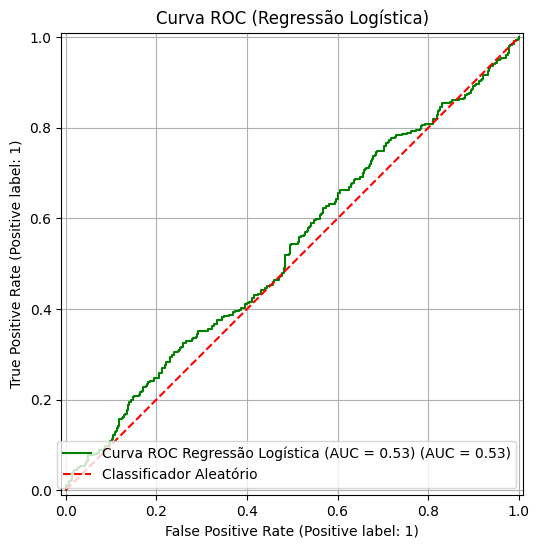

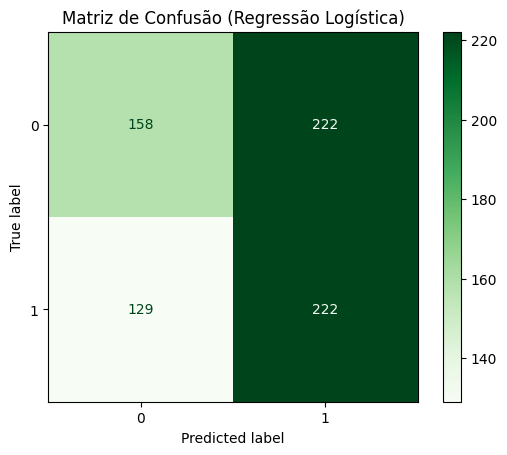

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("\n### Regressão Logística ###")
logistic_model_final = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model_final.fit(X_train_final, y_train_final)

print("Modelo de Regressão Logística treinado com sucesso!")

y_pred_logistic_final = logistic_model_final.predict(X_test_final)
y_pred_proba_logistic_final = logistic_model_final.predict_proba(X_test_final)[:, 1]

print("\nRelatório de Classificação (Regressão Logística):")
print(classification_report(y_test_final, y_pred_logistic_final))

accuracy_logistic_final = accuracy_score(y_test_final, y_pred_logistic_final)
precision_logistic_final = precision_score(y_test_final, y_pred_logistic_final, pos_label=1)
recall_logistic_final = recall_score(y_test_final, y_pred_logistic_final, pos_label=1)
f1_logistic_final = f1_score(y_test_final, y_pred_logistic_final, pos_label=1)
roc_auc_logistic_final = roc_auc_score(y_test_final, y_pred_proba_logistic_final)

print(f"Acurácia (Regressão Logística): {accuracy_logistic_final:.4f}")
print(f"Precisão (Regressão Logística): {precision_logistic_final:.4f}")
print(f"Recall (Regressão Logística): {recall_logistic_final:.4f}")
print(f"F1-Score (Regressão Logística): {f1_logistic_final:.4f}")
print(f"ROC AUC Score (Regressão Logística): {roc_auc_logistic_final:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(logistic_model_final, X_test_final, y_test_final, ax=ax, name=f'Curva ROC Regressão Logística (AUC = {roc_auc_logistic_final:.2f})', color='green')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Regressão Logística)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_logistic_final = confusion_matrix(y_test_final, y_pred_logistic_final)
disp_logistic_final = ConfusionMatrixDisplay(confusion_matrix=cm_logistic_final, display_labels=logistic_model_final.classes_)
disp_logistic_final.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (Regressão Logística)')
plt.show()

### Árvore de Decisão (Modelo Final com Features Agregadas)


### Árvore de Decisão ###
Modelo de Árvore de Decisão treinado com sucesso!

Relatório de Classificação (Árvore de Decisão):
              precision    recall  f1-score   support

           0       0.53      0.53      0.53       380
           1       0.49      0.49      0.49       351

    accuracy                           0.51       731
   macro avg       0.51      0.51      0.51       731
weighted avg       0.51      0.51      0.51       731

Acurácia (Árvore de Decisão): 0.5130
Precisão (Árvore de Decisão): 0.4928
Recall (Árvore de Decisão): 0.4900
F1-Score (Árvore de Decisão): 0.4914
ROC AUC Score (Árvore de Decisão): 0.5121


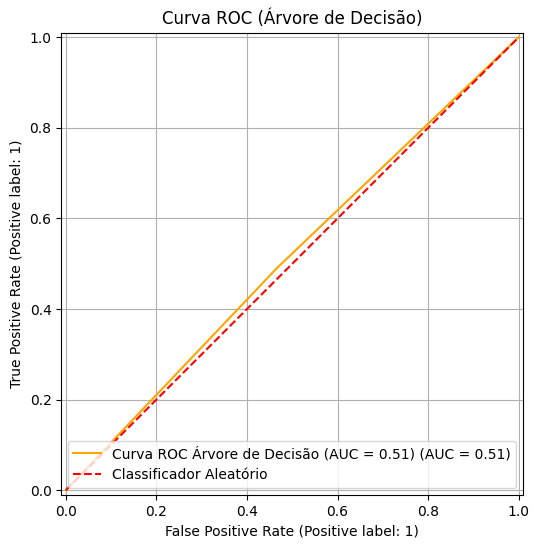

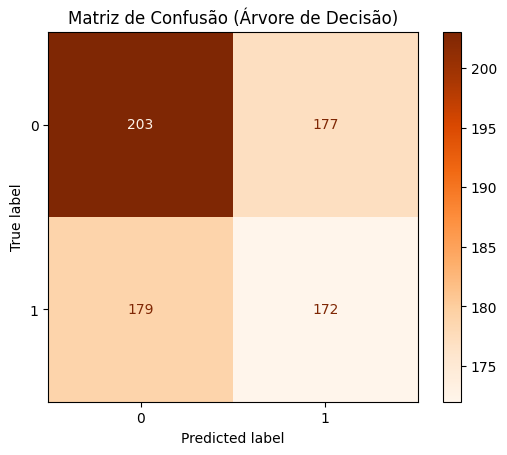

In [ ]:
from sklearn.tree import DecisionTreeClassifier

print("\n### Árvore de Decisão ###")
dtc_model_final = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dtc_model_final.fit(X_train_final, y_train_final)

print("Modelo de Árvore de Decisão treinado com sucesso!")

y_pred_dtc_final = dtc_model_final.predict(X_test_final)
y_pred_proba_dtc_final = dtc_model_final.predict_proba(X_test_final)[:, 1]

print("\nRelatório de Classificação (Árvore de Decisão):")
print(classification_report(y_test_final, y_pred_dtc_final))

accuracy_dtc_final = accuracy_score(y_test_final, y_pred_dtc_final)
precision_dtc_final = precision_score(y_test_final, y_pred_dtc_final, pos_label=1)
recall_dtc_final = recall_score(y_test_final, y_pred_dtc_final, pos_label=1)
f1_dtc_final = f1_score(y_test_final, y_pred_dtc_final, pos_label=1)
roc_auc_dtc_final = roc_auc_score(y_test_final, y_pred_proba_dtc_final)

print(f"Acurácia (Árvore de Decisão): {accuracy_dtc_final:.4f}")
print(f"Precisão (Árvore de Decisão): {precision_dtc_final:.4f}")
print(f"Recall (Árvore de Decisão): {recall_dtc_final:.4f}")
print(f"F1-Score (Árvore de Decisão): {f1_dtc_final:.4f}")
print(f"ROC AUC Score (Árvore de Decisão): {roc_auc_dtc_final:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(dtc_model_final, X_test_final, y_test_final, ax=ax, name=f'Curva ROC Árvore de Decisão (AUC = {roc_auc_dtc_final:.2f})', color='orange')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Árvore de Decisão)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_dtc_final = confusion_matrix(y_test_final, y_pred_dtc_final)
disp_dtc_final = ConfusionMatrixDisplay(confusion_matrix=cm_dtc_final, display_labels=dtc_model_final.classes_)
disp_dtc_final.plot(cmap=plt.cm.Oranges)
plt.title('Matriz de Confusão (Árvore de Decisão)')
plt.show()

### Random Forest (Modelo Final com Features Agregadas)


### Random Forest ###
Modelo Random Forest treinado com sucesso!

Relatório de Classificação (Random Forest):
              precision    recall  f1-score   support

           0       0.51      0.57      0.54       380
           1       0.47      0.41      0.44       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia (Random Forest): 0.4925
Precisão (Random Forest): 0.4673
Recall (Random Forest): 0.4074
F1-Score (Random Forest): 0.4353
ROC AUC Score (Random Forest): 0.4712


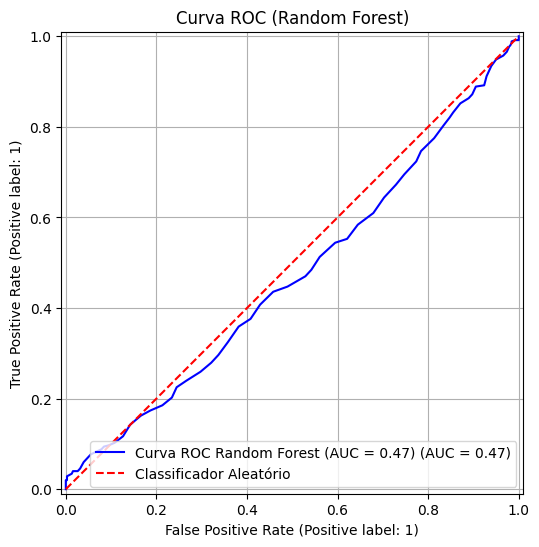

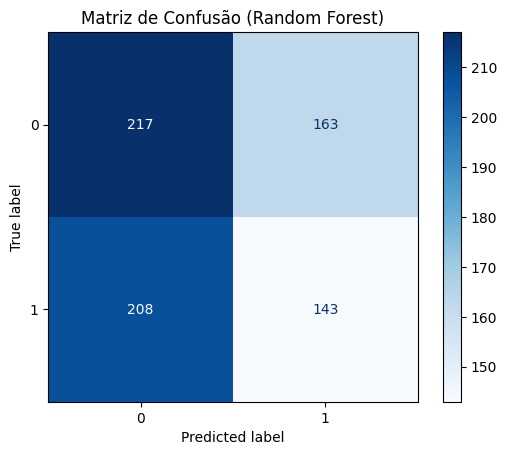

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("\n### Random Forest ###")
rf_model_final = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model_final.fit(X_train_final, y_train_final)

print("Modelo Random Forest treinado com sucesso!")

y_pred_rf_final = rf_model_final.predict(X_test_final)
y_pred_proba_rf_final = rf_model_final.predict_proba(X_test_final)[:, 1]

print("\nRelatório de Classificação (Random Forest):")
print(classification_report(y_test_final, y_pred_rf_final))

accuracy_rf_final = accuracy_score(y_test_final, y_pred_rf_final)
precision_rf_final = precision_score(y_test_final, y_pred_rf_final, pos_label=1)
recall_rf_final = recall_score(y_test_final, y_pred_rf_final, pos_label=1)
f1_rf_final = f1_score(y_test_final, y_pred_rf_final, pos_label=1)
roc_auc_rf_final = roc_auc_score(y_test_final, y_pred_proba_rf_final)

print(f"Acurácia (Random Forest): {accuracy_rf_final:.4f}")
print(f"Precisão (Random Forest): {precision_rf_final:.4f}")
print(f"Recall (Random Forest): {recall_rf_final:.4f}")
print(f"F1-Score (Random Forest): {f1_rf_final:.4f}")
print(f"ROC AUC Score (Random Forest): {roc_auc_rf_final:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(rf_model_final, X_test_final, y_test_final, ax=ax, name=f'Curva ROC Random Forest (AUC = {roc_auc_rf_final:.2f})', color='blue')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Random Forest)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_rf_final = confusion_matrix(y_test_final, y_pred_rf_final)
disp_rf_final = ConfusionMatrixDisplay(confusion_matrix=cm_rf_final, display_labels=rf_model_final.classes_)
disp_rf_final.plot(cmap=plt.cm.Blues)
plt.title('Matriz de Confusão (Random Forest)')
plt.show()

### LightGBM (Gradient Boosting - Modelo Final com Features Agregadas)


### LightGBM ###
[LightGBM] [Info] Number of positive: 1405, number of negative: 1518
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000271 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1014
[LightGBM] [Info] Number of data points in the train set: 2923, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.480671 -> initscore=-0.077356
[LightGBM] [Info] Start training from score -0.077356
Modelo LightGBM treinado com sucesso!

Relatório de Classificação (LightGBM):
              precision    recall  f1-score   support

           0       0.51      0.51      0.51       380
           1       0.47      0.47      0.47       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia (LightGBM): 0.4897
Precisão (LightGBM): 0.4688
Recall (LightGBM): 0.4701
F1-Sc

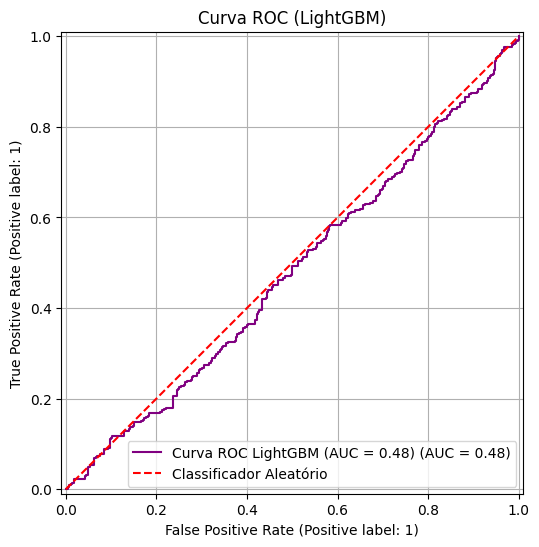

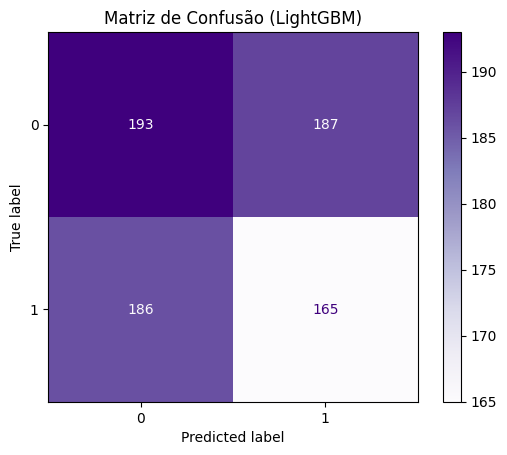

In [ ]:
import lightgbm as lgb

print("\n### LightGBM ###")
lgbm_model_final = lgb.LGBMClassifier(objective='binary', random_state=42, is_unbalance=True)
lgbm_model_final.fit(X_train_final, y_train_final)

print("Modelo LightGBM treinado com sucesso!")

y_pred_lgbm_final = lgbm_model_final.predict(X_test_final)
y_pred_proba_lgbm_final = lgbm_model_final.predict_proba(X_test_final)[:, 1]

print("\nRelatório de Classificação (LightGBM):")
print(classification_report(y_test_final, y_pred_lgbm_final))

accuracy_lgbm_final = accuracy_score(y_test_final, y_pred_lgbm_final)
precision_lgbm_final = precision_score(y_test_final, y_pred_lgbm_final, pos_label=1)
recall_lgbm_final = recall_score(y_test_final, y_pred_lgbm_final, pos_label=1)
f1_lgbm_final = f1_score(y_test_final, y_pred_lgbm_final, pos_label=1)
roc_auc_lgbm_final = roc_auc_score(y_test_final, y_pred_proba_lgbm_final)

print(f"Acurácia (LightGBM): {accuracy_lgbm_final:.4f}")
print(f"Precisão (LightGBM): {precision_lgbm_final:.4f}")
print(f"Recall (LightGBM): {recall_lgbm_final:.4f}")
print(f"F1-Score (LightGBM): {f1_lgbm_final:.4f}")
print(f"ROC AUC Score (LightGBM): {roc_auc_lgbm_final:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(lgbm_model_final, X_test_final, y_test_final, ax=ax, name=f'Curva ROC LightGBM (AUC = {roc_auc_lgbm_final:.2f})', color='purple')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (LightGBM)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_lgbm_final = confusion_matrix(y_test_final, y_pred_lgbm_final)
disp_lgbm_final = ConfusionMatrixDisplay(confusion_matrix=cm_lgbm_final, display_labels=lgbm_model_final.classes_)
disp_lgbm_final.plot(cmap=plt.cm.Purples)
plt.title('Matriz de Confusão (LightGBM)')
plt.show()


### XGBoost ###
Modelo XGBoost treinado com sucesso!

Relatório de Classificação (XGBoost):
              precision    recall  f1-score   support

           0       0.51      0.53      0.52       380
           1       0.47      0.45      0.46       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia (XGBoost): 0.4897
Precisão (XGBoost): 0.4673
Recall (XGBoost): 0.4473
F1-Score (XGBoost): 0.4571
ROC AUC Score (XGBoost): 0.4824


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:17:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


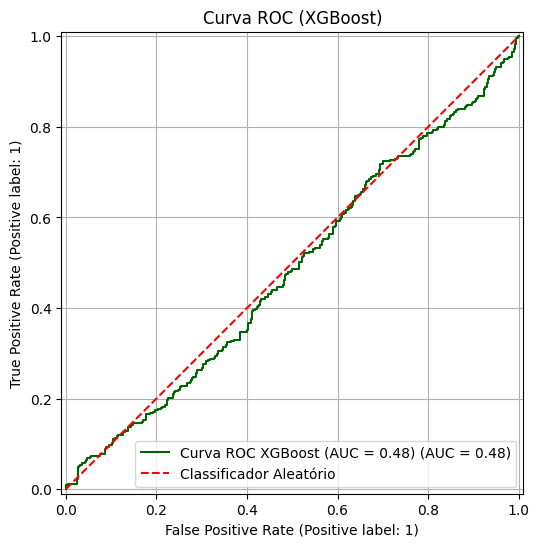

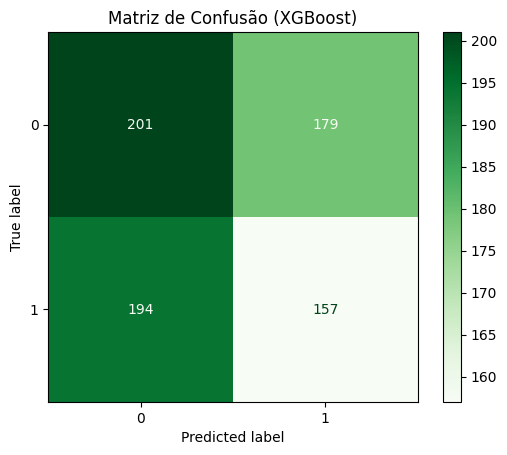

In [ ]:
import xgboost as xgb

print("\n### XGBoost ###")
xgb_model_final = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42, scale_pos_weight=len(y_train_final[y_train_final == 0]) / len(y_train_final[y_train_final == 1]))
xgb_model_final.fit(X_train_final, y_train_final)

print("Modelo XGBoost treinado com sucesso!")

y_pred_xgb_final = xgb_model_final.predict(X_test_final)
y_pred_proba_xgb_final = xgb_model_final.predict_proba(X_test_final)[:, 1]

print("\nRelatório de Classificação (XGBoost):")
print(classification_report(y_test_final, y_pred_xgb_final))

accuracy_xgb_final = accuracy_score(y_test_final, y_pred_xgb_final)
precision_xgb_final = precision_score(y_test_final, y_pred_xgb_final, pos_label=1)
recall_xgb_final = recall_score(y_test_final, y_pred_xgb_final, pos_label=1)
f1_xgb_final = f1_score(y_test_final, y_pred_xgb_final, pos_label=1)
roc_auc_xgb_final = roc_auc_score(y_test_final, y_pred_proba_xgb_final)

print(f"Acurácia (XGBoost): {accuracy_xgb_final:.4f}")
print(f"Precisão (XGBoost): {precision_xgb_final:.4f}")
print(f"Recall (XGBoost): {recall_xgb_final:.4f}")
print(f"F1-Score (XGBoost): {f1_xgb_final:.4f}")
print(f"ROC AUC Score (XGBoost): {roc_auc_xgb_final:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(xgb_model_final, X_test_final, y_test_final, ax=ax, name=f'Curva ROC XGBoost (AUC = {roc_auc_xgb_final:.2f})', color='darkgreen')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (XGBoost)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

cm_xgb_final = confusion_matrix(y_test_final, y_pred_xgb_final)
disp_xgb_final = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_final, display_labels=xgb_model_final.classes_)
disp_xgb_final.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (XGBoost)')
plt.show()

### Comparativo Final dos Modelos com Features Agregadas

In [ ]:
overall_model_comparison_final = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)', 'ROC AUC Score'],
    'XGBoost': [
        accuracy_xgb_final,
        precision_xgb_final,
        recall_xgb_final,
        f1_xgb_final,
        roc_auc_xgb_final
    ],
    'Logistic Regression': [
        accuracy_logistic_final,
        precision_logistic_final,
        recall_logistic_final,
        f1_logistic_final,
        roc_auc_logistic_final
    ],
    'Decision Tree': [
        accuracy_dtc_final,
        precision_dtc_final,
        recall_dtc_final,
        f1_dtc_final,
        roc_auc_dtc_final
    ],
    'Random Forest': [
        accuracy_rf_final,
        precision_rf_final,
        recall_rf_final,
        f1_rf_final,
        roc_auc_rf_final
    ],
    'LightGBM': [
        accuracy_lgbm_final,
        precision_lgbm_final,
        recall_lgbm_final,
        f1_lgbm_final,
        roc_auc_lgbm_final
    ]
})

display(overall_model_comparison_final)

best_f1_model_final = overall_model_comparison_final.loc[overall_model_comparison_final['Métrica'] == 'F1-Score (Classe 1)'].iloc[0]

best_model_name_final = best_f1_model_final.drop('Métrica').idxmax()
best_f1_score_final = best_f1_model_final.drop('Métrica').max()

print(f"\nO melhor modelo com base no F1-Score da classe 1 é: {best_model_name_final} com F1-Score: {best_f1_score_final:.4f}")

,Métrica,XGBoost,Logistic Regression,Decision Tree,Random Forest,LightGBM
0,Acurácia,0.489740,0.519836,0.512996,0.492476,0.489740
1,Precisão (Classe 1),0.467262,0.500000,0.492837,0.467320,0.468750
2,Recall (Classe 1),0.447293,0.632479,0.490028,0.407407,0.470085
3,F1-Score (Classe 1),0.457060,0.558491,0.491429,0.435312,0.469417
4,ROC AUC Score,0.482381,0.527403,0.512120,0.471214,0.478040



O melhor modelo com base no F1-Score da classe 1 é: Logistic Regression com F1-Score: 0.5585


### Seleção de Variáveis Melhorada

Com base nas importâncias das features (coeficientes) da Regressão Logística com features expandidas, podemos fazer uma seleção de variáveis para simplificar o modelo e potencialmente melhorar o desempenho, focando nos fatores mais relevantes.

Vamos identificar as features com os maiores valores absolutos de coeficientes para incluí-las no modelo.

In [ ]:
# Filtrar as features com base na importância (valor absoluto do coeficiente)
# Vamos usar um limiar para selecionar as features mais impactantes.
# Por exemplo, selecionaremos features com valor absoluto do coeficiente maior que 0.1.
selected_features_df = feature_importances_logistic_expanded[feature_importances_logistic_expanded['Coefficient'].abs() > 0.1]
selected_feature_names = selected_features_df['Feature'].tolist()

print(f"Features selecionadas ({len(selected_feature_names)}):\n{selected_feature_names}")

# Criar o novo conjunto de features (X_final_selected)
X_final_selected = X_new[selected_feature_names]
y_final_selected = y_new

# Dividir os dados em conjuntos de treino e teste com as features selecionadas
X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(X_final_selected, y_final_selected, test_size=0.2, random_state=42, stratify=y_final_selected)

print(f"\nShape de X_train_selected: {X_train_selected.shape}")
print(f"Shape de X_test_selected: {X_test_selected.shape}")

Features selecionadas (3):
['CancellationRate_obs', 'Frequency_obs', 'Country_United Kingdom']

Shape de X_train_selected: (2923, 3)
Shape de X_test_selected: (731, 3)


Com as variáveis selecionadas, vamos treinar e avaliar um novo modelo de Regressão Logística para ver como a performance se compara.

Modelo de Regressão Logística (Features Selecionadas) treinado com sucesso!

Relatório de Classificação (Regressão Logística - Features Selecionadas):
              precision    recall  f1-score   support

           0       0.63      0.82      0.72       380
           1       0.72      0.48      0.58       351

    accuracy                           0.66       731
   macro avg       0.67      0.65      0.65       731
weighted avg       0.67      0.66      0.65       731

Acurácia (Regressão Logística - Selecionada): 0.6594
Precisão (Regressão Logística - Selecionada): 0.7161
Recall (Regressão Logística - Selecionada): 0.4815
F1-Score (Regressão Logística - Selecionada): 0.5758
ROC AUC Score (Regressão Logística - Selecionada): 0.7177


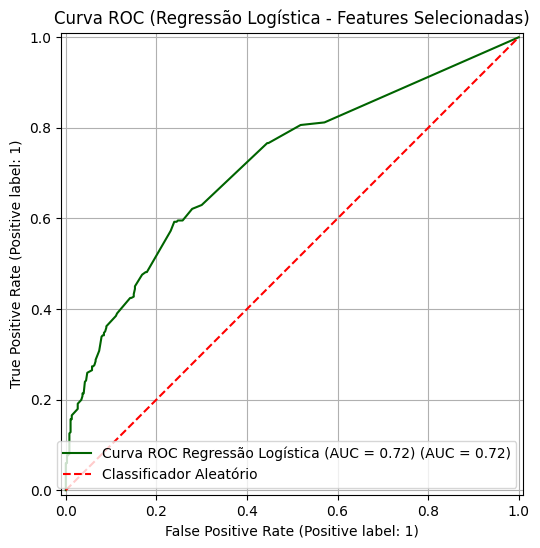

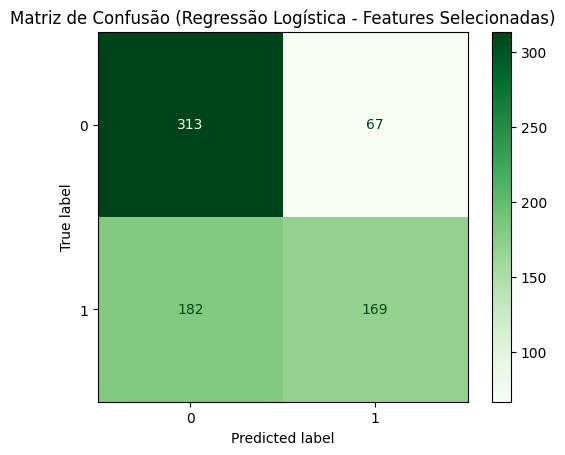

In [ ]:
# Treinar o modelo de Regressão Logística com as features selecionadas
logistic_model_selected = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', max_iter=1000)
logistic_model_selected.fit(X_train_selected, y_train_selected)

print("Modelo de Regressão Logística (Features Selecionadas) treinado com sucesso!")

# Fazer previsões no conjunto de teste
y_pred_logistic_selected = logistic_model_selected.predict(X_test_selected)
y_pred_proba_logistic_selected = logistic_model_selected.predict_proba(X_test_selected)[:, 1]

# Avaliar a performance do modelo
print("\nRelatório de Classificação (Regressão Logística - Features Selecionadas):")
print(classification_report(y_test_selected, y_pred_logistic_selected))

accuracy_logistic_selected = accuracy_score(y_test_selected, y_pred_logistic_selected)
precision_logistic_selected = precision_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
recall_logistic_selected = recall_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
f1_logistic_selected = f1_score(y_test_selected, y_pred_logistic_selected, pos_label=1)
roc_auc_logistic_selected = roc_auc_score(y_test_selected, y_pred_proba_logistic_selected)

print(f"Acurácia (Regressão Logística - Selecionada): {accuracy_logistic_selected:.4f}")
print(f"Precisão (Regressão Logística - Selecionada): {precision_logistic_selected:.4f}")
print(f"Recall (Regressão Logística - Selecionada): {recall_logistic_selected:.4f}")
print(f"F1-Score (Regressão Logística - Selecionada): {f1_logistic_selected:.4f}")
print(f"ROC AUC Score (Regressão Logística - Selecionada): {roc_auc_logistic_selected:.4f}")

# Plotar a Curva ROC
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(logistic_model_selected, X_test_selected, y_test_selected, ax=ax, name=f'Curva ROC Regressão Logística (AUC = {roc_auc_logistic_selected:.2f})', color='darkgreen')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
ax.set_title('Curva ROC (Regressão Logística - Features Selecionadas)')
ax.legend(loc='lower right')
ax.grid(True)
plt.show()

# Plotar Matriz de Confusão
cm_logistic_selected = confusion_matrix(y_test_selected, y_pred_logistic_selected)
disp_logistic_selected = ConfusionMatrixDisplay(confusion_matrix=cm_logistic_selected, display_labels=logistic_model_selected.classes_)
disp_logistic_selected.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusão (Regressão Logística - Features Selecionadas)')
plt.show()

# Conclusões

### Comparativo Final dos Modelos com Seleção de Features

In [ ]:
# Adicionar os resultados do modelo com features selecionadas à tabela comparativa
overall_model_comparison_final_updated = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão (Classe 1)', 'Recall (Classe 1)', 'F1-Score (Classe 1)', 'ROC AUC Score'],
    'XGBoost': [
        accuracy_xgb_final,
        precision_xgb_final,
        recall_xgb_final,
        f1_xgb_final,
        roc_auc_xgb_final
    ],
    'Logistic Regression (RFM)': [
        accuracy_logistic_final,
        precision_logistic_final,
        recall_logistic_final,
        f1_logistic_final,
        roc_auc_logistic_final
    ],
    'Decision Tree': [
        accuracy_dtc_final,
        precision_dtc_final,
        recall_dtc_final,
        f1_dtc_final,
        roc_auc_dtc_final
    ],
    'Random Forest': [
        accuracy_rf_final,
        precision_rf_final,
        recall_rf_final,
        f1_rf_final,
        roc_auc_rf_final
    ],
    'LightGBM': [
        accuracy_lgbm_final,
        precision_lgbm_final,
        recall_lgbm_final,
        f1_lgbm_final,
        roc_auc_lgbm_final
    ],
    'Logistic Regression (Selected Features)': [
        accuracy_logistic_selected,
        precision_logistic_selected,
        recall_logistic_selected,
        f1_logistic_selected,
        roc_auc_logistic_selected
    ]
})

display(overall_model_comparison_final_updated)

best_f1_model_updated = overall_model_comparison_final_updated.loc[overall_model_comparison_final_updated['Métrica'] == 'F1-Score (Classe 1)'].iloc[0]

best_model_name_updated = best_f1_model_updated.drop('Métrica').idxmax()
best_f1_score_updated = best_f1_model_updated.drop('Métrica').max()

print(f"\nO melhor modelo com base no F1-Score da classe 1 é: {best_model_name_updated} com F1-Score: {best_f1_score_updated:.4f}")

,Métrica,XGBoost,Logistic Regression (RFM),Decision Tree,Random Forest,LightGBM,Logistic Regression (Selected Features)
0,Acurácia,0.489740,0.519836,0.512996,0.492476,0.489740,0.659371
1,Precisão (Classe 1),0.467262,0.500000,0.492837,0.467320,0.468750,0.716102
2,Recall (Classe 1),0.447293,0.632479,0.490028,0.407407,0.470085,0.481481
3,F1-Score (Classe 1),0.457060,0.558491,0.491429,0.435312,0.469417,0.575809
4,ROC AUC Score,0.482381,0.527403,0.512120,0.471214,0.478040,0.717671



O melhor modelo com base no F1-Score da classe 1 é: Logistic Regression (Selected Features) com F1-Score: 0.5758


### Sugestão de Itens para os 50 Clientes Mais Importantes

In [ ]:
print("Gerando lista dos 50 clientes mais importantes com estimativa de ganho...")

# Calculate estimated gain: Monetary_obs * Repurchase_Probability_Logistic
# Assuming Monetary_obs can be a proxy for future spending if they repurchase
# Filter for customers with a repurchase probability > 0.5 (or a reasonable threshold)
prioritized_customers_logistic['Estimated_Gain_60_Days'] = prioritized_customers_logistic['Monetary_obs'] * prioritized_customers_logistic['Repurchase_Probability_Logistic']

# Sort by Estimated_Gain_60_Days and get the top 50
top_50_important_customers = prioritized_customers_logistic.sort_values(
    by='Estimated_Gain_60_Days', ascending=False
).head(50)

# Display the list of top 50 customers with their estimated gain
print("\nTop 50 Clientes Mais Importantes e Estimativa de Ganho (Próximos 60 Dias):")
display(top_50_important_customers[['ID', 'Monetary_obs', 'Repurchase_Probability_Logistic', 'Estimated_Gain_60_Days']])

Gerando lista dos 50 clientes mais importantes com estimativa de ganho...

Top 50 Clientes Mais Importantes e Estimativa de Ganho (Próximos 60 Dias):


,ID,Monetary_obs,Repurchase_Probability_Logistic,Estimated_Gain_60_Days
62,14911.0,78552.24,1.000000,78552.240000
822,14646.0,44237.97,1.000000,44237.969991
225,13089.0,40195.24,1.000000,40195.240000
192,14156.0,36795.89,1.000000,36795.889808
672,14298.0,34226.85,1.000000,34226.849583
14,17511.0,28270.36,0.999999,28270.317943
66,17841.0,25476.99,1.000000,25476.990000
885,12415.0,23622.53,0.999935,23620.988099
1107,14088.0,21079.83,0.999472,21068.708892
7,15311.0,20656.71,1.000000,20656.709984


In [ ]:
# Obter os CustomerIDs dos top 50 clientes
top_50_customer_ids = top_50_important_customers['ID'].tolist()

# Filtrar o DataFrame original para incluir apenas as compras desses clientes
df_top_50_customers = df[df['CustomerID'].isin(top_50_customer_ids)]

# Identificar os itens mais comprados por esses clientes
top_items_for_top_50 = df_top_50_customers.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

print("Top 10 Itens Mais Comprados Pelos 50 Clientes Mais Importantes:")
display(top_items_for_top_50.reset_index())

Top 10 Itens Mais Comprados Pelos 50 Clientes Mais Importantes:


,Description,Quantity
0,WHITE HANGING HEART T-LIGHT HOLDER,3528
1,REGENCY CAKESTAND 3 TIER,3128
2,ASSORTED COLOUR BIRD ORNAMENT,2607
3,PACK OF 72 RETROSPOT CAKE CASES,2041
4,ROSES REGENCY TEACUP AND SAUCER,2017
5,LUNCH BAG RED RETROSPOT,1973
6,PARTY BUNTING,1919
7,PAPER BUNTING RETROSPOT,1860
8,CHILLI LIGHTS,1757
9,CLOTHES PEGS RETROSPOT PACK 24,1663


Com base nesta análise, sugiro considerar a promoção ou oferta desses 10 itens que são frequentemente comprados pelos seus clientes mais valiosos. Isso pode incluir ofertas personalizadas, lançamentos de novos produtos relacionados, ou pacotes especiais com esses itens.

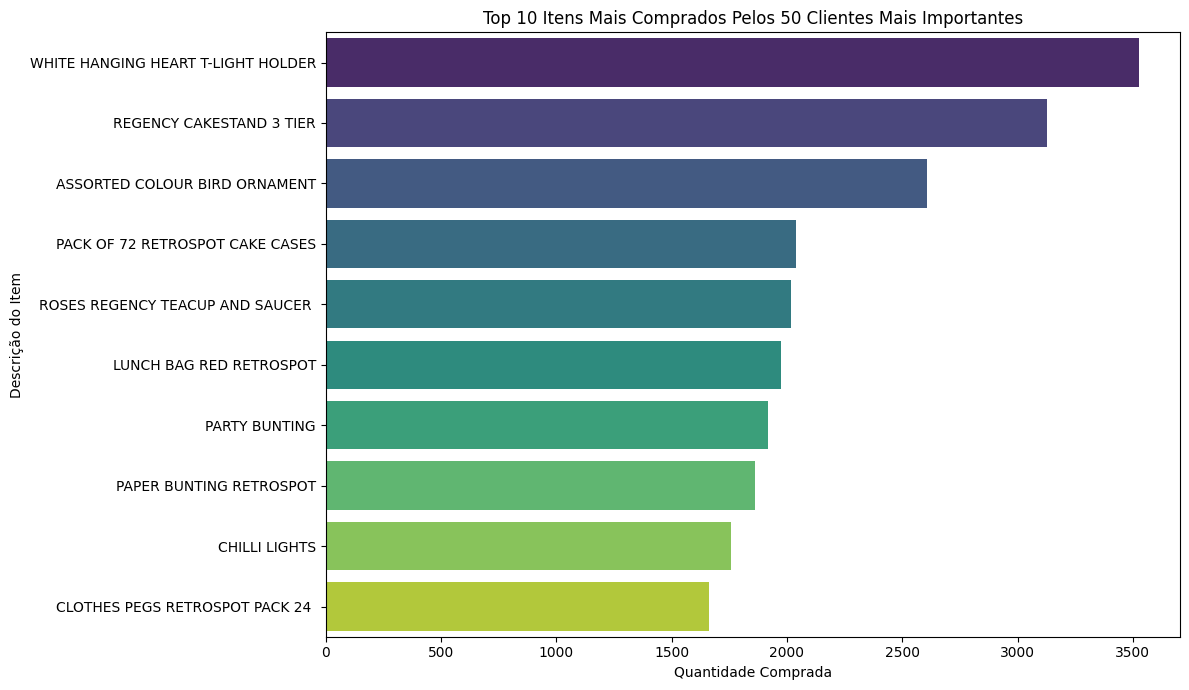

In [ ]:
# Visualizar os top 10 itens mais comprados pelos 50 clientes mais importantes
plt.figure(figsize=(12, 7))
sns.barplot(x='Quantity', y='Description', data=top_items_for_top_50.reset_index(), palette='viridis', hue='Description', legend=False)
plt.title('Top 10 Itens Mais Comprados Pelos 50 Clientes Mais Importantes')
plt.xlabel('Quantidade Comprada')
plt.ylabel('Descrição do Item')
plt.tight_layout()
plt.show()

### Sugestões de uso

- Utilização para ver quais itens são mais comprados por quais clientes (criação de lista de emails com promoções personalizadas)
- Priorização de clientes para lista de emails/mensagens
- Controle de compra de futuros itens (pois foram identificados itens que praticamente nunca são vendidos)
- Priorização de produtos por país

### Decisões metodológicas

- Exclusão dos cancelados do dataset
- Exclusão dos clientes sem id
- Treinamento de diversos modelos com uso de IA para decisão de features selecionadas
- Exclusão da geolocalização das features selecionadas devido a desbalanceamento dos dados